> **АРХИВ (13.10.2026).** Исходная версия 01 без изменений кода, кроме ячейки запуска раздела 17: `RUN_STRONG_EXPERIMENT=False`, `STRONG_PHASE="baseline"` (в загруженной версии стояло `True`/`"full"`, Run All запускал весь протокол). Сохранённые outputs — результаты старого кода. Актуальная реализация и список исправлений — `02_smt_memup_stack.ipynb`, раздел 10.

# SMT × MemUP: пилот и проверка исследовательской гипотезы

**Этап:** адаптация авторского SMT, пилотные обучения и диагностика. Воспроизведение Figure 3 в масштабе статьи и подтверждение пользы MemUP ещё не завершены.

Основная ветка — **Stack Operations без шума**. MQAR и MNIST сохранены как дополнительные пилоты; включаются отдельно. Не требуется одновременно запускать все задачи, чтобы показать первый исследовательский результат.

В исходном загруженном ноутбуке есть сохранённые outputs обучений. Ниже приводятся их результаты с явной пометкой об источнике. Checkpoints/CSV с пользовательского компьютера не приложены, поэтому их наличие и происхождение независимо здесь не проверены. Отредактированные ячейки требуют нового исполнения; их старые outputs удалены.

Сначала прочитайте исследовательскую постановку и таблицу результатов ниже. Затем запускайте среду, данные, Stack baseline, detector и сравнения. Репозитории `upstream/` не изменяются.






**Обновление:** в разделе 17 подготовлен отдельный более сильный Stack-протокол. Все прежние обучения по умолчанию отключены (`RUN_HISTORICAL_PILOTS=False`), новый запуск также выключен до явного изменения `RUN_STRONG_EXPERIMENT`. Основные определения и проверки данных выполняются без обучения.


## Запуск нового эксперимента

1. Установите зависимости и восстановите SMT/MemUP по зафиксированным commits из раздела 1.
2. Перезапустите ядро и выполните ноутбук сверху вниз. По умолчанию архивные пилоты отключены, обучение не начинается.
3. Разделы 1–6 определяют данные, окна и общие модели; они нужны разделу 17. До старых обучающих ячеек код подготовки не требует Zoology/MNIST.
4. Прочитайте конфиг и стоимость в разделе 17. В его последней ячейке поставьте `RUN_STRONG_EXPERIMENT=True` и выполните её. По умолчанию `STRONG_PHASE="baseline"`: сначала только detector и baseline, без создания test.
5. После проверки validation для полного сравнения поставьте `STRONG_PHASE="full"` и выполните ту же ячейку. Уже выполненный baseline будет загружен.
6. Для возвращения к прежним экспериментам отдельно включите `RUN_HISTORICAL_PILOTS=True` и нужный `EXPERIMENT_SCOPE`.

Новый эксперимент сохраняет собственные checkpoints, optimizer/scheduler, историю и результаты в отдельный каталог с полным конфигом и хешем реализации. После прерывания запускайте ту же последнюю ячейку: совместимые этапы возобновятся.

CUDA выбирается автоматически. Конфигурация не гарантированно помещается в 4 ГБ: сначала выполните `strong_smoke_check()` на нужном устройстве, затем проверьте реальную стоимость основной конфигурации. Smoke проверяет малую конфигурацию без обновления весов и не измеряет пиковую память основного запуска.


## Постановка для научного руководителя

**Основная гипотеза H1:** при одинаковом базовом SMT loss и бюджете усиление локально неожиданных будущих целей улучшит качество ответов, требующих давней памяти, по сравнению с random-K и равномерным усилением decoder loss. Это проверяемое предположение, не гарантированный эффект.

**Отдельный вопрос H2:** переносится ли изменение teacher-памяти на последовательные обновления RNN? Сравниваем teacher и RNN до/после одинакового DMT. Улучшение только readout или MSE состояния не подтверждает улучшение сохранения информации.

Первый этап согласован как **Stack Operations или MQAR без шума**. Здесь Stack является основной веткой; MNIST — следующий этап. Noisy TV и utility/binding-aware расширения не обязательны для первого результата.

$$L=L_{SMT}+\alpha L_{selected},\qquad s_k=-\log q_\eta(y_k\mid x_{k-w+1:k}).$$

Энкодер использует только префикс до t. Декодер для цели k видит память и разрешённые входы после t до k. Отдельный локальный predictor не видит полный префикс; scores заморожены, градиент через отбор не идёт. Это адаптация принципа MemUP к SMT, а не полное воспроизведение MemUP.

Дополнительный loss усредняет выбранные цели каждого anchor с весом числа доступных целей. Это обеспечивает совпадение **ожидания random-K** с uniform. Базовый decoder loss остаётся на всех допустимых целях, поэтому top-K не уменьшает основную стоимость decoder. Для teacher это перевзвешивание supervision; updater получает сигнал через исходный dynamics loss.

**Почему Stack:** несколько pop-ответов с разной давностью записей; точное происхождение элемента известно генератору. Ограничение: неожиданность цели по короткому контексту не гарантирует зависимость от текущей памяти m_t. Отдельно считаем источник до/после anchor и доступность элемента в будущем контексте decoder. Metadata используется только для аудита.

**Главные сравнения:** surprise-K − random-K и surprise-K − uniform на дальних ответах; baseline нужен для контекста. Первичная метрика — CE на pop с delay ≥ w, accuracy на этой группе — обязательная сопутствующая метрика. Общая CE, teacher/RNN gap и MSE состояния — вторичные. BPTT пока не реализован: не считать его проведённым сравнением.

Выбор alpha только по validation. Один общий alpha позволяет изучить эффект выбора целей при одинаковом весе, но не доказывает превосходство над отдельно настроенными контролями. Для более сильного сравнения каждому методу нужен одинаковый validation-search budget. Интервалы по test-последовательностям не заменяют несколько training seeds.

## Что уже показал загруженный пилот

Все числа в этой таблице **считаны из сохранённых outputs загруженного ноутбука**, один training seed. Это не независимое воспроизведение.

| Stack, RNN после DMT | Accuracy, все | Accuracy, delay ≥ 8 | CE, delay ≥ 8 |
|---|---:|---:|---:|
| baseline | 86,10% | 39,83% | 1,3418 |
| uniform | 86,47% | 43,18% | 1,2674 |
| random-K | 86,40% | 41,78% | 1,2832 |
| surprise-K | 86,48% | **35,65%** | 1,3366 |

**H1 пока не поддержана:** на основной группе surprise-K уступает random-K и uniform по CE и accuracy. Небольшое улучшение общей CE не свидетельствует об улучшении дальней памяти. В исходном bootstrap разность long accuracy surprise-K − baseline равна −4,18 п.п., test-sampling CI [−8,58; −0,27] п.п.; этот интервал условен на один обученный seed.

Работоспособность Stack baseline подтверждается pilot outputs: teacher достигает около 90% общей accuracy, RNN — 86% после DMT. При этом дальние ответы составляют примерно 6% целей; они ещё плохо решаются даже teacher. Детектор почти идеально отличает локально видимые элементы (AUC около 0,999), но около 64% выбранных пар имеют источник после anchor. Хороший detector не равен хорошему memory supervision.

**MQAR:** teacher выбирает правильный ответ среди 8 записанных значений примерно в 12,7% случаев при случайном ориентире 12,5%. Generalizing binding baseline не получен. Продолжения с utility — exploratory; отсутствие выигрыша не опровергает гипотезу на освоенной задаче.

**MNIST:** CE surprise-K немного лучше baseline (1,5053 против 1,5194), но argmax всех вариантов остаётся нулём, foreground accuracy = 0%. Обучение на 32-пиксельных фрагментах не демонстрирует долгие пространственные зависимости. Нужен сильнее обученный baseline и сопоставимый длинный контекст.

**Готовность к обсуждению:** есть проверяемый протокол, адаптеры и отрицательный/неопределённый пилот. Завершённого исследования, подтверждённого улучшения и paper-scale reproduction пока нет.

## Следующий ограниченный эксперимент

1. Оставить одну задачу: Stack без шума. Зафиксировать текущие результаты как пилот.
2. На validation проверить T=64, depth=8 и долю дальних целей; сначала измерить стоимость одного шага. Старый detector обучен на другой глубине, поэтому повторно проверить его качество или переобучить на новой генерации.
3. Довести baseline teacher до устойчивого улучшения дальних ответов относительно угадывания; проверить learning curves. Затем довести RNN/DMT и проверить разрыв до teacher. Подбор ёмкости сам по себе не гарантия решения.
4. Сравнить baseline/uniform/random-K/surprise-K при одном генераторе и бюджете, сначала одним seed. Для подтверждения повторить фиксированный протокол минимум на трёх training seeds. Не менять алгоритм по новым test-результатам.
5. Если сохраняется проблема future-source целей, проверить **отдельную диагностическую oracle-ветку**: ограничить общий пул для всех сравниваемых методов событиями с источником в prefix. Это использует privileged metadata и не является конечным MemUP-алгоритмом. Она отвечает, полезно ли вообще усиление memory-dependent целей.
6. Только после базового сравнения продолжать utility. Crossed-memory score не эквивалентен предсказанию без памяти: перестановка меняет и набор значений, и связи. Binding-aware прототип контролирует набор, но также требует способного к lookup teacher.

Раздел 14 измеряет **предсказуемость будущего pop из состояния плюс оставшиеся входы**, не чистое количество сохранённой информации. Уменьшение remaining меняет задачу декодера. Самые интерпретируемые сравнения: один pop/anchor, одинаковые будущие входы и общий head внутри модели; сравнение с запуском RNN от teacher-памяти в момент push.

Воспроизведение Figure 3 также требует согласовать авторские размеры, бюджеты и несколько настроек задачи. Текущий полный all-anchor adapter добавляет начальный переход и использует token-pair averaging; это явно описанная наша реализация, не точное восстановление неопубликованного синтетического forward.

## Проверка исправленной версии

На CPU с PyTorch 2.14.1 и x-transformers 2.18.5 выполнены: валидация формата ноутбука,
генерация и семантика Stack/Key–Value, causal windows и индексы целей, author-model forward,
градиенты SMT, заморозка teacher и отсутствие task-gradient в updater при DMT,
80 шагов обучения фиксированного небольшого батча (decoder CE 1,1128 → 0,000566),
маски top-K, нормировка auxiliary loss, сравнения bootstrap с random-K/uniform,
обработка отсутствующей long-группы, отключение дополнительных областей,
уникальность MNIST image IDs и размеры фрагментов.

Это короткие технические проверки, **не полный Restart & Run All** и не повтор обученных пилотов.
MQAR-training, MNIST-training, CUDA и checkpoint/CSV с исходной машины независимо не перепроверены.
Исторические outputs сохранены только у неизменённых ячеек; у изменённых кодовых ячеек очищены.

## 1. Среда и авторские источники

Локальное окружение: `D:\miniconda3\envs\smt-memup`, Python 3.12. На текущей машине установлен CPU PyTorch; для NVIDIA выберите CUDA-сборки torch/torchvision по ссылке в инструкции выше. Код обучения выбирает устройство автоматически.

Команды воспроизведения в PowerShell (в ноутбуке они автоматически не выполняются):

```powershell
Set-ExecutionPolicy -Scope Process -ExecutionPolicy RemoteSigned -Force
. $PROFILE.CurrentUserAllHosts
conda create -n smt-memup python=3.12 pip -y
conda activate smt-memup
# Эта строка только для CPU. На NVIDIA замените её командой из официального CUDA-установщика.
python -m pip install torch==2.10.0 torchvision==0.25.0 --index-url https://download.pytorch.org/whl/cpu
python -m pip install numpy==2.1.0 pandas==2.3.3 matplotlib==3.10.8 einops==0.8.1 x-transformers==2.18.5 tqdm==4.67.1 ipykernel==7.1.0 nbformat==5.10.4 nbclient==0.10.4 jupyterlab==4.5.1
python -m pip install pydantic==2.14.1 wandb==0.30.0
python -m ipykernel install --user --name smt-memup --display-name "Python (smt-memup)"
jupyter lab
```

Если оболочка не запускает `conda.exe`, работающий локальный вариант — `& 'D:/miniconda3/python.exe' -m conda ...`. Python окружения также можно вызывать по полному пути.

Полный авторский requirements.txt SMT содержит Linux/ARM wheels из контейнера. Здесь установлен небольшой набор нужных библиотек, а не весь контейнерный список.

In [2]:
# =========================
# Colab setup: SMT × MemUP
# =========================

!pip install -q \
    numpy==2.1.0 \
    pandas==2.3.3 \
    matplotlib==3.10.8 \
    einops==0.8.1 \
    x-transformers==2.18.5 \
    tqdm==4.67.1 \
    pydantic==2.14.1 \
    wandb==0.30.0 \
    nbformat==5.10.4 \
    nbclient==0.10.4

# PyTorch в Colab уже обычно установлен с CUDA,
# поэтому специально переустанавливать torch/torchvision НЕ надо.

import os
from pathlib import Path

ROOT = Path("/content/smt_memup")
ROOT.mkdir(parents=True, exist_ok=True)

%cd /content/smt_memup

# --- SMT ---
if not Path("upstream/smt").exists():
    !git clone -q https://github.com/akarshkumar0101/smt.git upstream/smt

!git -C upstream/smt fetch -q
!git -C upstream/smt checkout -q cf0d0f04be606ab9d97b1a449a6846450d656ad0

# --- MemUP ---
if not Path("upstream/memup").exists():
    !git clone -q https://github.com/griver/memup.git upstream/memup

!git -C upstream/memup fetch -q
!git -C upstream/memup checkout -q d27657137f6e427e30fcd4ae885b20b071b2917d

print("✓ Dependencies installed")
# print("✓ SMT checkout:", f'{!git -C upstream/smt rev-parse HEAD}')
# print("✓ MemUP checkout:", !git -C upstream/memup rev-parse HEAD)
print("✓ Project root:", ROOT)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.6/100.6 kB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.0/133.0 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 79.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 85.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 106.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.5/106.5 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48

In [3]:
RUN_HISTORICAL_PILOTS = False  # архивные обучения отключены; новый эксперимент в разделе 17
# Переключатели областей; модели и бюджеты задаются далее.
EXPERIMENT_SCOPE = "stack"  # "stack", "mqar", "all"
assert EXPERIMENT_SCOPE in {"stack", "mqar", "all"}
RUN_MQAR = EXPERIMENT_SCOPE in {"mqar", "all"}
RUN_MNIST = EXPERIMENT_SCOPE == "all"

from pathlib import Path
from dataclasses import dataclass, asdict
from contextlib import contextmanager
import sys
import json
import hashlib
import random
import importlib.util
import importlib.metadata
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Ищем корень относительно каталога ядра; при необходимости укажите его явно.
# ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
#              if (p / "upstream/smt/src/my_datasets/synthetic.py").is_file()), None)

ROOT = Path("/content/smt_memup")
SMT_ROOT = ROOT / "upstream/smt"
MEMUP_ROOT = ROOT / "upstream/memup"

assert (SMT_ROOT / "src/my_datasets/synthetic.py").is_file()
assert MEMUP_ROOT.is_dir()

if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки smt_memup с клонами upstream/smt и upstream/memup.")
SMT_ROOT = ROOT / "upstream/smt"
MEMUP_ROOT = ROOT / "upstream/memup"
# Единственная настройка устройства. Можно явно поставить torch.device("cpu").
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = TRAIN_DEVICE = device
CUDA_WINDOW_CHUNK = 32  # ограничивает пики активаций на 4 ГБ; веса FP32
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.max_colwidth", 100)

print("Python:", sys.executable)
print("Version:", sys.version.split()[0])
print("Project:", ROOT)
print("PyTorch:", torch.__version__, "| CUDA build:", torch.version.cuda)
display(pd.DataFrame([
    {"package": name, "version": importlib.metadata.version(name)}
    for name in ["torch", "numpy", "pandas", "matplotlib", "einops",
                 "x-transformers", "ipykernel", "nbformat", "nbclient"]
]))

Device: cpu 
Python: /usr/bin/python3
Version: 3.13.16
Project: /content/smt_memup
PyTorch: 2.11.0+cpu | CUDA build: None


,package,version
0,torch,2.11.0+cpu
1,numpy,2.1.0
2,pandas,2.3.3
3,matplotlib,3.10.8
4,einops,0.8.1
5,x-transformers,2.18.5
6,ipykernel,6.17.1
7,nbformat,5.10.4
8,nbclient,0.10.4


### Откуда берём код

- [SMT: статья](https://arxiv.org/abs/2606.06479), [репозиторий](https://github.com/akarshkumar0101/smt), commit `cf0d0f04be606ab9d97b1a449a6846450d656ad0`.
- [MemUP: статья](https://arxiv.org/abs/2207.13649), [репозиторий](https://github.com/griver/memup), commit `d27657137f6e427e30fcd4ae885b20b071b2917d`.

**Используем напрямую:** `StackDataset`, `AssociativeRecallDataset`, `Teacher`, `RNN` и их конфиги из SMT.

**Добавляем в ноутбуке:** диагностическую разметку, управление seed, фиксированные выборки, контролируемое расширение Key–Value на несколько запросов, подготовку окон для синтетики.

MemUP используется как первоисточник и предоставляет TopKSelector для текущего пилота: `memup/target_selector.py`, `memup/detector.py`, `memup/batch_samplers.py`. Его старый RL-стек не требуется для этой подготовки. В частности, авторский TopKSelector может повторять индексы при нехватке будущих целей; при подключении к нашим маскам это нужно учитывать.

Автор SMT явно пишет в `synthetic.py`, что специальный training forward для синтетики ещё не опубликован. Поэтому подготовка окон ниже — наша адаптация; готовый training pipeline статьи здесь не заявляется.

Для восстановления исходников на другой машине (в текущей папке они уже клонированы):

```powershell
git clone https://github.com/akarshkumar0101/smt.git upstream/smt
git -C upstream/smt checkout cf0d0f04be606ab9d97b1a449a6846450d656ad0
git clone https://github.com/griver/memup.git upstream/memup
git -C upstream/memup checkout d27657137f6e427e30fcd4ae885b20b071b2917d
```

In [4]:
def repository_revision(path):
    """Git handles loose/packed refs and worktrees; no manual .git parsing."""
    import subprocess
    result = subprocess.run(["git", "-C", str(path), "rev-parse", "HEAD"],
                            check=True, capture_output=True, text=True)
    return result.stdout.strip()


EXPECTED_REVISIONS = {
    "smt": "cf0d0f04be606ab9d97b1a449a6846450d656ad0",
    "memup": "d27657137f6e427e30fcd4ae885b20b071b2917d",
}
REVISIONS = {name: repository_revision(ROOT / "upstream" / name)
             for name in EXPECTED_REVISIONS}
assert REVISIONS == EXPECTED_REVISIONS, "Источник изменился: проверьте изменения до сравнения результатов."

def load_source_module(name, path):
    # Загрузка конкретного файла обходит my_datasets/__init__.py,
    # который импортирует ненужные сейчас MNIST/TinyStories.
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

smt_data = load_source_module("smt_author_synthetic", SMT_ROOT / "src/my_datasets/synthetic.py")
smt_model = load_source_module("smt_author_model", SMT_ROOT / "src/model.py")
print("Авторские классы:", smt_data.StackDataset.__name__,
      smt_data.AssociativeRecallDataset.__name__, smt_model.Teacher.__name__)
display(pd.DataFrame([
    {"repository": name, "commit": sha} for name, sha in REVISIONS.items()
]))

Авторские классы: StackDataset AssociativeRecallDataset Teacher


,repository,commit
0,smt,cf0d0f04be606ab9d97b1a449a6846450d656ad0
1,memup,d27657137f6e427e30fcd4ae885b20b071b2917d


## 2. Общие инструменты для данных

Контракт: `x[B,T]` — входы, `y[B,T]` — ответы после чтения соответствующего входа. `y=-1` означает отсутствие цели; `x=-1` — padding. Это **условное предсказание заданных ответов**, а не автоматический сдвиг `y=x[:,1:]`.

Метаданные `source_pos` и `delay` нужны только для диагностики. Вход модели — только `x`. Истинные расстояния нельзя использовать как обученный surprise-score.

Каждый вызов генератора имеет отдельный seed и восстанавливает глобальные RNG. Validation/test фиксированы; новые train-батчи получаются из отдельного потока seed.

In [5]:
IGNORE = -1
LOCAL_WINDOW = 8  # Диагностический ориентир, пока без локального предиктора.

@contextmanager
def isolated_seed(seed):
    np_state, py_state, th_state = np.random.get_state(), random.getstate(), torch.get_rng_state()
    cuda_states = torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    try:
        if cuda_states is not None: torch.cuda.manual_seed_all(int(seed))
        np.random.seed(int(seed))
        random.seed(int(seed))
        torch.random.default_generator.manual_seed(int(seed))
        yield
    finally:
        np.random.set_state(np_state)
        random.setstate(py_state)
        torch.set_rng_state(th_state)
        if cuda_states is not None: torch.cuda.set_rng_state_all(cuda_states)

def base_metadata(batch):
    x, y = batch["x"], batch["y"]
    return {
        "x": x, "y": y, "target_mask": y.ne(IGNORE),
        "source_pos": torch.full_like(y, IGNORE),
        "delay": torch.full_like(y, IGNORE),
    }

def check_batch(batch, vocab_size):
    x, y = batch["x"], batch["y"]
    assert x.ndim == 2 and x.shape == y.shape
    assert x.dtype == y.dtype == torch.long
    assert ((x == IGNORE) | ((x >= 0) & (x < vocab_size))).all()
    assert ((y == IGNORE) | ((y >= 0) & (y < vocab_size))).all()
    assert torch.equal(batch["target_mask"], y.ne(IGNORE))
    assert not (x.eq(IGNORE) & batch["target_mask"]).any()
    for key in ("target_mask", "source_pos", "delay"):
        assert batch[key].shape == x.shape, key
    useful = batch["target_mask"]
    positions = torch.arange(x.shape[1]).expand_as(x)
    assert (batch["source_pos"][useful] >= 0).all()
    assert (batch["source_pos"][useful] < positions[useful]).all()
    assert torch.equal(batch["delay"][useful],
                       (positions - batch["source_pos"])[useful])
    if useful.any():
        sources = x.gather(1, batch["source_pos"].clamp(min=0))
        assert torch.equal(sources[useful], y[useful])
    return True

def target_table(batch):
    b, t = torch.where(batch["target_mask"])
    return pd.DataFrame({
        "sequence": b.numpy(), "target_t": t.numpy(),
        "answer": batch["y"][b, t].numpy(),
        "source_t": batch["source_pos"][b, t].numpy(),
        "delay": batch["delay"][b, t].numpy(),
    })

def fingerprints(batch):
    return [
        hashlib.sha256(torch.stack((x, y)).contiguous().numpy().tobytes()).hexdigest()
        for x, y in zip(batch["x"], batch["y"])
    ]

def fixed_splits(sample_fn, cfg, n_eval=256):
    return {
        "preview": sample_fn(cfg, batch_size=16, seed=101),
        "validation": sample_fn(cfg, batch_size=n_eval, seed=10_001),
        "test": sample_fn(cfg, batch_size=n_eval, seed=20_001),
    }

def split_summary(splits):
    rows = []
    for name, batch in splits.items():
        table = target_table(batch)
        useful = table
        rows.append({
            "split": name, "sequences": len(batch["x"]),
            "shape": str(tuple(batch["x"].shape)),
            "targets": len(table),
            "delay_median": useful.delay.median(),
            "delay_max": useful.delay.max(),
            f"fraction_delay_ge_{LOCAL_WINDOW}": (useful.delay >= LOCAL_WINDOW).mean(),
            "unique_sequences": len(set(fingerprints(batch))),
        })
    val_ids, test_ids = map(lambda name: set(fingerprints(splits[name])), ("validation", "test"))
    assert not val_ids.intersection(test_ids), "Совпадающие полные примеры в validation/test."
    return pd.DataFrame(rows)

def batch_stream(sample_fn, cfg, batch_size=32, seed=30_001):
    rng = np.random.default_rng(seed)
    while True:
        yield sample_fn(cfg, batch_size, seed=int(rng.integers(0, 2**31 - 1)))

def plot_delays(batch, title):
    table = target_table(batch)
    useful = table
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.hist(useful.delay, bins=min(24, max(1, useful.delay.nunique())), color="#4263eb", alpha=.85)
    ax.axvline(LOCAL_WINDOW, color="#e8590c", linestyle="--", label=f"local window = {LOCAL_WINDOW}")
    ax.set(xlabel="Расстояние от источника до ответа, токены", ylabel="Число целей", title=title)
    ax.legend()
    fig.tight_layout()
    plt.show()

## 3. Stack Operations — авторский генератор

Используем `smt_data.StackDataset` **без изменения генерации**: значения 1…V означают push, 0 — pop; ответ на pop равен извлечённому значению. При пустом стеке push обязателен, при максимальной глубине обязателен pop; иначе вероятности равны.

Наша обвязка повторно проигрывает операции и добавляет идентификатор элемента, момент push, возраст при pop и глубину. Это позволяет отслеживать конкретный элемент даже при повторяющихся значениях.

Сначала редактируйте только `STACK_CFG`. Длина последовательности и максимальная глубина — разные параметры. Хвост стека не принуждается к опустошению, как и у автора.

In [6]:
@dataclass(frozen=True)
class StackConfig:
    seq_len: int = 64
    n_elements: int = 4
    max_stack_size: int = 8

STACK_CFG = StackConfig()

def annotate_stack(raw):
    batch = base_metadata(raw)
    batch["depth"] = torch.zeros_like(raw["x"])
    batch["item_id"] = torch.full_like(raw["x"], IGNORE)
    for b, sequence in enumerate(raw["x"].tolist()):
        stack = []
        for t, token in enumerate(sequence):
            if token > 0:
                stack.append((token, t))
                batch["item_id"][b, t] = t
                assert raw["y"][b, t] == IGNORE
            elif token == 0:
                assert stack, "pop из пустого стека"
                value, source = stack.pop()
                assert raw["y"][b, t].item() == value
                batch["source_pos"][b, t] = source
                batch["delay"][b, t] = t - source
                batch["item_id"][b, t] = source
            else:
                raise ValueError("В авторской Stack-последовательности padding не ожидается.")
            batch["depth"][b, t] = len(stack)
    return batch

def sample_stack(cfg, batch_size, seed):
    if min(cfg.seq_len, cfg.n_elements, cfg.max_stack_size, batch_size) < 1:
        raise ValueError("Параметры Stack должны быть положительными.")
    dataset = smt_data.StackDataset(
        n_elements=cfg.n_elements, max_stack_size=cfg.max_stack_size)
    with isolated_seed(seed):
        raw = dataset.sample_batch(batch_size=batch_size, ctx_len=cfg.seq_len)
    batch = annotate_stack(raw)
    check_batch(batch, dataset.vocab_size)
    assert batch["depth"].max() <= cfg.max_stack_size
    return batch

stack_splits = fixed_splits(sample_stack, STACK_CFG)
stack_train = batch_stream(sample_stack, STACK_CFG)
display(pd.DataFrame([asdict(STACK_CFG)]))
display(split_summary(stack_splits))

,seq_len,n_elements,max_stack_size
0,64,4,8


,split,sequences,shape,targets,delay_median,delay_max,fraction_delay_ge_8,unique_sequences
0,preview,16,"(16, 64)",483,1.0,47,0.163561,16
1,validation,256,"(256, 64)",7681,1.0,63,0.150371,256
2,test,256,"(256, 64)",7684,1.0,63,0.153045,256


,t,operation,stack_before,stack_after,target,push_t,delay
0,0,push(4),[],[4],NaN,NaN,NaN
1,1,pop,[4],[],4.0,0.0,1.0
2,2,push(4),[],[4],NaN,NaN,NaN
3,3,pop,[4],[],4.0,2.0,1.0
4,4,push(4),[],[4],NaN,NaN,NaN
5,5,pop,[4],[],4.0,4.0,1.0
6,6,push(1),[],[1],NaN,NaN,NaN
7,7,pop,[1],[],1.0,6.0,1.0
8,8,push(1),[],[1],NaN,NaN,NaN
9,9,pop,[1],[],1.0,8.0,1.0


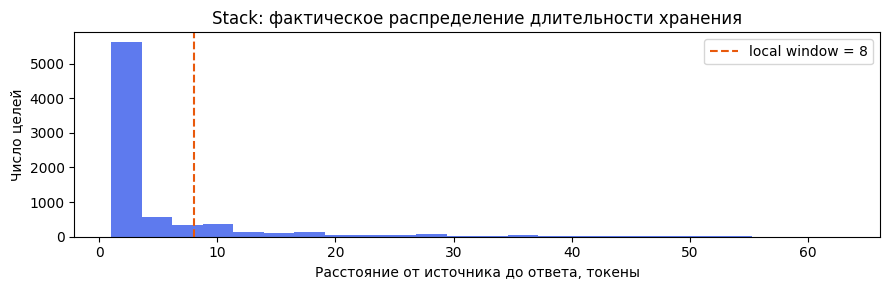

In [7]:
def show_stack(batch, sequence=0, limit=40):
    rows, stack = [], []
    for t, token in enumerate(batch["x"][sequence].tolist()):
        before = stack.copy()
        if token:
            stack.append(token)
            operation = f"push({token})"
        else:
            stack.pop()
            operation = "pop"
        rows.append({
            "t": t, "operation": operation, "stack_before": str(before),
            "stack_after": str(stack),
            "target": None if batch["y"][sequence, t] == IGNORE else batch["y"][sequence, t].item(),
            "push_t": None if batch["source_pos"][sequence, t] == IGNORE else batch["source_pos"][sequence, t].item(),
            "delay": None if batch["delay"][sequence, t] == IGNORE else batch["delay"][sequence, t].item(),
        })
    display(pd.DataFrame(rows).head(limit))

show_stack(stack_splits["preview"])
plot_delays(stack_splits["validation"], "Stack: фактическое распределение длительности хранения")

In [8]:
# Проверка примера из статьи SMT и воспроизводимости обвязки.
paper_stack = annotate_stack({
    "x": torch.tensor([[1, 0, 2, 3, 0, 1, 0, 0]]),
    "y": torch.tensor([[-1, 1, -1, -1, 3, -1, 1, 2]]),
})
assert paper_stack["source_pos"][0].tolist() == [-1, 0, -1, -1, 3, -1, 5, 2]
assert paper_stack["delay"][0, -1] == 5
check_batch(paper_stack, vocab_size=4)
replayed = sample_stack(STACK_CFG, 16, seed=101)
assert fingerprints(replayed) == fingerprints(stack_splits["preview"])
# Проверка граничного режима: глубина 1 заставляет чередовать push/pop.
edge_stack = sample_stack(StackConfig(seq_len=8, max_stack_size=1), 4, seed=77)
assert (edge_stack["delay"][edge_stack["target_mask"]] == 1).all()
print("Stack: пример статьи, источники ответов, границы и seed — OK.")

Stack: пример статьи, источники ответов, границы и seed — OK.


## 4. Key–Value Recall: предварительная обвязка (не MQAR)

Авторский MQAR без шума подготовлен отдельно в разделе 11; для пункта 6 используем его.

### 4.1. Исходная задача автора

Сначала непосредственно вызываем `AssociativeRecallDataset`. При `key_len=1` и `n_keys=9` автор генерирует **8 пар + 1 запрос**, а не 9 пар. Вход содержит ответ после запроса для teacher forcing; целевая позиция стоит раньше самого ответа. Параметр `ctx_len` проверяет минимальный размер, но не задаёт фактическую длину возвращаемой последовательности.

В исходном коде ключи выбираются с возвращением. Повторяющийся ключ с разными значениями делает ответ неоднозначным: индекс выбранной пары не сообщается модели. Исходный пример ниже не модифицируем; в контролируемом расширении отбираем только уникальные ключи.

Для первого этапа берём ключи и значения длины 1. Строковые ключи/значения — отдельное последующее усложнение.

In [9]:
KV_AUTHOR_ARGS = dict(V_key=64, V_val=8, key_len=1, n_keys=9)
kv_author_dataset = smt_data.AssociativeRecallDataset(**KV_AUTHOR_ARGS)
with isolated_seed(42):
    kv_author_example = kv_author_dataset.sample_batch(batch_size=1, ctx_len=18)

author_x, author_y = kv_author_example["x"][0], kv_author_example["y"][0]
display(pd.DataFrame({
    "t": range(len(author_x)), "x": author_x.tolist(), "y": author_y.tolist(),
    "role": ["pair key", "pair value"] * 8 + ["query key", "teacher-forced answer"],
}))
print("Фактическая длина:", len(author_x))
print("Число разных ключей:", len(set(author_x[:16:2].tolist())), "/ 8")
print("Число целей:", int(author_y.ne(IGNORE).sum()))

,t,x,y,role
0,0,38,-1,pair key
1,1,70,-1,pair value
2,2,51,-1,pair key
3,3,65,-1,pair value
4,4,28,-1,pair key
5,5,66,-1,pair value
6,6,14,-1,pair key
7,7,70,-1,pair value
8,8,42,-1,pair key
9,9,66,-1,pair value


Фактическая длина: 18
Число разных ключей: 8 / 8
Число целей: 1


### 4.2. Контролируемое расширение: несколько запросов

Пары `key/value` по-прежнему создаёт авторский генератор. Наша обвязка задаёт порядок событий:

- `WRITE key value` записывает пару; начальные ключи уникальны.
- `QUERY key` требует ответа на позиции ключа. Сам ответ **не добавляется во вход**.
- Перед короткими запросами повторяем запись соответствующей пары. Длинные запросы обращаются к другим, давно записанным парам.
- `NOP` — фиксированный токен паузы без целевого ответа; он задаёт расстояние между записью и запросом. Все ответы определяются записанными парами.

Это **расширение авторской задачи**, не точное воспроизведение её метрик. Добавленные служебные токены не пересекаются с ключами и значениями. Соответствие ключей значениям заново случайно для каждой последовательности.

Конфиг ниже относится только к Key–Value. `seq_len` включает правый padding. Если события не помещаются, генератор сообщит об этом, а не отрежет запросы.

In [10]:
@dataclass(frozen=True)
class KeyValueConfig:
    seq_len: int = 192
    n_pairs: int = 8
    n_queries: int = 8
    V_key: int = 64
    V_val: int = 8
    long_min_delay: int = 32
    short_gap_max: int = 3
    inter_query_gap_max: int = 3

KV_CFG = KeyValueConfig()

def kv_tokens(cfg):
    start = cfg.V_key + cfg.V_val
    return dict(NOP=start, WRITE=start + 1, QUERY=start + 2)

def kv_vocab_size(cfg):
    return cfg.V_key + cfg.V_val + 3

def unique_author_pairs(cfg, batch_size):
    """Вызывается внутри isolated_seed; sampling пар остаётся авторским."""
    if cfg.n_pairs > cfg.V_key:
        raise ValueError("Для уникальных однотокенных ключей n_pairs <= V_key.")
    dataset = smt_data.AssociativeRecallDataset(
        V_key=cfg.V_key, V_val=cfg.V_val, key_len=1, n_keys=cfg.n_pairs + 1)
    accepted = []
    for _ in range(200):
        raw = dataset.sample_batch(
            batch_size=max(16, 2 * (batch_size - len(accepted))),
            ctx_len=2 * (cfg.n_pairs + 1))
        pairs = raw["x"][:, :2 * cfg.n_pairs].reshape(-1, cfg.n_pairs, 2)
        for example in pairs:
            if example[:, 0].unique().numel() == cfg.n_pairs:
                accepted.append(example.clone())
                if len(accepted) == batch_size:
                    return torch.stack(accepted)
    raise ValueError("Редко получаются уникальные ключи. Увеличьте V_key или уменьшите n_pairs.")

def sample_keyvalue(cfg, batch_size, seed):
    if min(cfg.seq_len, cfg.V_key, cfg.V_val, batch_size) < 1:
        raise ValueError("Размеры должны быть положительными.")
    if cfg.n_pairs < 2 or cfg.n_queries < 2:
        raise ValueError("Для смеси short/long нужны минимум 2 пары и 2 запроса.")
    if min(cfg.long_min_delay, cfg.short_gap_max, cfg.inter_query_gap_max) < 0:
        raise ValueError("Расстояния не могут быть отрицательными.")
    if cfg.long_min_delay <= cfg.short_gap_max + 2:
        raise ValueError("long_min_delay должен быть больше максимального short delay.")
    rng = np.random.default_rng(seed)
    with isolated_seed(seed):
        pair_pool = unique_author_pairs(cfg, batch_size)

    raw = {name: torch.full((batch_size, cfg.seq_len), IGNORE, dtype=torch.long)
           for name in ("x", "y")}
    batch = base_metadata(raw)
    batch["query_kind"] = torch.full_like(raw["y"], IGNORE)  # 0 short, 1 long
    batch["lengths"] = torch.zeros(batch_size, dtype=torch.long)
    tokens = kv_tokens(cfg)

    for b in range(batch_size):
        keys = pair_pool[b, :, 0].tolist()
        values = dict(pair_pool[b].tolist())
        last_write = {}
        xs, ys, sources, kinds = [], [], [], []

        def emit(token, target=IGNORE, source=IGNORE, kind=IGNORE):
            xs.append(int(token))
            ys.append(int(target))
            sources.append(int(source))
            kinds.append(int(kind))

        def write(key):
            emit(tokens["WRITE"])
            emit(key)
            emit(values[key])
            last_write[key] = len(xs) - 1

        # Половина ключей остаётся старой, другая используется для свежих записей.
        split = cfg.n_pairs // 2
        long_keys, short_keys = keys[:split], keys[split:]
        for key in rng.permutation(keys):
            write(int(key))
        schedule = ([0] * (cfg.n_queries // 2)
                    + [1] * (cfg.n_queries - cfg.n_queries // 2))
        rng.shuffle(schedule)

        for kind in schedule:
            for _ in range(int(rng.integers(cfg.inter_query_gap_max + 1))):
                emit(tokens["NOP"])
            if kind == 0:
                key = int(rng.choice(short_keys))
                write(key)
                for _ in range(int(rng.integers(cfg.short_gap_max + 1))):
                    emit(tokens["NOP"])
            else:
                key = int(rng.choice(long_keys))
                # Цель стоит на токене key, после QUERY.
                required_padding = max(0, last_write[key] + cfg.long_min_delay - (len(xs) + 1))
                for _ in range(required_padding):
                    emit(tokens["NOP"])
            emit(tokens["QUERY"])
            emit(key, values[key], last_write[key], kind)

        n = len(xs)
        if n > cfg.seq_len:
            raise ValueError(f"Нужно {n} токенов, seq_len={cfg.seq_len}. Увеличьте seq_len.")
        batch["x"][b, :n] = torch.tensor(xs)
        batch["y"][b, :n] = torch.tensor(ys)
        batch["source_pos"][b, :n] = torch.tensor(sources)
        batch["query_kind"][b, :n] = torch.tensor(kinds)
        batch["lengths"][b] = n

    batch["target_mask"] = batch["y"].ne(IGNORE)
    useful = batch["target_mask"]
    positions = torch.arange(cfg.seq_len).expand_as(batch["y"])
    batch["delay"][useful] = (positions - batch["source_pos"])[useful]
    check_batch(batch, kv_vocab_size(cfg))
    assert (batch["delay"][batch["query_kind"].eq(0)] <= cfg.short_gap_max + 2).all()
    assert (batch["delay"][batch["query_kind"].eq(1)] >= cfg.long_min_delay).all()
    return batch

kv_splits = fixed_splits(sample_keyvalue, KV_CFG)
kv_train = batch_stream(sample_keyvalue, KV_CFG)
display(pd.DataFrame([asdict(KV_CFG)]))
display(split_summary(kv_splits))

,seq_len,n_pairs,n_queries,V_key,V_val,long_min_delay,short_gap_max,inter_query_gap_max
0,192,8,8,64,8,32,3,3


,split,sequences,shape,targets,delay_median,delay_max,fraction_delay_ge_8,unique_sequences
0,preview,16,"(16, 192)",128,18.5,79,0.5,16
1,validation,256,"(256, 192)",2048,18.5,100,0.5,256
2,test,256,"(256, 192)",2048,18.5,94,0.5,256


,t,input,target,kind,source_t,delay
0,0,WRITE,,,NaN,NaN
1,1,k12,,,NaN,NaN
2,2,v1,,,NaN,NaN
3,3,WRITE,,,NaN,NaN
4,4,k28,,,NaN,NaN
...,...,...,...,...,...,...
75,75,k12,,,NaN,NaN
76,76,v1,,,NaN,NaN
77,77,NOP,,,NaN,NaN
78,78,QUERY,,,NaN,NaN


,sequence,target_t,answer,source_t,delay
0,0,31,70,29,2
1,0,40,70,37,3
2,0,44,68,8,36
3,0,55,68,23,32
4,0,63,70,58,5
5,0,67,68,23,44
6,0,72,64,5,67
7,0,79,65,76,3


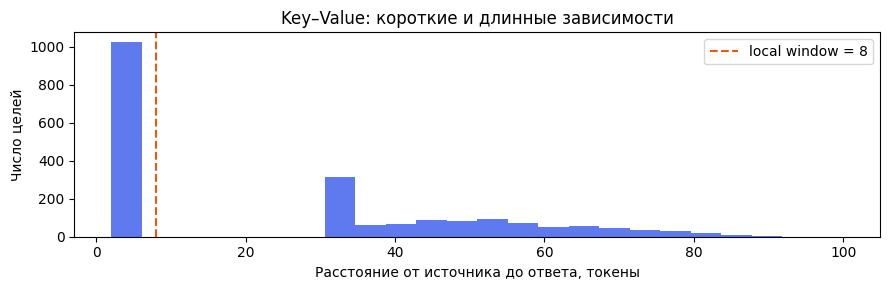

In [11]:
def kv_token_name(token, cfg):
    if token == IGNORE:
        return "PAD"
    names = {v: k for k, v in kv_tokens(cfg).items()}
    if token in names:
        return names[token]
    return f"k{token}" if token < cfg.V_key else f"v{token - cfg.V_key}"

def show_keyvalue(batch, cfg, sequence=0, limit=90):
    n = int(batch["lengths"][sequence])
    kind_names = {-1: "", 0: "short", 1: "long"}
    rows = []
    for t in range(n):
        y = batch["y"][sequence, t].item()
        src = batch["source_pos"][sequence, t].item()
        delay = batch["delay"][sequence, t].item()
        rows.append({
            "t": t, "input": kv_token_name(batch["x"][sequence, t].item(), cfg),
            "target": "" if y == IGNORE else kv_token_name(y, cfg),
            "kind": kind_names[batch["query_kind"][sequence, t].item()],
            "source_t": None if src == IGNORE else src,
            "delay": None if delay == IGNORE else delay,
        })
    display(pd.DataFrame(rows).head(limit))

show_keyvalue(kv_splits["preview"], KV_CFG)
display(target_table(kv_splits["preview"]).query("sequence == 0"))
plot_delays(kv_splits["validation"], "Key–Value: короткие и длинные зависимости")

In [12]:
def verify_keyvalue_semantics(batch, cfg):
    """Независимо проигрываем токены и проверяем последнюю запись каждого ключа."""
    tok = kv_tokens(cfg)
    for b in range(len(batch["x"])):
        mapping, latest = {}, {}
        i, n = 0, int(batch["lengths"][b])
        while i < n:
            token = batch["x"][b, i].item()
            if token == tok["WRITE"]:
                key, value = batch["x"][b, i + 1:i + 3].tolist()
                assert 0 <= key < cfg.V_key
                assert cfg.V_key <= value < cfg.V_key + cfg.V_val
                assert (batch["y"][b, i:i + 3] == IGNORE).all()
                mapping[key], latest[key] = value, i + 2
                i += 3
            elif token == tok["QUERY"]:
                key = batch["x"][b, i + 1].item()
                assert batch["y"][b, i] == IGNORE
                assert batch["y"][b, i + 1] == mapping[key]
                assert batch["source_pos"][b, i + 1] == latest[key]
                i += 2
            elif token == tok["NOP"]:
                assert batch["y"][b, i] == IGNORE
                i += 1
            else:
                raise AssertionError(f"Неожиданный токен {token} на позиции {i}")
        assert (batch["x"][b, n:] == IGNORE).all()
        assert (batch["y"][b, n:] == IGNORE).all()
    return True

for data in kv_splits.values():
    verify_keyvalue_semantics(data, KV_CFG)
assert fingerprints(sample_keyvalue(KV_CFG, 16, 101)) == fingerprints(kv_splits["preview"])
# Все обычные ответы — значения, ни одна цель не является служебным токеном.
for data in kv_splits.values():
    labels = data["y"][data["target_mask"]]
    assert ((labels >= KV_CFG.V_key) & (labels < KV_CFG.V_key + KV_CFG.V_val)).all()
print("Key–Value: семантика записей/запросов, short/long, padding и seed — OK.")

Key–Value: семантика записей/запросов, short/long, padding и seed — OK.


## 5. Общая подготовка окон SMT

Для состояния в точке `t`:

```text
x_ctx      = x[t-Tc+1 ... t]       # прошлое, включая текущий вход
x_ctx_next = x[t-Tc+2 ... t+1]     # следующая память-учитель
x_fut      = x[t+1 ... t+Tf]       # будущие входы decoder
y_fut      = y[t   ... t+Tf-1]     # будущие ответы, начиная с y_t
```

Такой сдвиг совпадает с интерфейсом авторского `Teacher.decode`: первый выход получается из памяти, до чтения первого будущего входа. Отсутствующие позиции заполняются -1. Можно брать все `t`, как в синтетических экспериментах статьи, или явно переданный список для отладки.

Для синтетики начните с `Tc=Tf=T`. Короткий `Tc` может удалить необходимую информацию ещё до энкодера. Диагностические маски показывают:
- `prefix_available`: нужный источник находится в доступном префиксе;
- `future_available`: источник появится после t среди будущих входов;
- `source_truncated`: источник существовал, но выпал из окна энкодера.

Это разметка для анализа, не готовый селектор MemUP. Для всех вариантов loss пул допустимых целей должен быть одинаковым.

In [13]:
def take_positions(tensor, rows, positions, fill=IGNORE):
    length = tensor.shape[1]
    valid = (positions >= 0) & (positions < length)
    values = tensor[rows[:, None], positions.clamp(0, length - 1)]
    return torch.where(valid, values, torch.full_like(values, fill))

def make_smt_windows(batch, Tc, Tf, anchors=None):
    if Tc < 1 or Tf < 1:
        raise ValueError("Tc и Tf должны быть положительными.")
    x, y = batch["x"], batch["y"]
    B, T = x.shape
    times = torch.arange(T) if anchors is None else torch.as_tensor(anchors, dtype=torch.long)
    if times.ndim != 1 or len(times) == 0 or ((times < 0) | (times >= T)).any():
        raise ValueError("anchors — непустой список индексов от 0 до T-1.")
    rows, t = torch.meshgrid(torch.arange(B), times, indexing="ij")
    rows, t = rows.flatten(), t.flatten()
    real_anchor = x[rows, t].ne(IGNORE)
    rows, t = rows[real_anchor], t[real_anchor]
    past_pos = t[:, None] + torch.arange(-Tc + 1, 1)
    future_pos = t[:, None] + torch.arange(1, Tf + 1)
    target_pos = t[:, None] + torch.arange(Tf)
    src = take_positions(batch["source_pos"], rows, target_pos)
    y_fut = take_positions(y, rows, target_pos)
    valid = y_fut.ne(IGNORE)
    useful = valid & src.ge(0)
    start = torch.clamp(t - Tc + 1, min=0)[:, None]
    prefix = useful & (src <= t[:, None]) & (src >= start)
    future = useful & (src > t[:, None])
    truncated = useful & (src < start)
    next_x = take_positions(x, rows, t[:, None] + 1)
    return {
        "x_ctx": take_positions(x, rows, past_pos),
        "x_ctx_next": take_positions(x, rows, past_pos + 1),
        "x_fut": take_positions(x, rows, future_pos),
        "y_fut": y_fut,
        "target_mask": valid,
        "decoder_valid": valid.any(dim=1),
        "dynamics_valid": next_x[:, 0].ne(IGNORE),
        "x_next": next_x,
        "sequence_id": rows, "anchor_t": t,
        "target_t": torch.where(valid, target_pos, torch.full_like(target_pos, IGNORE)),
        "source_pos": src,
        "delay": take_positions(batch["delay"], rows, target_pos),
        "prefix_available": prefix,
        "future_available": future,
        "source_truncated": truncated,
    }

def first_sequences(batch, n=2):
    return {name: value[:n] for name, value in batch.items()}

stack_windows = make_smt_windows(first_sequences(stack_splits["preview"]), STACK_CFG.seq_len, STACK_CFG.seq_len)
kv_windows = make_smt_windows(first_sequences(kv_splits["preview"]), KV_CFG.seq_len, KV_CFG.seq_len)

def window_summary(windows, name):
    return {
        "task": name, "windows": len(windows["anchor_t"]),
        "x_ctx": str(tuple(windows["x_ctx"].shape)),
        "y_fut": str(tuple(windows["y_fut"].shape)),
        "windows_with_targets": int(windows["decoder_valid"].sum()),
        "valid_transitions": int(windows["dynamics_valid"].sum()),
        "prefix_target_pairs": int(windows["prefix_available"].sum()),
        "future_target_pairs": int(windows["future_available"].sum()),
        "truncated_target_pairs": int(windows["source_truncated"].sum()),
    }

display(pd.DataFrame([
    window_summary(stack_windows, "Stack"), window_summary(kv_windows, "Key–Value")
]))
print("Счётчики target_pairs относятся к парам (anchor, target), а не к уникальным целям.")

,task,windows,x_ctx,y_fut,windows_with_targets,valid_transitions,prefix_target_pairs,future_target_pairs,truncated_target_pairs
0,Stack,128,"(128, 64)","(128, 64)",125,126,332,1725,0
1,Key–Value,166,"(166, 192)","(166, 192)",166,164,456,521,0


Счётчики target_pairs относятся к парам (anchor, target), а не к уникальным целям.


In [14]:
# Проверка индексов на известном примере: anchor t=3, future targets t=3..7.
w = make_smt_windows(paper_stack, Tc=4, Tf=5, anchors=[3])
assert w["x_ctx"][0].tolist() == [1, 0, 2, 3]
assert w["x_ctx_next"][0].tolist() == [0, 2, 3, 0]
assert w["x_fut"][0].tolist() == [0, 1, 0, 0, -1]
assert w["y_fut"][0].tolist() == [-1, 3, -1, 1, 2]
assert w["prefix_available"][0].tolist() == [False, True, False, False, True]
assert w["future_available"][0].tolist() == [False, False, False, True, False]
short_w = make_smt_windows(paper_stack, Tc=1, Tf=5, anchors=[3])
assert short_w["source_truncated"][0, -1]
last_w = make_smt_windows(paper_stack, Tc=8, Tf=8, anchors=[7])
assert not last_w["dynamics_valid"][0]
# Изменение будущего не меняет x_ctx при фиксированном t.
changed = {k: v.clone() for k, v in paper_stack.items()}
changed["x"][:, 4:] = 2
assert torch.equal(make_smt_windows(changed, 4, 5, [3])["x_ctx"], w["x_ctx"])
for windows in (stack_windows, kv_windows):
    partition = (windows["prefix_available"].int() + windows["future_available"].int()
                 + windows["source_truncated"].int())
    assert torch.equal(partition, windows["target_mask"].int())
    assert not windows["source_truncated"].any()
print("Окна SMT: сдвиги, causal prefix, источники целей и границы — OK.")
display(pd.DataFrame({
    "target_t": w["target_t"][0].tolist(),
    "y": w["y_fut"][0].tolist(),
    "source_t": w["source_pos"][0].tolist(),
    "needs_prefix": w["prefix_available"][0].tolist(),
    "source_in_future": w["future_available"][0].tolist(),
}))

Окна SMT: сдвиги, causal prefix, источники целей и границы — OK.


,target_t,y,source_t,needs_prefix,source_in_future
0,-1,-1,-1,False,False
1,4,3,3,True,False
2,-1,-1,-1,False,False
3,6,1,5,False,True
4,7,2,2,True,False


### 5.1. Проверка совместимости с авторскими Teacher и RNN

Ниже один forward на маленьких случайно инициализированных моделях, без градиентов и оптимизатора. Проверяются размерности и численная корректность. Его loss не является результатом эксперимента.

Архитектуру берём напрямую из `upstream/smt/src/model.py`; маленькие размеры нужны только для этой технической проверки.

При обучении в разделе 6:
- `decoder_valid` исключает окна без ответов;
- `dynamics_valid` исключает переход за конец последовательности;
- все loss на целях должны учитывать `target_mask`;
- адаптер `dmt_objective` учитывает -1-цели, задаёт detach явно и обучает rollout с нулевой памяти; готовый авторский `forward_dmt` напрямую не вызывается.

In [15]:
def masked_ce(logits, targets):
    # В исходном masked_mean знаменатель может быть нулевым.
    # Здесь явно определяем loss=0 для окна/батча без целей.
    mask = targets.ne(IGNORE)
    losses = smt_model.calc_cross_entropy_loss(logits, targets.clamp(min=0))
    return (losses * mask).sum() / mask.sum().clamp(min=1)

@torch.no_grad()
def check_author_forward(batch, vocab_size):
    first_target = int(torch.where(batch["target_mask"][0])[0][0])
    anchors = sorted(set([max(0, first_target - 1), first_target]))
    windows = make_smt_windows(first_sequences(batch, 2), Tc=16, Tf=8, anchors=anchors)
    assert windows["target_mask"].any(), "Проверка должна включать реальные цели."
    with isolated_seed(7):
        teacher = smt_model.Teacher(smt_model.TeacherConfig(
            vocab_size=vocab_size, mem_size=64, mem_tokens=2,
            d_model=32, encoder_depth=1, decoder_depth=1, n_heads=4)).eval()
        rnn = smt_model.RNN(smt_model.RNNConfig(
            vocab_size=vocab_size, mem_size=64, mem_tokens=2,
            d_model=32, rnn_depth=1, decoder_depth=1, n_heads=4)).eval()
    memory = teacher.encode(windows["x_ctx"])
    logits = teacher.decode(memory, windows["x_fut"])
    transition_mask = windows["dynamics_valid"]
    next_memory = rnn.rnn_update(memory[transition_mask], windows["x_next"][transition_mask])
    assert logits.shape == (*windows["y_fut"].shape, vocab_size)
    assert memory.shape == (len(windows["anchor_t"]), 64)
    assert next_memory.shape == (int(transition_mask.sum()), 64)
    assert torch.isfinite(logits).all() and torch.isfinite(next_memory).all()
    assert torch.isfinite(masked_ce(logits, windows["y_fut"]))
    assert masked_ce(logits, torch.full_like(windows["y_fut"], IGNORE)).item() == 0
    return {"memory": tuple(memory.shape), "logits": tuple(logits.shape),
            "next_memory": tuple(next_memory.shape), "status": "OK; untrained"}

print("Stack:", check_author_forward(stack_splits["preview"], STACK_CFG.n_elements + 1))
print("Key–Value:", check_author_forward(kv_splits["preview"], kv_vocab_size(KV_CFG)))

Stack: {'memory': (4, 64), 'logits': (4, 8, 5), 'next_memory': (4, 64), 'status': 'OK; untrained'}
Key–Value: {'memory': (4, 64), 'logits': (4, 8, 75), 'next_memory': (4, 64), 'status': 'OK; untrained'}


In [16]:
# Манифест подготовленных данных; конфиг и результаты baseline сохраняются отдельно в разделе 6.
manifest = {
    "repositories": REVISIONS,
    "python": sys.version.split()[0],
    "torch": str(torch.__version__),
    "stack_config": asdict(STACK_CFG),
    "keyvalue_config": asdict(KV_CFG),
    "split_seeds": {"preview": 101, "validation": 10_001, "test": 20_001, "train_stream": 30_001},
    "validation_examples": 256,
    "test_examples": 256,
    "fingerprints": {
        "stack_validation": hashlib.sha256("".join(fingerprints(stack_splits["validation"])).encode()).hexdigest(),
        "stack_test": hashlib.sha256("".join(fingerprints(stack_splits["test"])).encode()).hexdigest(),
        "kv_validation": hashlib.sha256("".join(fingerprints(kv_splits["validation"])).encode()).hexdigest(),
        "kv_test": hashlib.sha256("".join(fingerprints(kv_splits["test"])).encode()).hexdigest(),
    },
}
display(pd.DataFrame([
    {"check": "Авторские модули SMT импортированы", "status": "OK"},
    {"check": "Stack: семантика, seed, validation/test", "status": "OK"},
    {"check": "Key–Value: семантика, short/long, padding", "status": "OK"},
    {"check": "SMT: окна, causal prefix, маски", "status": "OK"},
    {"check": "Teacher/RNN: forward без обучения", "status": "OK"},
]))
print(json.dumps(manifest, ensure_ascii=False, indent=2))

,check,status
0,Авторские модули SMT импортированы,OK
1,"Stack: семантика, seed, validation/test",OK
2,"Key–Value: семантика, short/long, padding",OK
3,"SMT: окна, causal prefix, маски",OK
4,Teacher/RNN: forward без обучения,OK


{
  "repositories": {
    "smt": "cf0d0f04be606ab9d97b1a449a6846450d656ad0",
    "memup": "d27657137f6e427e30fcd4ae885b20b071b2917d"
  },
  "python": "3.13.16",
  "torch": "2.11.0+cpu",
  "stack_config": {
    "seq_len": 64,
    "n_elements": 4,
    "max_stack_size": 8
  },
  "keyvalue_config": {
    "seq_len": 192,
    "n_pairs": 8,
    "n_queries": 8,
    "V_key": 64,
    "V_val": 8,
    "long_min_delay": 32,
    "short_gap_max": 3,
    "inter_query_gap_max": 3
  },
  "split_seeds": {
    "preview": 101,
    "validation": 10001,
    "test": 20001,
    "train_stream": 30001
  },
  "validation_examples": 256,
  "test_examples": 256,
  "fingerprints": {
    "stack_validation": "a786df63e2678da2e2c6a6cccd9150f4360109827f843bba35482d1e1f430b9a",
    "stack_test": "78aca840be86f172163a2829b090113ff73df7929ee777b29da78d716d039e01",
    "kv_validation": "7ffac6a1f8a0cbebdb3d16a9ab01f060760de1f58fed421206a4439ac98069cc",
    "kv_test": "3a163e90ca62313555ed5ca52c1b85c985dc42171019d3759716e742

## 6. Базовые SMT → DMT на Stack

В этом разделе есть обучение и оценка. `RUN_BASELINE=True` запускает короткий baseline; `REUSE_SAVED=True` при повторном Run All загружает завершённый запуск с тем же конфигом. Промежуточные checkpoints позволяют продолжить прерванный этап.

**Протокол:** авторские `Teacher/RNN`, исходные три слагаемых SMT, полный префикс и все точки t. Наш адаптер нужен потому, что опубликованный forward SMT рассчитан на другое формирование батча. Дополнительно супервизируем начальный переход `f(0,x0) → E(x0)`, чтобы RNN можно было оценивать с нулевой памяти.

**DMT:** teacher заморожен; updater учится на собственных состояниях, readout — на ответах с detached memory. Параметр `dmt_bptt=False` явно обрывает градиент между обновлениями состояния (one-step imitation); task loss не обучает updater. Постоянные teacher decoder/uniformity loss на этом этапе опущены, поскольку не меняют градиентов.

Это один небольшой CPU baseline на Stack, не sweep из статьи. Key–Value остаётся подготовленной отдельной задачей. Размеры проверки не заменяют исходные `STACK_CFG` и `KV_CFG`.

Если меняете реализацию loss/forward, увеличьте `ADAPTER_VERSION`, чтобы получить отдельный каталог результатов. Изменения `BASELINE_CFG` уже автоматически создают новый каталог.

In [17]:
from dataclasses import replace
import copy
import time
import math
from einops import rearrange

@dataclass(frozen=True)
class BaselineConfig:
    seed: int = 7
    seq_len: int = 24
    n_elements: int = 4
    max_stack_size: int = 3
    d_model: int = 32
    mem_tokens: int = 4
    encoder_depth: int = 2
    decoder_depth: int = 1
    rnn_depth: int = 1
    n_heads: int = 4
    batch_size: int = 8
    smt_steps: int = 800
    dmt_steps: int = 300
    smt_lr: float = 0.001
    dmt_lr: float = 0.0003
    weight_decay: float = 0.01
    coef_dec: float = 1.0
    coef_dyn: float = 0.1
    coef_unif: float = 0.001
    dmt_coef_dyn: float = 10.0
    dmt_coef_readout: float = 1.0
    dmt_bptt: bool = False
    clip_grad: float = 1.0
    eval_every: int = 100
    eval_examples: int = 128
    eval_batch_size: int = 16

BASELINE_CFG = BaselineConfig()
RUN_BASELINE = True
REUSE_SAVED = True
TRAIN_DEVICE = device
ADAPTER_VERSION = "stack-baseline-v1"

def baseline_data_cfg(cfg):
    return StackConfig(seq_len=cfg.seq_len, n_elements=cfg.n_elements,
                       max_stack_size=cfg.max_stack_size)

def baseline_identity(cfg):
    return {"config": asdict(cfg), "adapter": ADAPTER_VERSION,
            "repositories": REVISIONS, "torch": str(torch.__version__),
            "device": str(TRAIN_DEVICE)}

RUN_KEY = hashlib.sha256(json.dumps(baseline_identity(BASELINE_CFG),
                                   sort_keys=True).encode()).hexdigest()[:12]
RUN_DIR = ROOT / "runs" / ("stack_baseline_" + RUN_KEY)
print("Device:", TRAIN_DEVICE, "| run:", RUN_DIR)
display(pd.DataFrame([asdict(BASELINE_CFG)]))

class MemoryBoundTeacher(smt_model.Teacher):
    # CPU путь совпадает с авторским. На CUDA разбиваем только независимые окна;
    # checkpoint пересчитывает активации при backward, не обрывая градиенты.
    def _bounded(self, method, *args):
        if TRAIN_DEVICE.type != "cuda":
            return method(self, *args)
        from torch.utils.checkpoint import checkpoint
        parts = []
        for lo in range(0, len(args[0]), CUDA_WINDOW_CHUNK):
            chunk = tuple(a[lo:lo + CUDA_WINDOW_CHUNK] for a in args)
            fn = lambda *xs: method(self, *xs)
            parts.append(checkpoint(fn, *chunk, use_reentrant=False)
                         if torch.is_grad_enabled() else fn(*chunk))
        return torch.cat(parts)
    def encode(self, x):
        return self._bounded(smt_model.Teacher.encode, x)
    def decode(self, z, x):
        return self._bounded(smt_model.Teacher.decode, z, x)

def make_models(cfg):
    common = dict(vocab_size=cfg.n_elements + 1,
                  mem_size=cfg.d_model * cfg.mem_tokens, mem_tokens=cfg.mem_tokens,
                  d_model=cfg.d_model, decoder_depth=cfg.decoder_depth,
                  n_heads=cfg.n_heads)
    with isolated_seed(cfg.seed):
        teacher = MemoryBoundTeacher(smt_model.TeacherConfig(
            **common, encoder_depth=cfg.encoder_depth)).to(TRAIN_DEVICE)
        rnn = smt_model.RNN(smt_model.RNNConfig(
            **common, rnn_depth=cfg.rnn_depth)).to(TRAIN_DEVICE)
    return teacher, rnn

def copy_readout(teacher, rnn):
    rnn.decoder.load_state_dict(teacher.decoder.state_dict())
    rnn.to_logits.load_state_dict(teacher.to_logits.state_dict())

def move_batch(batch, device):
    return {k: v.to(device) for k, v in batch.items()}

def teacher_trajectory(teacher, batch):
    # Формируем окна на CPU; encoder вызывается одним time-parallel батчем.
    B, T = batch["x"].shape
    windows = make_smt_windows(batch, Tc=T, Tf=T)
    assert len(windows["anchor_t"]) == B * T, "Training adapter рассчитан на Stack без padding."
    memories = teacher.encode(windows["x_ctx"].to(TRAIN_DEVICE))
    return memories.reshape(B, T, -1), windows

def smt_objective(teacher, rnn, batch, cfg):
    m, windows = teacher_trajectory(teacher, batch)
    B, T, Z = m.shape
    flat_m = m.reshape(B * T, Z)
    logits = teacher.decode(flat_m, windows["x_fut"].to(TRAIN_DEVICE))
    # Как в опубликованном коде: среднее по валидным парам (anchor, target).
    dec = masked_ce(logits, windows["y_fut"].to(TRAIN_DEVICE))
    prev = torch.cat([torch.zeros_like(m[:, :1]), m[:, :-1]], dim=1)
    predicted = rnn.rnn_update(prev.reshape(B * T, Z),
                               batch["x"].to(TRAIN_DEVICE).reshape(B * T, 1))
    # Градиент dynamics проходит в teacher с обеих сторон, как detach_rnn=False у автора.
    dyn = smt_model.calc_mse_loss(predicted, flat_m).mean()
    unif = smt_model.calc_uniformity_loss(
        rearrange(flat_m, "b (k d) -> (b k) d", k=teacher.cfg.mem_tokens))
    loss = cfg.coef_dec * dec + cfg.coef_dyn * dyn + cfg.coef_unif * unif
    return loss, {"loss": loss, "decoder": dec, "dynamics": dyn, "uniformity": unif}

def recurrent_trajectory(rnn, x, initial_teacher_memory=None, detach_between=False):
    B, T = x.shape
    state = torch.zeros(B, rnn.cfg.mem_size, device=x.device)
    states = []
    for t in range(T):
        if t == 0 and initial_teacher_memory is not None:
            state = initial_teacher_memory
        else:
            state = rnn.rnn_update(state.detach() if detach_between else state, x[:, t:t+1])
        states.append(state)
    return torch.stack(states, dim=1)

def dmt_objective(teacher, rnn, batch, cfg):
    with torch.no_grad():
        target_memory, _ = teacher_trajectory(teacher, batch)
    states = recurrent_trajectory(
        rnn, batch["x"].to(TRAIN_DEVICE), detach_between=not cfg.dmt_bptt)
    dyn = smt_model.calc_mse_loss(states, target_memory).mean()
    # Task loss обучает только голову; credit assignment updater задаёт dynamics loss.
    logits = rnn.rnn_readout(states.detach().flatten(0, 1))
    logits = logits.reshape(*batch["y"].shape, -1)
    readout = masked_ce(logits, batch["y"].to(TRAIN_DEVICE))
    loss = cfg.dmt_coef_dyn * dyn + cfg.dmt_coef_readout * readout
    return loss, {"loss": loss, "dynamics": dyn, "readout": readout}


Device: cpu | run: /content/smt_memup/runs/stack_baseline_7470f59a27d1


,seed,seq_len,n_elements,max_stack_size,d_model,mem_tokens,encoder_depth,decoder_depth,rnn_depth,n_heads,...,coef_dec,coef_dyn,coef_unif,dmt_coef_dyn,dmt_coef_readout,dmt_bptt,clip_grad,eval_every,eval_examples,eval_batch_size
0,7,24,4,3,32,4,2,1,1,4,...,1.0,0.1,0.001,10.0,1.0,False,1.0,100,128,16


### 6.1. Оценка teacher и рекуррентной модели

Все метрики считаются только на pop-ответах. Teacher получает префикс до текущего t; RNN обновляется последовательно на тех же входах.

Основной режим RNN — `zero`: нулевая начальная память, encoder при inference не используется. Дополнительный `teacher_first_token` начинает с `E(x0)` и помогает диагностировать влияние первого перехода.

Помимо собственной головы RNN считаем качество через **общую замороженную голову teacher** (`shared_accuracy/shared_ce`). Так можно отличать изменение содержимого памяти от адаптации readout. MSE между состояниями — дополнительная метрика, не замена accuracy.

In [18]:
if RUN_HISTORICAL_PILOTS:
    @torch.no_grad()
    def evaluate_models(teacher, rnn, batch, cfg, stage, split,
                        start_modes=("zero",)):
        teacher.eval()
        rnn.eval()
        event_frames, state_frames = [], []
        for lo in range(0, len(batch["x"]), cfg.eval_batch_size):
            part = {k: v[lo:lo + cfg.eval_batch_size] for k, v in batch.items()}
            target_m, _ = teacher_trajectory(teacher, part)
            B, T, Z = target_m.shape
            x = part["x"].to(TRAIN_DEVICE)
            y = part["y"].to(TRAIN_DEVICE)
            teacher_logits = teacher.teacher_readout(target_m.flatten(0, 1)).reshape(B, T, -1)
            modes = [("teacher", target_m, teacher_logits, teacher_logits)]
            for start in start_modes:
                states = recurrent_trajectory(
                    rnn, x, initial_teacher_memory=target_m[:, 0] if start == "teacher_first_token" else None)
                own_logits = rnn.rnn_readout(states.flatten(0, 1)).reshape(B, T, -1)
                shared_logits = teacher.teacher_readout(states.flatten(0, 1)).reshape(B, T, -1)
                modes.append(("rnn_" + start, states, own_logits, shared_logits))
            b, t = torch.where(part["target_mask"])
            for model, states, logits, shared in modes:
                ce = smt_model.calc_cross_entropy_loss(logits, y.clamp(min=0)).cpu()
                shared_ce = smt_model.calc_cross_entropy_loss(shared, y.clamp(min=0)).cpu()
                drift = (states - target_m).square().mean(dim=-1).cpu()
                predictions = logits.argmax(dim=-1).cpu()
                shared_predictions = shared.argmax(dim=-1).cpu()
                event_frames.append(pd.DataFrame({
                    "stage": stage, "split": split, "model": model,
                    "sequence": (b + lo).numpy(), "t": t.numpy(),
                    "source_t": part["source_pos"][b, t].numpy(),
                    "delay": part["delay"][b, t].numpy(),
                    "stack_depth_before_pop": (part["depth"][b, t] + 1).numpy(),
                    "target": part["y"][b, t].numpy(),
                    "prediction": predictions[b, t].numpy(),
                    "correct": (predictions[b, t] == part["y"][b, t]).numpy(),
                    "ce": ce[b, t].numpy(),
                    "shared_correct": (shared_predictions[b, t] == part["y"][b, t]).numpy(),
                    "shared_ce": shared_ce[b, t].numpy(),
                    "memory_mse": drift[b, t].numpy(),
                }))
                state_frames.append(pd.DataFrame({
                    "stage": stage, "split": split, "model": model,
                    "sequence": np.repeat(np.arange(lo, lo + B), T),
                    "t": np.tile(np.arange(T), B),
                    "memory_mse": drift.flatten().numpy(),
                }))
        return pd.concat(event_frames, ignore_index=True), pd.concat(state_frames, ignore_index=True)

    def aggregate_events(events, extra=()):
        keys = ["split", "stage", "model", *extra]
        return events.groupby(keys, observed=True).agg(
            n_targets=("correct", "size"), accuracy=("correct", "mean"),
            ce=("ce", "mean"), shared_accuracy=("shared_correct", "mean"),
            shared_ce=("shared_ce", "mean"), memory_mse=("memory_mse", "mean"),
        ).reset_index()

    def by_dependency_age(events):
        table = events.copy()
        table["delay_bin"] = pd.cut(table.delay, bins=[0, 2, 4, 8, 16, np.inf],
                                   labels=["1–2", "3–4", "5–8", "9–16", "17+"])
        return aggregate_events(table, extra=("delay_bin",))

    def scalar_metrics(values):
        return {k: float(v.detach().cpu()) for k, v in values.items()}

    def atomic_save(payload, path):
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(path.suffix + ".tmp")
        torch.save(payload, temporary)
        temporary.replace(path)

    def load_checkpoint(path):
        # Наши checkpoints содержат только state_dict, tensor, числа, строки, dict/list.
        return torch.load(path, map_location="cpu", weights_only=True)

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 6.2. Проверки обучения до baseline

Проверяем реальные пути градиентов SMT/DMT, заморозку teacher и уменьшение decoder loss на маленьком фиксированном батче. Модели этих проверок отдельные: их веса не используются в основном запуске. Это проверка реализации, а не оценка обобщения.

In [19]:
if RUN_HISTORICAL_PILOTS:
    def check_training_paths():
        cfg = replace(BASELINE_CFG, seq_len=8, n_elements=2, max_stack_size=2,
                      encoder_depth=1, batch_size=2)
        batch = sample_stack(baseline_data_cfg(cfg), cfg.batch_size, seed=51)
        teacher, rnn = make_models(cfg)
        loss, _ = smt_objective(teacher, rnn, batch, cfg)
        loss.backward()
        assert any(p.grad is not None and p.grad.abs().sum() > 0 for p in teacher.parameters())
        assert any(p.grad is not None and p.grad.abs().sum() > 0 for p in rnn.rnn.parameters())
        teacher.zero_grad(set_to_none=True)
        rnn.zero_grad(set_to_none=True)
        teacher.requires_grad_(False)
        teacher.eval()
        copy_readout(teacher, rnn)
        frozen = {k: v.detach().clone() for k, v in teacher.state_dict().items()}
        opt = torch.optim.AdamW(rnn.parameters(), lr=cfg.dmt_lr)
        loss, parts = dmt_objective(teacher, rnn, batch, cfg)
        leaks = torch.autograd.grad(parts["readout"], list(rnn.rnn.parameters()),
                                    allow_unused=True, retain_graph=True)
        assert all(g is None for g in leaks), "Readout loss попал в updater."
        loss.backward()
        assert all(p.grad is None for p in teacher.parameters())
        assert any(p.grad is not None and p.grad.abs().sum() > 0 for p in rnn.rnn.parameters())
        assert any(p.grad is not None and p.grad.abs().sum() > 0 for p in rnn.decoder.parameters())
        opt.step()
        assert all(torch.equal(frozen[k], v) for k, v in teacher.state_dict().items())
        return "SMT gradients, DMT teacher freeze, detached readout: OK"

    def fixed_batch_learning_check(steps=80):
        cfg = replace(BASELINE_CFG, seq_len=8, n_elements=2, max_stack_size=2,
                      encoder_depth=1, batch_size=4)
        teacher, rnn = make_models(cfg)
        batch = sample_stack(baseline_data_cfg(cfg), cfg.batch_size, seed=52)
        opt = torch.optim.AdamW([*teacher.parameters(), *rnn.parameters()], lr=0.003,
                                betas=(0.9, 0.95), weight_decay=cfg.weight_decay)
        with torch.no_grad():
            _, parts = smt_objective(teacher, rnn, batch, cfg)
            initial = float(parts["decoder"])
        started = time.perf_counter()
        for step in range(steps):
            opt.zero_grad(set_to_none=True)
            with isolated_seed(90_000 + step):
                loss, _ = smt_objective(teacher, rnn, batch, cfg)
            loss.backward()
            torch.nn.utils.clip_grad_norm_([*teacher.parameters(), *rnn.parameters()], cfg.clip_grad)
            opt.step()
        with torch.no_grad():
            _, parts = smt_objective(teacher, rnn, batch, cfg)
            final = float(parts["decoder"])
        assert math.isfinite(final) and final < initial * 0.8, "Decoder не обучается на фиксированном батче."
        return {"check": "fixed_batch_learning", "steps": steps,
                "decoder_ce_start": initial, "decoder_ce_end": final,
                "seconds": time.perf_counter() - started}

    print(check_training_paths())
    learning_check = fixed_batch_learning_check()
    display(pd.DataFrame([learning_check]))

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


In [20]:
if RUN_HISTORICAL_PILOTS:
    def train_stage(teacher, rnn, cfg, stage, validation, run_dir, reuse=True):
        assert stage in ("smt", "dmt")
        steps = cfg.smt_steps if stage == "smt" else cfg.dmt_steps
        assert steps > 0 and cfg.eval_every > 0
        if stage == "smt":
            teacher.requires_grad_(True)
            params = [*teacher.parameters(), *rnn.parameters()]
            lr = cfg.smt_lr
        else:
            teacher.requires_grad_(False)
            teacher.eval()
            params = list(rnn.parameters())
            lr = cfg.dmt_lr
        opt = torch.optim.AdamW(params, lr=lr, betas=(0.9, 0.95), weight_decay=cfg.weight_decay)
        checkpoint_path = run_dir / (stage + "_last.pt")
        start, history = 0, []
        if reuse and checkpoint_path.exists():
            saved = load_checkpoint(checkpoint_path)
            assert saved["identity"] == baseline_identity(cfg), "Checkpoint не соответствует конфигу."
            teacher.load_state_dict(saved["teacher"])
            rnn.load_state_dict(saved["rnn"])
            opt.load_state_dict(saved["optimizer"])
            start, history = saved["step"], saved["history"]
            print(f"{stage.upper()}: checkpoint {start}/{steps}", flush=True)
        if start >= steps:
            return pd.DataFrame(history)
        data_cfg = baseline_data_cfg(cfg)
        elapsed_before = history[-1]["elapsed_seconds"] if history else 0.0
        timer = time.perf_counter()
        for step in range(start, steps):
            teacher.train(stage == "smt")
            rnn.train()
            batch = sample_stack(data_cfg, cfg.batch_size, seed=100_000 + step if stage == "smt" else 200_000 + step)
            opt.zero_grad(set_to_none=True)
            with isolated_seed(300_000 + step if stage == "smt" else 400_000 + step):
                loss, values = (smt_objective if stage == "smt" else dmt_objective)(
                    teacher, rnn, batch, cfg)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"{stage}, step={step}: {scalar_metrics(values)}")
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(params, cfg.clip_grad)
            if not torch.isfinite(grad_norm):
                raise FloatingPointError(f"Nonfinite gradients: {stage}, step={step}")
            opt.step()
            row = {"stage": stage, "step": step + 1, **scalar_metrics(values),
                   "grad_norm": float(grad_norm),
                   "elapsed_seconds": elapsed_before + time.perf_counter() - timer}
            if (step + 1) % cfg.eval_every == 0 or step + 1 == steps:
                if stage == "smt":
                    copy_readout(teacher, rnn)
                events, _ = evaluate_models(teacher, rnn, validation, cfg, stage, "validation")
                summary = aggregate_events(events)
                for _, metric in summary.iterrows():
                    row["val_" + metric["model"] + "_accuracy"] = float(metric["accuracy"])
                    row["val_" + metric["model"] + "_ce"] = float(metric["ce"])
                print(f'{stage.upper()} {step+1}/{steps}: loss={row["loss"]:.4f}, '
                      f'teacher_acc={row["val_teacher_accuracy"]:.3f}, '
                      f'rnn_acc={row["val_rnn_zero_accuracy"]:.3f}', flush=True)
            history.append(row)
            if (step + 1) % cfg.eval_every == 0 or step + 1 == steps:
                atomic_save({"identity": baseline_identity(cfg), "stage": stage,
                             "step": step + 1, "teacher": teacher.state_dict(),
                             "rnn": rnn.state_dict(), "optimizer": opt.state_dict(),
                             "history": history}, checkpoint_path)
                pd.DataFrame(history).to_csv(run_dir / (stage + "_history.csv"), index=False)
        if stage == "smt":
            copy_readout(teacher, rnn)
        return pd.DataFrame(history)

    def run_stack_baseline(cfg, run_dir, reuse=True):
        run_dir.mkdir(parents=True, exist_ok=True)
        cfg_json = run_dir / "config.json"
        identity = baseline_identity(cfg)
        if cfg_json.exists():
            assert json.loads(cfg_json.read_text(encoding="utf-8")) == identity
        else:
            cfg_json.write_text(json.dumps(identity, ensure_ascii=False, indent=2), encoding="utf-8")
        data_cfg = baseline_data_cfg(cfg)
        validation = sample_stack(data_cfg, cfg.eval_examples, seed=500_001)
        # Test используется только для финального отчёта, не внутри train_stage.
        test = sample_stack(data_cfg, cfg.eval_examples, seed=600_001)
        assert not set(fingerprints(validation)) & set(fingerprints(test))
        teacher, rnn = make_models(cfg)
        copy_readout(teacher, rnn)
        initial_events, initial_states = evaluate_models(
            teacher, rnn, validation, cfg, "initial", "validation")
        smt_history = train_stage(teacher, rnn, cfg, "smt", validation, run_dir, reuse)
        copy_readout(teacher, rnn)
        rnn_before = copy.deepcopy(rnn).eval()
        teacher_before_dmt = {k: v.detach().clone() for k, v in teacher.state_dict().items()}
        dmt_history = train_stage(teacher, rnn, cfg, "dmt", validation, run_dir, reuse)
        assert all(torch.equal(teacher_before_dmt[k], v)
                   for k, v in teacher.state_dict().items()), "Teacher изменился во время DMT."

        event_frames, state_frames = [initial_events], [initial_states]
        for split, batch in (("validation", validation), ("test", test)):
            for stage, model in (("smt", rnn_before), ("dmt", rnn)):
                events, states = evaluate_models(teacher, model, batch, cfg, stage, split,
                                                start_modes=("zero", "teacher_first_token"))
                event_frames.append(events)
                state_frames.append(states)
        events = pd.concat(event_frames, ignore_index=True)
        states = pd.concat(state_frames, ignore_index=True)
        summary = aggregate_events(events)
        age_metrics = by_dependency_age(events)
        depth_metrics = aggregate_events(events, extra=("stack_depth_before_pop",))
        for name, table in (("events", events), ("memory_states", states), ("summary", summary),
                            ("by_delay", age_metrics), ("by_depth", depth_metrics)):
            table.to_csv(run_dir / (name + ".csv"), index=False)
        metadata = {
            "identity": identity, "validation_seed": 500_001, "test_seed": 600_001,
            "validation_hash": hashlib.sha256("".join(fingerprints(validation)).encode()).hexdigest(),
            "test_hash": hashlib.sha256("".join(fingerprints(test)).encode()).hexdigest(),
            "status": "completed", "seeds_run": 1,
            "interpretation": "Small CPU baseline; not paper-scale reproduction.",
        }
        (run_dir / "result.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
        return dict(teacher=teacher, rnn_smt=rnn_before, rnn_dmt=rnn,
                    events=events, states=states, summary=summary,
                    age_metrics=age_metrics, depth_metrics=depth_metrics,
                    smt_history=smt_history, dmt_history=dmt_history, metadata=metadata)

    # Повторный Run All загрузит checkpoints с тем же конфигом.
    baseline = run_stack_baseline(BASELINE_CFG, RUN_DIR, REUSE_SAVED) if RUN_BASELINE else None

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


## 7. Результаты и метрики по зависимостям

`teacher` — encoder + teacher readout; `rnn_zero` — полностью рекуррентное чтение с нулевого состояния. `rnn_teacher_first_token` — дополнительная диагностика инициализации.

Сравнение `smt → dmt` использует одного teacher и одни данные. На графиках качества показывается основная RNN с нулевым стартом. Для каждой группы давности/глубины выводится число ответов: маленькие группы имеют высокую вариативность.

Это один seed и одна сложность. По нему можно проверить рабочую цепочку и увидеть проблемы переноса; выводы о преимуществе MemUP пока не делаем.

In [21]:
if RUN_HISTORICAL_PILOTS:
    if baseline is not None:
        primary = baseline["summary"].query("split == 'test' and model in ['teacher', 'rnn_zero']")
        display(primary)
        display(baseline["age_metrics"].query("split == 'test' and model in ['teacher', 'rnn_zero']"))
        display(baseline["depth_metrics"].query("split == 'test' and model in ['teacher', 'rnn_zero']"))
        print("Uniform-value chance accuracy:", 1 / BASELINE_CFG.n_elements)
        print("Результаты и checkpoints:", RUN_DIR)

        fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
        for stage in ("smt", "dmt"):
            h = baseline[stage + "_history"]
            metric = "decoder" if stage == "smt" else "readout"
            axes[0].plot(h.step, h[metric].rolling(20, min_periods=1).mean(),
                         label=stage.upper() + " " + metric)
        axes[0].set(title="Training CE (разные objectives)", xlabel="Шаг этапа", ylabel="CE")
        axes[0].legend()
        for stage, model, label in (("smt", "teacher", "Teacher"), ("smt", "rnn_zero", "RNN SMT"),
                                    ("dmt", "rnn_zero", "RNN DMT")):
            age = baseline["age_metrics"].query("split == 'test' and stage == @stage and model == @model")
            axes[1].plot(age.delay_bin.astype(str), age.accuracy, marker="o", label=label)
            if model != "teacher":
                states = baseline["states"].query("split == 'test' and stage == @stage and model == @model")
                curve = states.groupby("t").memory_mse.mean()
                axes[2].plot(curve.index, curve, label=label)
        axes[1].axhline(1 / BASELINE_CFG.n_elements, color="gray", linestyle="--", label="chance")
        axes[1].set(title="Accuracy по давности", xlabel="push → pop, токены", ylabel="Accuracy", ylim=(0, 1.03))
        axes[1].legend()
        axes[2].set(title="Отклонение памяти от teacher", xlabel="t от начала", ylabel="MSE")
        axes[2].legend()
        fig.tight_layout()
        plt.show()

        print("Начальное качество на validation:")
        display(baseline["summary"].query("stage == 'initial'"))
        print("Диагностика первого перехода на test:")
        display(baseline["summary"].query("split == 'test' and model != 'teacher'"))

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### Что закрыто этими разделами

После успешного запуска разделов 6–7 доступны:
- обучение SMT на авторском Stack и дообучение DMT;
- checkpoints до/после DMT, конфиг, seed и история loss;
- оценка teacher/RNN на фиксированных validation/test;
- CE/accuracy по давности зависимости и глубине стека;
- сравнение состояния памяти и диагностика начального состояния.

Это рабочая реализация пунктов 1–2 и первый baseline. Полное воспроизведение статьи и статистика по нескольким seed — дополнительная работа. Локальный детектор и его отбор реализованы далее в разделе 8. Четыре сравнения реализованы в разделе 9. Эксперимент сохранения выбранного элемента — следующий пункт 5.

Все функции остаются в этом ноутбуке. В `runs/` записываются только результаты: JSON/CSV и checkpoints PyTorch. Исходники авторов не меняются.

In [22]:
if RUN_HISTORICAL_PILOTS:
    if baseline is not None:
        test_summary = baseline["summary"].query("split == 'test'")
        def score(stage, model, column="accuracy"):
            return float(test_summary.query("stage == @stage and model == @model").iloc[0][column])
        test_events = baseline["events"].query("split == 'test' and stage == 'dmt' and model == 'rnn_zero'")
        short_fraction = float((test_events.delay <= 2).mean())
        long_events = baseline["events"].query("split == 'test' and model == 'rnn_zero' and delay > 8")
        display(Markdown(
            f"**Результат текущего запуска:** teacher {score('smt', 'teacher'):.1%}; "
            f"RNN SMT {score('smt', 'rnn_zero'):.1%}; RNN DMT {score('dmt', 'rnn_zero'):.1%}.\n\n"
            f"Через одну и ту же голову teacher RNN после DMT даёт "
            f"{score('dmt', 'rnn_zero', 'shared_accuracy'):.1%}: улучшение связано и с памятью, "
            f"а не только с адаптацией readout.\n\n"
            f"Доля ответов с давностью 1–2 токена: **{short_fraction:.1%}**. "
            f"Поэтому общая accuracy преимущественно отражает короткие зависимости. "
            f"Ниже отдельно показаны ответы с давностью больше 8 токенов; их качество "
            f"может отличаться от общего тренда.\n\n"
            f"Старт с teacher memory после первого входа даёт до DMT "
            f"{score('smt', 'rnn_teacher_first_token'):.1%}, после DMT "
            f"{score('dmt', 'rnn_teacher_first_token'):.1%}. "
            f"Значит, часть разрыва основного zero-start режима связана с начальным переходом; "
            f"её нельзя целиком приписывать забыванию в длинном rollout."
        ))
        display(aggregate_events(long_events)[["stage", "n_targets", "accuracy", "ce"]])

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


## 8. Пункт 3: локальный детектор и проверка отбора

Детектор предсказывает pop по последним r=8 входам, включая текущую операцию. GRU сбрасывается перед каждым окном; архитектура SMT остаётся авторской.

Score: surprise = -log p_local(y_k | x[k-r+1:k]). Энтропия распределения — дополнительная диагностика. Вход детектора состоит только из x. Будущие метки нужны для вычисления surprise при offline-отборе, не передаются в encoder SMT.

Источник вне локального окна при delay≥r. Для памяти m_t дополнительно нужен source_pos≤t. Сочетание outside_local AND source_in_prefix — диагностическая метка длинной зависимости из префикса; селектор её не получает.

Top-K берём из авторского MemUP. Обвязка ограничивает пул валидными будущими целями k≥t, включая y_t как у SMT, и K_eff=min(K,N). Равные score разрешаются случайной перестановкой с фиксированным seed. Случайный контроль использует тот же пул и K_eff.

Обучаем только детектор. Дополнительный loss и сравнения SMT относятся к пункту 4.

In [23]:
if RUN_HISTORICAL_PILOTS:
    @dataclass(frozen=True)
    class LocalDetectorConfig:
        seed: int = 17
        window: int = 8
        embed_dim: int = 16
        hidden_dim: int = 64
        steps: int = 600
        batch_size: int = 32
        lr: float = 0.001
        weight_decay: float = 0.01
        eval_every: int = 100
        eval_examples: int = 128
        K: int = 4
        selector_seed: int = 71
        bootstrap_repeats: int = 300

    DETECTOR_CFG = LocalDetectorConfig()
    RUN_DETECTOR = True
    REUSE_DETECTOR = True
    DETECTOR_VERSION = "local-stack-detector-v1"
    DETECTOR_DATA_CFG = baseline_data_cfg(BASELINE_CFG)
    assert DETECTOR_CFG.window <= DETECTOR_DATA_CFG.seq_len

    if str(MEMUP_ROOT) not in sys.path:
        sys.path.insert(0, str(MEMUP_ROOT))
    memup_selectors = load_source_module("memup_author_selectors", MEMUP_ROOT / "memup/target_selector.py")
    import datagen
    assert Path(datagen.__file__).resolve().is_relative_to(MEMUP_ROOT.resolve())
    print("Author selector:", memup_selectors.TopKSelector)

    def detector_identity(cfg):
        return {"config": asdict(cfg), "data": asdict(DETECTOR_DATA_CFG),
                "adapter": DETECTOR_VERSION, "repositories": REVISIONS,
                "torch": str(torch.__version__), "device": str(TRAIN_DEVICE)}
    DETECTOR_KEY = hashlib.sha256(json.dumps(detector_identity(DETECTOR_CFG),
                                            sort_keys=True).encode()).hexdigest()[:12]
    DETECTOR_DIR = ROOT / "runs" / ("stack_detector_" + DETECTOR_KEY)
    print("Detector run:", DETECTOR_DIR)
    display(pd.DataFrame([asdict(DETECTOR_CFG)]))

    def local_input_windows(x, window):
        # Только x; метаданные и ответы здесь не используются.
        B, T = x.shape
        rows, t = torch.meshgrid(torch.arange(B), torch.arange(T), indexing="ij")
        rows, t = rows.flatten(), t.flatten()
        positions = t[:, None] + torch.arange(-window + 1, 1)
        return take_positions(x, rows, positions).reshape(B, T, window)

    class LocalStackDetector(torch.nn.Module):
        def __init__(self, cfg, n_elements):
            super().__init__()
            self.cfg = cfg
            self.embed = torch.nn.Embedding(n_elements + 2, cfg.embed_dim, padding_idx=0)
            self.encoder = torch.nn.GRU(cfg.embed_dim, cfg.hidden_dim, batch_first=True)
            self.readout = torch.nn.Linear(cfg.hidden_dim, n_elements + 1)

        def forward(self, windows):
            # -1 -> PAD=0, pop=0 -> 1, value v -> v+1. Hidden всегда нулевой.
            _, hidden = self.encoder(self.embed(windows + 1))
            return self.readout(hidden[-1])

    def make_local_detector(cfg):
        with isolated_seed(cfg.seed):
            return LocalStackDetector(cfg, DETECTOR_DATA_CFG.n_elements).to(TRAIN_DEVICE)

    def detector_training_loss(model, batch, cfg):
        windows = local_input_windows(batch["x"], cfg.window)
        valid = batch["target_mask"]
        logits = model(windows[valid].to(TRAIN_DEVICE))
        return smt_model.calc_cross_entropy_loss(logits, batch["y"][valid].to(TRAIN_DEVICE)).mean()

    def local_oracle_values(windows):
        # Проигрываем только локальные входы. Незакрытый видимый push объясняет pop;
        # если его нет, iid-значение из прошлого предсказать нельзя.
        predictions = []
        for window in windows.tolist():
            stack, answer = [], IGNORE
            for token in window:
                if token > 0:
                    stack.append(token)
                    answer = IGNORE
                elif token == 0:
                    answer = stack.pop() if stack else IGNORE
            predictions.append(answer)
        return torch.tensor(predictions)

    @torch.no_grad()
    def score_local_batch(model, batch, cfg, chunk_size=512):
        model.eval()
        B, T = batch["x"].shape
        windows = local_input_windows(batch["x"], cfg.window)
        flat = windows.reshape(-1, cfg.window)
        logits = torch.cat([model(part.to(TRAIN_DEVICE)).cpu()
                            for part in flat.split(chunk_size)]).reshape(B, T, -1)
        logp = logits.log_softmax(dim=-1)
        p = logp.exp()
        surprise = -logp.gather(-1, batch["y"].clamp(min=0).unsqueeze(-1)).squeeze(-1)
        entropy = -(p * logp).sum(dim=-1)
        valid = batch["target_mask"]
        surprise = surprise.masked_fill(~valid, -torch.inf).detach()
        entropy = entropy.masked_fill(~valid, -torch.inf).detach()
        prediction = logits.argmax(dim=-1)
        oracle = local_oracle_values(flat).reshape(B, T)
        b, t = torch.where(valid)
        visible = batch["delay"][b, t] < cfg.window
        assert torch.equal(oracle[b, t].ne(IGNORE), visible)
        assert torch.equal(oracle[b, t][visible], batch["y"][b, t][visible])
        events = pd.DataFrame({
            "sequence": b.numpy(), "t": t.numpy(),
            "source_t": batch["source_pos"][b, t].numpy(),
            "delay": batch["delay"][b, t].numpy(),
            "outside_local": (~visible).numpy(),
            "target": batch["y"][b, t].numpy(),
            "prediction": prediction[b, t].numpy(),
            "correct": (prediction[b, t] == batch["y"][b, t]).numpy(),
            "surprise": surprise[b, t].numpy(), "entropy": entropy[b, t].numpy(),
            "max_probability": p.max(dim=-1).values[b, t].numpy(),
            "oracle_ce": ((~visible).float() * math.log(DETECTOR_DATA_CFG.n_elements)).numpy(),
        })
        return {"surprise": surprise, "entropy": entropy, "events": events}

    def score_auc(events, column="surprise"):
        positive = events.outside_local.astype(bool)
        n_pos, n_neg = int(positive.sum()), int((~positive).sum())
        if not n_pos or not n_neg:
            return float("nan")
        ranks = events[column].rank(method="average")
        return float((ranks[positive].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))

    def detector_event_summary(events):
        return events.groupby(["split", "outside_local"]).agg(
            n_targets=("correct", "size"), accuracy=("correct", "mean"),
            ce=("surprise", "mean"), entropy=("entropy", "mean"),
            mean_max_probability=("max_probability", "mean"),
            local_oracle_ce=("oracle_ce", "mean")).reset_index()

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 8.1. Обучение и проверки контекста

Train — новые авторские Stack-последовательности. Validation/test используют seeds 500001/600001 и параметры baseline. По validation CE выбирается checkpoint; test не используется для выбора.

Проверки подтверждают, что изменение раннего префикса или будущих входов не влияет на фиксированное локальное предсказание.

In [24]:
if RUN_HISTORICAL_PILOTS:
    def check_local_context(cfg):
        model = make_local_detector(cfg).eval()
        x = paper_stack["x"].clone()
        local = local_input_windows(x, window=2)
        assert local[0, 7].tolist() == [0, 0]
        assert local[0, 0].tolist() == [-1, 1]
        altered = x.clone()
        altered[:, :6] = 3
        assert torch.equal(local_input_windows(altered, 2)[:, 7], local[:, 7])
        changed = x.clone()
        changed[:, :2] = 3
        changed[:, 5:] = 2
        w1, w2 = local_input_windows(x, 3)[:, 4], local_input_windows(changed, 3)[:, 4]
        with torch.no_grad():
            assert torch.equal(w1, w2)
            assert torch.equal(model(w1.to(TRAIN_DEVICE)), model(w2.to(TRAIN_DEVICE)))
        print("Local input: границы, отсутствие дальнего прошлого и будущего — OK.")

    check_local_context(DETECTOR_CFG)

    def train_local_detector(cfg, run_dir, reuse=True):
        run_dir.mkdir(parents=True, exist_ok=True)
        identity = detector_identity(cfg)
        (run_dir / "config.json").write_text(json.dumps(identity, ensure_ascii=False, indent=2),
                                           encoding="utf-8")
        model = make_local_detector(cfg)
        opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr,
                                betas=(0.9, 0.95), weight_decay=cfg.weight_decay)
        validation = sample_stack(DETECTOR_DATA_CFG, cfg.eval_examples, seed=500_001)
        path = run_dir / "detector_last.pt"
        start, history, best_ce, best_state, best_step = 0, [], float("inf"), None, 0
        if reuse and path.exists():
            saved = load_checkpoint(path)
            assert saved["identity"] == identity
            model.load_state_dict(saved["model"])
            opt.load_state_dict(saved["optimizer"])
            start, history = saved["step"], saved["history"]
            best_ce, best_state, best_step = saved["best_ce"], saved["best_model"], saved["best_step"]
            print(f"Detector: checkpoint {start}/{cfg.steps}", flush=True)
        for step in range(start, cfg.steps):
            model.train()
            batch = sample_stack(DETECTOR_DATA_CFG, cfg.batch_size, seed=700_000 + step)
            opt.zero_grad(set_to_none=True)
            with isolated_seed(800_000 + step):
                loss = detector_training_loss(model, batch, cfg)
            assert torch.isfinite(loss)
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            assert torch.isfinite(grad_norm)
            opt.step()
            row = {"step": step + 1, "train_ce": float(loss.detach()), "grad_norm": float(grad_norm)}
            if (step + 1) % cfg.eval_every == 0 or step + 1 == cfg.steps:
                events = score_local_batch(model, validation, cfg)["events"]
                val_ce = float(events.surprise.mean())
                row.update(val_ce=val_ce, val_accuracy=float(events.correct.mean()),
                           val_outside_auc=score_auc(events))
                if val_ce < best_ce:
                    best_ce, best_step = val_ce, step + 1
                    best_state = copy.deepcopy(model.state_dict())
                print(f'Detector {step+1}/{cfg.steps}: val_ce={val_ce:.4f}, '
                      f'acc={row["val_accuracy"]:.3f}, outside_AUC={row["val_outside_auc"]:.3f}',
                      flush=True)
            history.append(row)
            if (step + 1) % cfg.eval_every == 0 or step + 1 == cfg.steps:
                atomic_save({"identity": identity, "step": step + 1,
                             "model": model.state_dict(), "optimizer": opt.state_dict(),
                             "best_model": best_state, "best_ce": best_ce,
                             "best_step": best_step, "history": history}, path)
                pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        assert best_state is not None
        model.load_state_dict(best_state)
        model.eval().requires_grad_(False)
        return model, pd.DataFrame(history), best_step

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 8.2. Сравнение отбора с равномерным случайным контролем

Для каждой пары (последовательность, anchor t) используем один пул pop-ответов k≥t и одинаковое K_eff. Источники и давность используются только после выбора для оценки.

Основной случайный контроль — **точное математическое ожидание** равномерного выбора без возвращения: ожидаемое число нужных целей равно K_eff × их доле в пуле. Дополнительно сохраняем один воспроизводимый случайный выбор для просмотра примеров.

Метрики:
- outside_local_precision: доля выбранных целей, чей push вне локального окна;
- long_prefix_precision: доля с push вне окна и уже в префиксе m_t;
- long_prefix_recall: доля таких целей из всех допустимых пар (t,k), попавших в выбор;
- prefix_precision и future_source_precision: откуда доступен источник.

Отдельно показываем anchors с N>K: при N≤K все методы выбирают весь пул. Oracle ceiling — достижимая доля long_prefix при знании разметки; это справочная граница, не обучающий селектор. Bootstrap группируется по целым последовательностям, чтобы не считать разные anchors одной последовательности независимыми.

In [25]:
if RUN_HISTORICAL_PILOTS:
    def choose_valid_targets(scores, valid_mask, anchor_t, K, seed_parts, method="surprise"):
        # API не принимает source_pos или delay.
        if K < 1:
            raise ValueError("K должен быть положительным.")
        scores, valid_mask = np.asarray(scores), np.asarray(valid_mask, dtype=bool)
        candidates = np.flatnonzero(valid_mask & (np.arange(len(valid_mask)) >= anchor_t))
        k = min(K, len(candidates))
        if not k:
            return np.array([], dtype=int)
        rng = np.random.default_rng(np.random.SeedSequence(seed_parts))
        if method == "random":
            return np.sort(rng.choice(candidates, size=k, replace=False))
        if method != "surprise":
            raise ValueError(method)
        assert np.isfinite(scores[candidates]).all()
        permutation = rng.permutation(len(candidates))  # случайное разрешение точных ties
        ordered_candidates = candidates[permutation]
        selector = memup_selectors.TopKSelector(k, time_dependent_selection=False)
        local_indices = selector.target_idx_from_estimate(
            scores[ordered_candidates], mem_prediction_steps=[0])[0]
        chosen = np.sort(ordered_candidates[np.asarray(local_indices, dtype=int)])
        assert len(chosen) == len(np.unique(chosen)) == k
        return chosen

    def selected_smt_mask(windows, score_matrix, K, seed=71, method="surprise"):
        # Готовый интерфейс для следующего пункта: маска элементов decoder loss.
        # Никакой новый loss SMT в этом пункте не добавляем.
        selected = torch.zeros_like(windows["target_mask"])
        scores = score_matrix.detach().cpu().numpy()
        for row, (b, t) in enumerate(zip(windows["sequence_id"].tolist(), windows["anchor_t"].tolist())):
            target_t = windows["target_t"][row].numpy()
            valid_offsets = np.flatnonzero(windows["target_mask"][row].numpy())
            positions = target_t[valid_offsets]
            full_valid = np.zeros(scores.shape[1], dtype=bool)
            full_valid[positions] = True
            chosen = choose_valid_targets(scores[b], full_valid, t, K,
                                          [seed, b, t], method)
            selected[row] = torch.from_numpy(np.isin(target_t, chosen)) & windows["target_mask"][row]
        return selected

    def audit_target_selection(batch, scored, cfg, split):
        scores = scored["surprise"].numpy()
        valid = batch["target_mask"].numpy()
        source, delay = batch["source_pos"].numpy(), batch["delay"].numpy()
        rows, selected_rows = [], []
        for b in range(len(scores)):
            for t in range(scores.shape[1]):
                candidates = np.flatnonzero(valid[b] & (np.arange(scores.shape[1]) >= t))
                n, k = len(candidates), min(cfg.K, len(candidates))
                if not n:
                    continue
                outside = delay[b, candidates] >= cfg.window
                prefix = source[b, candidates] <= t
                long_prefix = outside & prefix
                common = dict(split=split, sequence=b, anchor_t=t, pool_size=n, k=k,
                              pool_long=int(long_prefix.sum()),
                              ceiling_long=min(k, int(long_prefix.sum())))
                choices = {
                    "surprise_topk": choose_valid_targets(scores[b], valid[b], t, cfg.K,
                                                           [cfg.selector_seed, b, t]),
                    "random_draw": choose_valid_targets(scores[b], valid[b], t, cfg.K,
                                                          [cfg.selector_seed, b, t, 1], "random"),
                }
                for method, chosen in choices.items():
                    assert valid[b, chosen].all() and (chosen >= t).all()
                    outs = delay[b, chosen] >= cfg.window
                    pref = source[b, chosen] <= t
                    rows.append(dict(common, method=method, outside_count=int(outs.sum()),
                                     prefix_count=int(pref.sum()), long_count=int((outs & pref).sum()),
                                     future_count=int((~pref).sum()), delay_sum=int(delay[b, chosen].sum())))
                    for position in chosen:
                        selected_rows.append(dict(
                            split=split, method=method, sequence=b, anchor_t=t, target_t=int(position),
                            source_t=int(source[b, position]), delay=int(delay[b, position]),
                            surprise=float(scores[b, position]),
                            outside_local=bool(delay[b, position] >= cfg.window),
                            source_in_prefix=bool(source[b, position] <= t),
                            long_prefix=bool(delay[b, position] >= cfg.window and source[b, position] <= t)))
                rows.append(dict(common, method="random_expected",
                                 outside_count=k * float(outside.mean()),
                                 prefix_count=k * float(prefix.mean()),
                                 long_count=k * float(long_prefix.mean()),
                                 future_count=k * float((~prefix).mean()),
                                 delay_sum=k * float(delay[b, candidates].mean())))
        return pd.DataFrame(rows), pd.DataFrame(selected_rows)

    def summarize_selection(anchors):
        output = []
        for subset, table in (("all", anchors), ("pool_exceeds_K", anchors.query("pool_size > k"))):
            for (split, method), group in table.groupby(["split", "method"]):
                denominator = float(group.k.sum())
                possible = float(group.pool_long.sum())
                output.append({
                    "split": split, "method": method, "subset": subset,
                    "n_anchors": len(group), "n_selected": int(denominator),
                    "outside_local_precision": float(group.outside_count.sum() / denominator),
                    "long_prefix_precision": float(group.long_count.sum() / denominator),
                    "long_prefix_recall": float(group.long_count.sum() / possible) if possible else float("nan"),
                    "prefix_precision": float(group.prefix_count.sum() / denominator),
                    "future_source_precision": float(group.future_count.sum() / denominator),
                    "mean_delay": float(group.delay_sum.sum() / denominator),
                    "oracle_long_precision_ceiling": float(group.ceiling_long.sum() / denominator),
                })
        return pd.DataFrame(output)

    def paired_sequence_bootstrap(anchors, cfg, split):
        part = anchors.query("split == @split")
        per_seq = part.groupby(["sequence", "method"])[["long_count", "k"]].sum()
        top = per_seq.xs("surprise_topk", level="method")
        random = per_seq.xs("random_expected", level="method").reindex(top.index)
        rng = np.random.default_rng(cfg.selector_seed)
        draws = rng.integers(len(top), size=(cfg.bootstrap_repeats, len(top)))
        top_hits, random_hits, counts = top.long_count.to_numpy(), random.long_count.to_numpy(), top.k.to_numpy()
        differences = ((top_hits[draws].sum(axis=1) - random_hits[draws].sum(axis=1))
                       / counts[draws].sum(axis=1))
        return {"split": split,
                "long_precision_difference": float((top_hits.sum() - random_hits.sum()) / counts.sum()),
                "bootstrap_low": float(np.quantile(differences, .025)),
                "bootstrap_high": float(np.quantile(differences, .975)),
                "resampling_unit": "sequence"}

    def check_selector_api():
        scores = np.array([-np.inf, .2, -np.inf, -np.inf, 2., -np.inf, 1.3, 2.1])
        valid = np.array([False, True, False, False, True, False, True, True])
        chosen = choose_valid_targets(scores, valid, 3, 2, [1])
        assert chosen.tolist() == [4, 7]
        assert choose_valid_targets(scores, valid, 3, 10, [1]).tolist() == [4, 6, 7]
        assert len(choose_valid_targets(scores, np.zeros(8, bool), 3, 2, [1])) == 0
        assert np.array_equal(chosen, choose_valid_targets(scores, valid, 3, 2, [1]))
        windows = make_smt_windows(paper_stack, Tc=8, Tf=8)
        selected = selected_smt_mask(windows, torch.from_numpy(scores[None]), K=2, seed=1)
        assert not (selected & ~windows["target_mask"]).any()
        assert torch.equal(selected.sum(dim=1), windows["target_mask"].sum(dim=1).clamp(max=2))
        print("Author Top-K wrapper: future pool, masks, no duplicates, reproducibility — OK.")

    check_selector_api()

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


In [26]:
if RUN_HISTORICAL_PILOTS:
    def run_detector_analysis(cfg, run_dir, reuse=True):
        model, history, best_step = train_local_detector(cfg, run_dir, reuse)
        event_tables, anchor_tables, selected_tables, auc_rows = [], [], [], []
        scored_splits, batches = {}, {}
        for split, seed in (("validation", 500_001), ("test", 600_001)):
            batch = sample_stack(DETECTOR_DATA_CFG, cfg.eval_examples, seed)
            scored = score_local_batch(model, batch, cfg)
            scored["events"]["split"] = split
            anchors, selections = audit_target_selection(batch, scored, cfg, split)
            event_tables.append(scored["events"])
            anchor_tables.append(anchors)
            selected_tables.append(selections)
            auc_rows.append({"split": split, "surprise_auc": score_auc(scored["events"]),
                             "entropy_auc": score_auc(scored["events"], "entropy")})
            scored_splits[split], batches[split] = scored, batch
        assert not set(fingerprints(batches["validation"])) & set(fingerprints(batches["test"]))
        events, anchors, selections = (pd.concat(parts, ignore_index=True)
                                       for parts in (event_tables, anchor_tables, selected_tables))
        summaries = summarize_selection(anchors)
        bootstrap = pd.DataFrame([paired_sequence_bootstrap(anchors, cfg, s)
                                  for s in ("validation", "test")])
        auc = pd.DataFrame(auc_rows)
        # Проверяем сохранение/загрузку самого frozen detector.
        reloaded = make_local_detector(cfg)
        reloaded.load_state_dict(load_checkpoint(run_dir / "detector_last.pt")["best_model"])
        reloaded.eval().requires_grad_(False)
        tiny = {k: v[:2] for k, v in batches["test"].items()}
        assert torch.equal(score_local_batch(model, tiny, cfg)["surprise"],
                           score_local_batch(reloaded, tiny, cfg)["surprise"])
        assert all(not p.requires_grad for p in model.parameters())
        event_summary = detector_event_summary(events)
        for name, frame in (("events", events), ("anchors", anchors), ("selected_targets", selections),
                            ("selection_summary", summaries), ("event_summary", event_summary),
                            ("auc", auc), ("bootstrap", bootstrap)):
            frame.to_csv(run_dir / (name + ".csv"), index=False)
        result = {"identity": detector_identity(cfg), "status": "completed",
                  "best_step": best_step, "train_seed_base": 700_000,
                  "validation_seed": 500_001, "test_seed": 600_001,
                  "test_bootstrap": bootstrap.query("split == 'test'").to_dict("records")[0],
                  "interpretation": "Checks selection only; no auxiliary SMT loss trained."}
        (run_dir / "result.json").write_text(json.dumps(result, ensure_ascii=False, indent=2),
                                           encoding="utf-8")
        return dict(model=model, history=history, events=events, event_summary=event_summary,
                    anchors=anchors, selections=selections, selection_summary=summaries,
                    auc=auc, bootstrap=bootstrap, scores=scored_splits, batches=batches,
                    result=result)

    detector_result = run_detector_analysis(DETECTOR_CFG, DETECTOR_DIR, REUSE_DETECTOR) if RUN_DETECTOR else None

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 8.3. Результаты и пример выбранных целей

AUC отвечает на вопрос, отделяет ли score события с источником вне локального окна. Метрики отбора проверяют более строгую метку long_prefix для конкретной памяти m_t.

В таблицах выбранные цели считаются как пары (t,k): один pop может быть выбран для разных состояний памяти. Прирост точности отбора не доказывает улучшения SMT — это проверяется в пункте 4.

Bootstrap-интервал характеризует вариативность по последовательностям этого набора при одном обученном детекторе; он не включает вариативность обучения по seed.

In [27]:
if RUN_HISTORICAL_PILOTS:
    if detector_result is not None:
        display(detector_result["event_summary"])
        display(detector_result["auc"])
        display(detector_result["selection_summary"].query(
            "split == 'test' and method in ['surprise_topk', 'random_expected']"))
        display(detector_result["bootstrap"])

        fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
        h = detector_result["history"]
        axes[0].plot(h.step, h.train_ce.rolling(20, min_periods=1).mean(), label="train CE")
        val = h.dropna(subset=["val_ce"])
        axes[0].plot(val.step, val.val_ce, marker="o", label="validation CE")
        axes[0].set(title="Локальный детектор", xlabel="Шаг", ylabel="CE")
        axes[0].legend()
        events = detector_result["events"].query("split == 'test'")
        for outside, label in ((False, "source inside window"), (True, "source outside window")):
            group = events.loc[events.outside_local == outside]
            axes[1].hist(group.surprise, bins=25, density=True, alpha=.6, label=label)
        axes[1].set(title="Surprise на test", xlabel="-log p(target)", ylabel="Плотность")
        axes[1].legend()
        selected = detector_result["selection_summary"].query(
            "split == 'test' and subset == 'all' and method in ['surprise_topk', 'random_expected']")
        axes[2].bar(selected.method, selected.long_prefix_precision, color=["#868e96", "#4263eb"])
        axes[2].set(title="Отбор long_prefix целей", ylabel="Доля среди выбранных", ylim=(0, 1))
        axes[2].tick_params(axis="x", rotation=15)
        fig.tight_layout()
        plt.show()

        summary = detector_result["selection_summary"].query("split == 'test' and subset == 'all'").set_index("method")
        top = float(summary.loc["surprise_topk", "long_prefix_precision"])
        random_precision = float(summary.loc["random_expected", "long_prefix_precision"])
        lift = top / random_precision if random_precision else float("nan")
        display(Markdown(
            f"**Отбор на test:** long_prefix цели составляют **{top:.1%}** у surprise top-K "
            f"против **{random_precision:.1%}** в ожидании случайного выбора; отношение **{lift:.2f}×**. "
            f"Источник за пределами окна — признак необходимости памяти, но высокий surprise "
            f"не обязан ранжировать саму длину зависимости.\n\n"
            f"Детектор выбран на шаге {detector_result['result']['best_step']} по validation CE и заморожен. "
            f"Артефакты: {DETECTOR_DIR}."
        ))
        # Берём последовательность с long_prefix целью, если такие примеры имеются.
        examples = detector_result["selections"].query(
            "split == 'test' and method == 'surprise_topk' and long_prefix")
        if len(examples):
            example = examples.iloc[0]
            b, t = int(example.sequence), int(example.anchor_t)
            display(detector_result["selections"].query(
                "split == 'test' and sequence == @b and anchor_t == @t"))
        # Маска готова для будущего дополнительного decoder loss.
        demo_batch = {k: v[:2] for k, v in detector_result["batches"]["test"].items()}
        demo_windows = make_smt_windows(demo_batch, DETECTOR_DATA_CFG.seq_len, DETECTOR_DATA_CFG.seq_len)
        demo_selected_mask = selected_smt_mask(
            demo_windows, detector_result["scores"]["test"]["surprise"][:2],
            DETECTOR_CFG.K, DETECTOR_CFG.selector_seed)
        assert not (demo_selected_mask & ~demo_windows["target_mask"]).any()
        print("Ready for point 4:", tuple(demo_selected_mask.shape),
              "| selected decoder entries:", int(demo_selected_mask.sum()))

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


**После выполнения пункта 3:** есть обученный frozen detector, surprise/entropy на отложенных данных, проверка локальности, авторский top-K и сравнение со случайным контролем с учётом anchor t. Следующий шаг — использовать один и тот же детектор в четырёх вариантах SMT.

Параметры следующего сравнения нужно зафиксировать по validation. В этом разделе K=4 выбран заранее; sweep K и нового loss ещё не проводился. Детектор обучен на небольшом Stack baseline и не проверен на других глубинах/длинах.

Изменения конфигов автоматически создают новый каталог. При изменении реализации детектора/score/отбора увеличьте DETECTOR_VERSION. Собственные .py-файлы не создаются.

## 9. Пункт 4: четыре варианта SMT

| Вариант | Дополнительный decoder loss |
|---|---|
| baseline | Нет |
| uniform | α × исходный decoder CE |
| random_k | α × CE выбранных случайных K целей |
| surprise_k | α × CE K целей по замороженному локальному surprise |

Архитектура, начальные веса, последовательности train, optimizer, число SMT/DMT шагов и DMT objective одинаковы. Детектор из пункта 3 заморожен и используется только для score; истинные источники/давность не участвуют в выборе.

**Нормировка:** исходный decoder loss усредняется по всем валидным парам (t,k). Если в строке t есть N_t целей, выбранное среднее CE умножается на N_t; итог делится на ΣN_t. Поэтому ожидаемый random-K loss равен исходному decoder loss, а uniform в точности эквивалентен увеличению λ_dec в 1+α раз. При выборе всех целей любой вариант совпадает с uniform. Нормировка по K_eff не даёт весу добавки расти с количеством выбранных целей.

**Бюджет пилота:** один seed=7. В коротких surprise-запусках проверяем α∈{0.1,0.3,1.0} и выбираем общий α по validation CE RNN после DMT на целях с delay≥8. Затем этот α фиксируется для uniform/random/surprise. Это настройка proposed variant; отдельного оптимального α для каждого контроля не ищем.

Финальные запуски — 800 SMT + 300 DMT шагов, как baseline. Старый baseline можно загрузить при полном совпадении training config. Validation для этого пункта имеет seed 940001, новый final test — 950001. Test создаётся и оценивается после фиксации α. Результаты одного seed дают проверку гипотезы на пилоте, не статистику по обучениям.

Бюджет совпадает по числу обновлений, а не по wall-clock: surprise дополнительно вычисляет score детектора. Decoder по-прежнему обрабатывает всё будущее; экономию вычислений этот пилот не проверяет.

In [28]:
if RUN_HISTORICAL_PILOTS:
    @dataclass(frozen=True)
    class ComparisonConfig:
        seed: int = 7
        alpha_grid: tuple = (0.1, 0.3, 1.0)
        pilot_smt_steps: int = 300
        pilot_dmt_steps: int = 100
        K: int = 4
        selection_seed: int = 71
        validation_examples: int = 256
        test_examples: int = 512
        validation_seed: int = 940_001
        test_seed: int = 950_001
        bootstrap_repeats: int = 500

    COMPARISON_CFG = ComparisonConfig()
    RUN_COMPARISON = True
    REUSE_COMPARISON = True
    COMPARISON_VERSION = "weighted-selected-decoder-v1"
    VARIANTS = ("baseline", "uniform", "random_k", "surprise_k")
    assert COMPARISON_CFG.K == DETECTOR_CFG.K
    assert asdict(DETECTOR_DATA_CFG) == asdict(baseline_data_cfg(BASELINE_CFG))

    frozen_detector = make_local_detector(DETECTOR_CFG)
    frozen_detector.load_state_dict(load_checkpoint(DETECTOR_DIR / "detector_last.pt")["best_model"])
    frozen_detector.eval().requires_grad_(False)
    DETECTOR_DIGEST = hashlib.sha256((DETECTOR_DIR / "detector_last.pt").read_bytes()).hexdigest()

    def comparison_identity():
        config = asdict(COMPARISON_CFG)
        config["alpha_grid"] = list(config["alpha_grid"])
        return {"config": config, "training": asdict(BASELINE_CFG),
                "version": COMPARISON_VERSION, "detector_sha256": DETECTOR_DIGEST,
                "repositories": REVISIONS, "torch": str(torch.__version__),
                "device": str(TRAIN_DEVICE)}
    COMPARISON_KEY = hashlib.sha256(json.dumps(comparison_identity(), sort_keys=True).encode()).hexdigest()[:12]
    COMPARISON_DIR = ROOT / "runs" / ("stack_comparison_" + COMPARISON_KEY)
    print("Comparison:", COMPARISON_DIR)
    display(pd.DataFrame([asdict(COMPARISON_CFG)]))

    def model_state_hash(teacher, rnn):
        digest = hashlib.sha256()
        for label, model in (("teacher", teacher), ("rnn", rnn)):
            for key, value in model.state_dict().items():
                digest.update((label + key).encode())
                digest.update(value.detach().cpu().contiguous().numpy().tobytes())
        return digest.hexdigest()

    @torch.no_grad()
    def training_surprise(detector, batch):
        # Без DataFrame/диагностической разметки: только x и y.
        windows = local_input_windows(batch["x"], DETECTOR_CFG.window)
        mask = batch["y"].ne(IGNORE)
        logits = detector(windows[mask].to(TRAIN_DEVICE))
        values = smt_model.calc_cross_entropy_loss(logits, batch["y"][mask].to(TRAIN_DEVICE)).cpu()
        scores = torch.full_like(batch["y"], -torch.inf, dtype=values.dtype)
        scores[mask] = values
        return scores.detach()

    def weighted_selected_loss(losses, valid, selected):
        assert not (selected & ~valid).any()
        n = valid.sum(dim=1).to(losses.dtype)
        k = selected.sum(dim=1).to(losses.dtype)
        assert torch.equal(k.gt(0), n.gt(0))
        row_mean = (losses * selected).sum(dim=1) / k.clamp(min=1)
        return (n * row_mean).sum() / n.sum().clamp(min=1)

    def comparison_smt_objective(teacher, rnn, batch, cfg, variant, alpha, step):
        m, windows = teacher_trajectory(teacher, batch)
        B, T, Z = m.shape
        flat = m.reshape(B * T, Z)
        logits = teacher.decode(flat, windows["x_fut"].to(TRAIN_DEVICE))
        targets = windows["y_fut"].to(TRAIN_DEVICE)
        valid = windows["target_mask"].to(TRAIN_DEVICE)
        ce = smt_model.calc_cross_entropy_loss(logits, targets.clamp(min=0))
        dec = (ce * valid).sum() / valid.sum().clamp(min=1)
        if variant in ("baseline", "uniform"):
            aux = dec if variant == "uniform" else dec * 0
        else:
            if variant == "surprise_k":
                scores = training_surprise(frozen_detector, batch)
                method = "surprise"
            elif variant == "random_k":
                scores = torch.zeros_like(batch["y"], dtype=torch.float32)
                method = "random"
            else:
                raise ValueError(variant)
            selected = selected_smt_mask(
                windows, scores, COMPARISON_CFG.K,
                COMPARISON_CFG.selection_seed + step, method).to(TRAIN_DEVICE)
            aux = weighted_selected_loss(ce, valid, selected)
        prev = torch.cat([torch.zeros_like(m[:, :1]), m[:, :-1]], dim=1)
        next_m = rnn.rnn_update(prev.reshape(B * T, Z), batch["x"].to(TRAIN_DEVICE).reshape(B * T, 1))
        dyn = smt_model.calc_mse_loss(next_m, flat).mean()
        unif = smt_model.calc_uniformity_loss(
            rearrange(flat, "b (k d) -> (b k) d", k=teacher.cfg.mem_tokens))
        base = cfg.coef_dec * dec + cfg.coef_dyn * dyn + cfg.coef_unif * unif
        loss = base + alpha * cfg.coef_dec * aux
        return loss, {"loss": loss, "base_loss": base, "decoder": dec,
                      "auxiliary": aux, "dynamics": dyn, "uniformity": unif}

    def check_comparison_losses():
        # Точное ожидание random-K на маленьком неравномерном пуле.
        losses = torch.tensor([[1., 2., 3.], [4., 5., 1000.]])
        valid = torch.tensor([[True, True, True], [True, True, False]])
        expected = (losses * valid).sum() / valid.sum()
        candidates = []
        for first in range(3):
            for second in range(2):
                mask = torch.zeros_like(valid)
                mask[0, first] = True
                mask[1, second] = True
                candidates.append(weighted_selected_loss(losses, valid, mask))
        assert torch.allclose(torch.stack(candidates).mean(), expected)
        assert torch.allclose(weighted_selected_loss(losses, valid, valid), expected)
        cfg = replace(BASELINE_CFG, seq_len=8, batch_size=2)
        batch = sample_stack(baseline_data_cfg(cfg), 2, seed=88)
        teacher, rnn = make_models(cfg)
        with isolated_seed(92):
            source, _ = smt_objective(teacher, rnn, batch, cfg)
        for variant in VARIANTS:
            with isolated_seed(92):
                actual, _ = comparison_smt_objective(teacher, rnn, batch, cfg, variant, 0., 0)
            assert torch.allclose(actual, source, atol=1e-6), variant
        with isolated_seed(92):
            actual, parts = comparison_smt_objective(teacher, rnn, batch, cfg, "uniform", .3, 0)
        assert torch.allclose(actual, source + .3 * cfg.coef_dec * parts["decoder"], atol=1e-6)
        actual.backward()
        assert all(p.grad is None for p in frozen_detector.parameters())
        print("Loss controls: random expectation, full pool, alpha=0, uniform scaling, frozen detector — OK.")

    check_comparison_losses()

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


In [29]:
if RUN_HISTORICAL_PILOTS:
    def comparison_fit(cfg, variant, alpha, path, validation, reuse=True, allow_old_baseline=False):
        path.mkdir(parents=True, exist_ok=True)
        identity = {"experiment": comparison_identity(), "training": asdict(cfg),
                    "variant": variant, "alpha": float(alpha)}
        completed = path / "completed.pt"
        teacher, rnn = make_models(cfg)
        copy_readout(teacher, rnn)
        initial_hash = model_state_hash(teacher, rnn)
        if reuse and completed.exists():
            saved = load_checkpoint(completed)
            assert saved["identity"] == identity and saved["initial_hash"] == initial_hash
            teacher.load_state_dict(saved["teacher"])
            rnn.load_state_dict(saved["rnn_dmt"])
            rnn_smt = copy.deepcopy(rnn)
            rnn_smt.load_state_dict(saved["rnn_smt"])
            teacher.eval().requires_grad_(False)
            print(f"Loaded {variant}, alpha={alpha}", flush=True)
            return dict(teacher=teacher, rnn_smt=rnn_smt, rnn_dmt=rnn,
                        smt_history=pd.DataFrame(saved["smt_history"]),
                        dmt_history=pd.DataFrame(saved["dmt_history"]),
                        initial_hash=initial_hash, source=saved["source"])

        # Повторное использование исходного контроля возможно только при полном совпадении.
        reuse_reference = (allow_old_baseline and variant == "baseline"
                           and asdict(cfg) == asdict(BASELINE_CFG)
                           and (RUN_DIR / "smt_last.pt").exists() and (RUN_DIR / "dmt_last.pt").exists())
        if reuse_reference:
            smt = load_checkpoint(RUN_DIR / "smt_last.pt")
            dmt = load_checkpoint(RUN_DIR / "dmt_last.pt")
            assert smt["identity"] == dmt["identity"] == baseline_identity(cfg)
            assert smt["step"] == cfg.smt_steps and dmt["step"] == cfg.dmt_steps
            teacher.load_state_dict(smt["teacher"])
            rnn.load_state_dict(smt["rnn"])
            copy_readout(teacher, rnn)
            rnn_smt = copy.deepcopy(rnn)
            assert all(torch.equal(v, dmt["teacher"][k]) for k, v in teacher.state_dict().items())
            rnn.load_state_dict(dmt["rnn"])
            teacher.eval().requires_grad_(False)
            histories = {"smt": smt["history"], "dmt": dmt["history"]}
            source = {"kind": "existing_baseline", "directory": str(RUN_DIR),
                      "history_validation_seed": 500_001,
                      "final_evaluation": "fresh comparison validation/test"}
            print("Baseline weights reused; final evaluation will use new data.", flush=True)
        else:
            histories = {}
            source = {"kind": "trained_in_comparison",
                      "history_validation_seed": COMPARISON_CFG.validation_seed}
            monitor = {k: v[:32] for k, v in validation.items()}
            data_cfg = baseline_data_cfg(cfg)
            for stage in ("smt", "dmt"):
                steps = cfg.smt_steps if stage == "smt" else cfg.dmt_steps
                teacher.requires_grad_(stage == "smt")
                teacher.train(stage == "smt")
                params = [*teacher.parameters(), *rnn.parameters()] if stage == "smt" else list(rnn.parameters())
                opt = torch.optim.AdamW(params, lr=cfg.smt_lr if stage == "smt" else cfg.dmt_lr,
                                        betas=(.9, .95), weight_decay=cfg.weight_decay)
                checkpoint = path / (stage + "_last.pt")
                history, start = [], 0
                frozen_teacher = {k: v.detach().clone() for k, v in teacher.state_dict().items()} if stage == "dmt" else None
                if reuse and checkpoint.exists():
                    saved = load_checkpoint(checkpoint)
                    assert saved["identity"] == identity and saved["initial_hash"] == initial_hash
                    teacher.load_state_dict(saved["teacher"])
                    rnn.load_state_dict(saved["rnn"])
                    opt.load_state_dict(saved["optimizer"])
                    history, start = saved["history"], saved["step"]
                    if stage == "dmt":
                        assert all(torch.equal(frozen_teacher[k], v) for k, v in teacher.state_dict().items())
                timer = time.perf_counter()
                elapsed_before = history[-1]["elapsed_seconds"] if history else 0.
                for step in range(start, steps):
                    teacher.train(stage == "smt")
                    rnn.train()
                    batch = sample_stack(data_cfg, cfg.batch_size,
                                         seed=(100_000 if stage == "smt" else 200_000) + step)
                    opt.zero_grad(set_to_none=True)
                    with isolated_seed((300_000 if stage == "smt" else 400_000) + step):
                        if stage == "smt":
                            loss, parts = comparison_smt_objective(
                                teacher, rnn, batch, cfg, variant, alpha, step)
                        else:
                            loss, parts = dmt_objective(teacher, rnn, batch, cfg)
                    if not torch.isfinite(loss):
                        raise FloatingPointError((variant, stage, step))
                    loss.backward()
                    norm = torch.nn.utils.clip_grad_norm_(params, cfg.clip_grad)
                    assert torch.isfinite(norm)
                    opt.step()
                    row = {"step": step + 1, "stage": stage, **scalar_metrics(parts),
                           "grad_norm": float(norm),
                           "elapsed_seconds": elapsed_before + time.perf_counter() - timer}
                    if (step+1) % cfg.eval_every == 0 or step+1 == steps:
                        if stage == "smt":
                            copy_readout(teacher, rnn)
                        events, _ = evaluate_models(teacher, rnn, monitor, cfg, stage, "validation")
                        summary = aggregate_events(events).set_index("model")
                        row.update(val_teacher_accuracy=float(summary.loc["teacher", "accuracy"]),
                                   val_rnn_accuracy=float(summary.loc["rnn_zero", "accuracy"]))
                        print(f"{path.parent.name}/{variant} a={alpha} {stage.upper()} "
                              f"{step+1}/{steps}: teacher={row['val_teacher_accuracy']:.3f}, "
                              f"RNN={row['val_rnn_accuracy']:.3f}", flush=True)
                    history.append(row)
                    if (step+1) % cfg.eval_every == 0 or step+1 == steps:
                        atomic_save({"identity": identity, "initial_hash": initial_hash,
                                     "step": step+1, "teacher": teacher.state_dict(),
                                     "rnn": rnn.state_dict(), "optimizer": opt.state_dict(),
                                     "history": history}, checkpoint)
                        pd.DataFrame(history).to_csv(path / (stage + "_history.csv"), index=False)
                histories[stage] = history
                if stage == "smt":
                    copy_readout(teacher, rnn)
                    rnn_smt = copy.deepcopy(rnn).eval()
                else:
                    assert all(torch.equal(frozen_teacher[k], v) for k, v in teacher.state_dict().items())
            assert all(not p.requires_grad for p in frozen_detector.parameters())
        atomic_save({"identity": identity, "initial_hash": initial_hash,
                     "teacher": teacher.state_dict(), "rnn_smt": rnn_smt.state_dict(),
                     "rnn_dmt": rnn.state_dict(), "smt_history": histories["smt"],
                     "dmt_history": histories["dmt"], "source": source}, completed)
        return dict(teacher=teacher, rnn_smt=rnn_smt, rnn_dmt=rnn,
                    smt_history=pd.DataFrame(histories["smt"]),
                    dmt_history=pd.DataFrame(histories["dmt"]),
                    initial_hash=initial_hash, source=source)

    def comparison_summary(events):
        return aggregate_events(events, extra=("variant",))

    def comparison_by_delay(events):
        rows = events.copy()
        rows["delay_bin"] = pd.cut(rows.delay, [0, 2, 4, 8, 16, np.inf],
                                  labels=["1–2", "3–4", "5–8", "9–16", "17+"])
        return aggregate_events(rows, extra=("variant", "delay_bin"))

    def comparison_bootstrap(events, cfg):
        """Paired resampling of sequences; compare selection against its controls."""
        outputs = []
        part = events.query("split == 'test' and stage == 'dmt' and model == 'rnn_zero'")
        for subset, table in (("all", part),
                              ("outside_local", part.loc[part.delay >= DETECTOR_CFG.window])):
            for reference in ("baseline", "random_k", "uniform"):
                base = table.query("variant == @reference").groupby("sequence").agg(
                    n=("correct", "size"), correct=("correct", "sum"), ce=("ce", "sum")).sort_index()
                if base.empty:
                    continue
                rng = np.random.default_rng(123)
                draws = rng.integers(len(base), size=(cfg.bootstrap_repeats, len(base)))
                denominator = base.n.to_numpy()[draws].sum(axis=1)
                alternatives = VARIANTS[1:] if reference == "baseline" else ("surprise_k",)
                for variant in alternatives:
                    other = table.query("variant == @variant").groupby("sequence").agg(
                        n=("correct", "size"), correct=("correct", "sum"), ce=("ce", "sum")).reindex(base.index)
                    assert not other.isna().any().any(), "Missing paired sequences"
                    assert np.array_equal(base.n, other.n)
                    da = (other.correct-base.correct).to_numpy()
                    dc = (other.ce-base.ce).to_numpy()
                    accuracy = da[draws].sum(axis=1)/denominator
                    ce = dc[draws].sum(axis=1)/denominator
                    outputs.append(dict(reference=reference, variant=variant, subset=subset,
                        n_targets=int(base.n.sum()), accuracy_difference=float(da.sum()/base.n.sum()),
                        accuracy_low=float(np.quantile(accuracy,.025)), accuracy_high=float(np.quantile(accuracy,.975)),
                        ce_difference=float(dc.sum()/base.n.sum()), ce_low=float(np.quantile(ce,.025)),
                        ce_high=float(np.quantile(ce,.975)), resampling_unit="sequence", training_seeds=1))
        return pd.DataFrame(outputs)


else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 9.1. Выбор общего веса и полный запуск

Короткий tuning использует 300 SMT + 100 DMT шагов и одну validation-выборку. Критерий заранее задан: CE рекуррентной модели после DMT на delay≥8. Более низкий CE лучше.

После выбора α запускаются четыре финальных варианта. Старые baseline-результаты на прежнем test сюда не подставляются: повторно оцениваем его веса на новом общем наборе. Три дополнительных варианта учатся с нуля. Все результаты остаются в отдельных каталогах, прежние checkpoints сохраняются.

In [30]:
if RUN_HISTORICAL_PILOTS:
    def run_four_comparisons(cfg, run_dir, reuse=True):
        run_dir.mkdir(parents=True, exist_ok=True)
        identity = comparison_identity()
        config_file = run_dir / "config.json"
        if config_file.exists():
            assert json.loads(config_file.read_text(encoding="utf-8")) == identity
        else:
            config_file.write_text(json.dumps(identity, ensure_ascii=False, indent=2), encoding="utf-8")
        validation = sample_stack(baseline_data_cfg(BASELINE_CFG), cfg.validation_examples, cfg.validation_seed)
        alpha_file = run_dir / "alpha_selection.json"
        if reuse and alpha_file.exists():
            selection = json.loads(alpha_file.read_text(encoding="utf-8"))
            assert selection["identity"] == identity
            tuning = pd.DataFrame(selection["tuning"])
            alpha = float(selection["alpha"])
            print("Loaded locked alpha:", alpha, flush=True)
        else:
            tuning_rows = []
            pilot_cfg = replace(BASELINE_CFG, seed=cfg.seed,
                                smt_steps=cfg.pilot_smt_steps, dmt_steps=cfg.pilot_dmt_steps)
            for alpha_candidate in cfg.alpha_grid:
                path = run_dir / "tuning" / ("surprise_alpha_" + str(alpha_candidate).replace(".", "p"))
                fit = comparison_fit(pilot_cfg, "surprise_k", alpha_candidate, path, validation, reuse)
                events, _ = evaluate_models(fit["teacher"], fit["rnn_dmt"], validation,
                                           pilot_cfg, "dmt", "validation")
                rnn_events = events.query("model == 'rnn_zero'")
                long_events = rnn_events.loc[rnn_events.delay >= DETECTOR_CFG.window]
                assert len(long_events)
                tuning_rows.append({"alpha": alpha_candidate,
                                    "validation_long_ce": float(long_events.ce.mean()),
                                    "validation_long_accuracy": float(long_events.correct.mean()),
                                    "validation_overall_ce": float(rnn_events.ce.mean()),
                                    "validation_overall_accuracy": float(rnn_events.correct.mean()),
                                    "n_long_targets": len(long_events)})
                print("Tuning:", tuning_rows[-1], flush=True)
            tuning = pd.DataFrame(tuning_rows)
            alpha = float(tuning.sort_values(["validation_long_ce", "alpha"]).iloc[0].alpha)
            selection = {"identity": identity, "alpha": alpha, "tuning": tuning.to_dict("records"),
                         "criterion": "validation RNN DMT CE for delay>=local window"}
            alpha_file.write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding="utf-8")
            tuning.to_csv(run_dir / "alpha_tuning.csv", index=False)
            print("LOCKED ALPHA:", alpha, "before final test", flush=True)

        fits = {}
        final_cfg = replace(BASELINE_CFG, seed=cfg.seed)
        initial_hashes = []
        for variant in VARIANTS:
            fit = comparison_fit(final_cfg, variant, 0. if variant=="baseline" else alpha,
                                 run_dir / "final" / variant, validation, reuse, allow_old_baseline=True)
            fits[variant] = fit
            initial_hashes.append(fit["initial_hash"])
        assert len(set(initial_hashes)) == 1, "Разные начальные веса."
        # До этой строки final test не создавался и не оценивался.
        test = sample_stack(baseline_data_cfg(final_cfg), cfg.test_examples, cfg.test_seed)
        assert not set(fingerprints(validation)) & set(fingerprints(test))
        event_frames, state_frames = [], []
        for variant, fit in fits.items():
            for split, batch in (("validation", validation), ("test", test)):
                for stage in ("smt", "dmt"):
                    events, states = evaluate_models(fit["teacher"], fit["rnn_" + stage],
                                                    batch, final_cfg, stage, split)
                    events["variant"], states["variant"] = variant, variant
                    event_frames.append(events)
                    state_frames.append(states)
        events = pd.concat(event_frames, ignore_index=True)
        states = pd.concat(state_frames, ignore_index=True)
        summary = comparison_summary(events)
        age = comparison_by_delay(events)
        long_summary = comparison_summary(events.loc[events.delay >= DETECTOR_CFG.window])
        depth = aggregate_events(events, extra=("variant", "stack_depth_before_pop"))
        bootstrap = comparison_bootstrap(events, cfg)
        for name, frame in (("events", events), ("states", states), ("summary", summary),
                            ("by_delay", age), ("long_summary", long_summary),
                            ("by_depth", depth), ("bootstrap", bootstrap)):
            frame.to_csv(run_dir / (name+".csv"), index=False)
        result = {"identity": identity, "status": "completed", "alpha": alpha,
                  "initial_state_sha256": initial_hashes[0],
                  "validation_hash": hashlib.sha256("".join(fingerprints(validation)).encode()).hexdigest(),
                  "test_hash": hashlib.sha256("".join(fingerprints(test)).encode()).hexdigest(),
                  "n_validation_sequences": len(validation["x"]), "n_test_sequences": len(test["x"]),
                  "variants": list(VARIANTS), "training_seeds": [cfg.seed],
                  "sources": {v: f["source"] for v,f in fits.items()},
                  "interpretation": "Single-seed controlled Stack pilot; no causal retention probe yet."}
        (run_dir / "result.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
        return dict(fits=fits, tuning=tuning, alpha=alpha, events=events, states=states,
                    summary=summary, by_delay=age, long_summary=long_summary,
                    by_depth=depth, bootstrap=bootstrap, result=result)

    comparison_result = run_four_comparisons(COMPARISON_CFG, COMPARISON_DIR, REUSE_COMPARISON) if RUN_COMPARISON else None

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 9.2. Сравнение на новом test

Основная метрика — качество RNN после DMT; отдельно показываем teacher, RNN после SMT и ответы с источником вне локального окна. Улучшение общей accuracy может отражать в основном короткие зависимости.

Bootstrap по последовательностям оценивает вариативность test при одном наборе обученных весов. Он не заменяет сравнения нескольких training seeds. Настройка α по короткому proposed-run тоже остаётся ограничением пилота.

In [31]:
if RUN_HISTORICAL_PILOTS:
    if comparison_result is not None:
        comparison_result["bootstrap"] = comparison_bootstrap(comparison_result["events"], COMPARISON_CFG)
        comparison_result["bootstrap"].to_csv(COMPARISON_DIR / "bootstrap_controls_v2.csv", index=False)
        display(comparison_result["tuning"])
        print("Common alpha:", comparison_result["alpha"], "| K:", COMPARISON_CFG.K)
        display(comparison_result["summary"].query(
            "split == 'test' and (model == 'rnn_zero' or (model == 'teacher' and stage == 'smt'))"))
        print("Delay >= local window:")
        display(comparison_result["long_summary"].query("split == 'test' and stage == 'dmt' and model == 'rnn_zero'"))
        display(comparison_result["bootstrap"])

        fig, axes = plt.subplots(1, 3, figsize=(16, 4))
        labels = list(VARIANTS)
        summary = comparison_result["summary"]
        for model, stage, label in (("teacher","smt","Teacher"),("rnn_zero","smt","RNN SMT"),("rnn_zero","dmt","RNN DMT")):
            rows = summary.query("split == 'test' and model == @model and stage == @stage").set_index("variant").reindex(labels)
            axes[0].plot(labels, rows.accuracy, marker="o", label=label)
        axes[0].set(title="Общая accuracy", ylabel="Accuracy", ylim=(0,1))
        axes[0].legend()
        for variant in VARIANTS:
            age = comparison_result["by_delay"].query(
                "split == 'test' and stage == 'dmt' and model == 'rnn_zero' and variant == @variant")
            axes[1].plot(age.delay_bin.astype(str), age.accuracy, marker="o", label=variant)
            states = comparison_result["states"].query(
                "split == 'test' and stage == 'dmt' and model == 'rnn_zero' and variant == @variant")
            curve = states.groupby("t").memory_mse.mean()
            axes[2].plot(curve.index, curve, label=variant)
        axes[1].set(title="RNN DMT: давность зависимости", xlabel="push → pop, токены", ylabel="Accuracy", ylim=(0,1))
        axes[1].legend()
        axes[2].set(title="RNN DMT: отклонение от своего teacher", xlabel="t", ylabel="MSE")
        axes[2].legend()
        axes[0].tick_params(axis="x", rotation=20)
        fig.tight_layout()
        plt.show()

        final = summary.query("split == 'test' and stage == 'dmt' and model == 'rnn_zero'").set_index("variant")
        long = comparison_result["long_summary"].query(
            "split == 'test' and stage == 'dmt' and model == 'rnn_zero'").set_index("variant")
        delta = float(final.loc["surprise_k","accuracy"]-final.loc["baseline","accuracy"])
        long_delta = float(long.loc["surprise_k","accuracy"]-long.loc["baseline","accuracy"])
        display(Markdown(
            f"**Surprise относительно baseline после DMT:** общая accuracy изменена на "
            f"{delta*100:+.2f} п.п., accuracy для delay≥{DETECTOR_CFG.window} — на "
            f"{long_delta*100:+.2f} п.п.\n\n"
            f"Surprise нужно сравнивать также с uniform и random-K: прирост относительно baseline "
            f"сам по себе не доказывает пользу отбора. MSE памяти относится к разным teacher-пространствам "
            f"и между вариантами является вспомогательной диагностикой.\n\n"
            f"Результаты: {COMPARISON_DIR}. Пункт 5 — отдельная проверка сохранения конкретного элемента — "
            f"описан и реализован в разделе 14; это отдельная диагностика."
        ))

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### Вывод текущего пилота

Ниже выводится сравнение на длинных зависимостях отдельно для teacher и RNN. Это помогает не смешивать качество представления памяти и перенос через updater.

In [32]:
if RUN_HISTORICAL_PILOTS:
    if comparison_result is not None:
        _p4_all = comparison_result["summary"].query(
            "split == 'test' and stage == 'dmt' and model == 'rnn_zero'").set_index("variant")
        _p4_long = comparison_result["long_summary"].query(
            "split == 'test' and stage == 'dmt' and model == 'rnn_zero'").set_index("variant")
        _p4_teacher = comparison_result["long_summary"].query(
            "split == 'test' and stage == 'smt' and model == 'teacher'").set_index("variant")
        _p4_table = pd.DataFrame({
            "RNN accuracy, all": _p4_all.accuracy,
            "RNN accuracy, long": _p4_long.accuracy,
            "RNN CE, long": _p4_long.ce,
            "Teacher accuracy, long": _p4_teacher.accuracy,
            "Teacher CE, long": _p4_teacher.ce,
        }).reindex(VARIANTS)
        display(_p4_table)
        _p4_better_ce = _p4_long.loc["surprise_k", "ce"] < _p4_long.loc[["uniform", "random_k"], "ce"].min()
        _p4_verdict = (
            "Surprise-K уменьшил CE длинных зависимостей относительно обоих контролей в этом запуске."
            if _p4_better_ce else
            "Преимущества surprise-K перед uniform и random-K по CE длинных зависимостей в этом запуске не получено."
        )
        display(Markdown(
            f"**Вывод пилота:** {_p4_verdict}\n\n"
            f"Teacher у surprise-K на длинных зависимостях: accuracy "
            f"{_p4_teacher.loc['surprise_k','accuracy']:.1%}, CE "
            f"{_p4_teacher.loc['surprise_k','ce']:.3f}; у baseline: "
            f"{_p4_teacher.loc['baseline','accuracy']:.1%}, CE "
            f"{_p4_teacher.loc['baseline','ce']:.3f}. "
            f"Поэтому хороший отбор из пункта 3 ещё не означает улучшение памяти teacher. "
            f"Диагностика конкретного элемента реализована в разделе 14; она не заменяет метрики на дальних pop.\n\n"
            f"Параметры после просмотра test не менялись. Это один seed и α, выбранный короткими "
            f"запусками на validation; универсальный вывод о MemUP из этого сравнения делать нельзя."
        ))

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


## 10. Аудит пилота: данные, сходимость и смысл MSE

Все последовательности исходного сравнения имеют длину 24. Ось t на графике — время внутри последовательности. Каждый вариант имитирует собственного teacher; сырой MSE сравнивается дополнительно с дисперсией его состояний и расхождением предсказаний одной frozen teacher head. Нормировка не превращает разные пространства памяти в одно общее пространство.

Этот раздел диагностирует ограничения пилота и не переобучает модели на просмотренном test.

In [33]:
if RUN_HISTORICAL_PILOTS:
    # Аудит пилота: не меняет модели, alpha или ранее полученные оценки.
    AUDIT_DIR = COMPARISON_DIR / "audit"
    AUDIT_DIR.mkdir(exist_ok=True)
    audit_checkpoints = {
        v: load_checkpoint(COMPARISON_DIR / "final" / v / "completed.pt")
        for v in VARIANTS
    }
    audit_histories = []
    for v, checkpoint in audit_checkpoints.items():
        for stage in ("smt", "dmt"):
            h = pd.DataFrame(checkpoint[stage + "_history"]).copy()
            h["variant"] = v
            audit_histories.append(h)
    audit_history = pd.concat(audit_histories, ignore_index=True)
    audit_history["block"] = ((audit_history["step"] - 1) // 100 + 1) * 100
    audit_convergence = audit_history.groupby(["variant", "stage", "block"], as_index=False).agg(
        dynamics=("dynamics", "mean"), grad_norm=("grad_norm", "mean"),
        clipping_fraction=("grad_norm", lambda x: (x > BASELINE_CFG.clip_grad).mean()))
    display(audit_convergence.query("block >= 200 and stage == 'dmt'"))
    # Это точные counts из повторного проигрывания всех авторских training seeds,
    # не оценки по маленькой выборке. Для независимой перепроверки поставить True.
    budget_rows = []
    for stage, steps, seed_base in (("smt", BASELINE_CFG.smt_steps, 100_000),
                                    ("dmt", BASELINE_CFG.dmt_steps, 200_000)):
        total = long_count = 0
        for step in range(steps):
            batch = sample_stack(baseline_data_cfg(BASELINE_CFG), BASELINE_CFG.batch_size, seed_base+step)
            total += int(batch["target_mask"].sum())
            long_count += int((batch["target_mask"] & (batch["delay"] >= DETECTOR_CFG.window)).sum())
        budget_rows.append(dict(stage=stage, steps=steps, sequences=steps*BASELINE_CFG.batch_size,
                                targets=total, long_targets=long_count))
    audit_budget = pd.DataFrame(budget_rows)
    audit_budget["long_fraction"] = audit_budget.long_targets / audit_budget.targets
    display(audit_budget)

    @torch.no_grad()
    def audit_memory_scale(checkpoint, batch, cfg):
        teacher, rnn = make_models(cfg)
        teacher.load_state_dict(checkpoint["teacher"])
        rnn.load_state_dict(checkpoint["rnn_dmt"])
        teacher.eval(); rnn.eval()
        tm, rm, teacher_logits, recurrent_logits = [], [], [], []
        for start in range(0, len(batch["x"]), cfg.eval_batch_size):
            part = {k: v[start:start + cfg.eval_batch_size] for k, v in batch.items()}
            memory, _ = teacher_trajectory(teacher, part)
            states = recurrent_trajectory(rnn, part["x"].to(TRAIN_DEVICE))
            tm.append(memory.cpu()); rm.append(states.cpu())
            teacher_logits.append(teacher.teacher_readout(memory.flatten(0, 1)).reshape(
                *part["x"].shape, -1).cpu())
            # Одна и та же frozen teacher head для двух состояний внутри варианта.
            recurrent_logits.append(teacher.teacher_readout(states.flatten(0, 1)).reshape(
                *part["x"].shape, -1).cpu())
        tm, rm = torch.cat(tm), torch.cat(rm)
        a, b = torch.cat(teacher_logits), torch.cat(recurrent_logits)
        mse = (tm - rm).square().mean(dim=(0, 2))
        variance = tm.var(dim=0, unbiased=False).mean(dim=-1)
        kl = (a.softmax(-1) * (a.log_softmax(-1) - b.log_softmax(-1))).sum(-1)
        valid = batch["target_mask"]
        rows = []
        for t in range(cfg.seq_len):
            rows.append(dict(t=t, memory_mse=float(mse[t]),
                             teacher_variance=float(variance[t]),
                             normalized_mse=float(mse[t] / variance[t].clamp(min=1e-12)),
                             head_kl=float(kl[:, t][valid[:, t]].mean()) if valid[:, t].any() else float("nan")))
        return pd.DataFrame(rows)

    audit_test = sample_stack(baseline_data_cfg(BASELINE_CFG),
                              COMPARISON_CFG.test_examples, COMPARISON_CFG.test_seed)
    audit_cache = AUDIT_DIR / "memory_scale.csv"
    # Директория привязана к полному конфигу сравнения; результаты read-only.
    if audit_cache.exists():
        audit_memory = pd.read_csv(audit_cache)
    else:
        audit_memory = []
        for v in VARIANTS:
            df = audit_memory_scale(audit_checkpoints[v], audit_test, BASELINE_CFG)
            df["variant"] = v
            audit_memory.append(df)
        audit_memory = pd.concat(audit_memory, ignore_index=True)
    audit_late = audit_memory.query("t >= 16").groupby("variant").agg(
        memory_mse=("memory_mse", "mean"), teacher_variance=("teacher_variance", "mean"),
        normalized_mse=("normalized_mse", "mean"), head_kl=("head_kl", "mean"))
    display(audit_late)
    audit_memory.to_csv(AUDIT_DIR / "memory_scale.csv", index=False)
    audit_budget.to_csv(AUDIT_DIR / "training_budget.csv", index=False)
    audit_convergence.to_csv(AUDIT_DIR / "convergence.csv", index=False)

    # Авторский генератор, новые диагностические данные: без изменения исходного test.
    audit_data_rows = []
    for length, depth in [(24, 3), (64, 4), (64, 8), (128, 8)]:
        data_cfg = StackConfig(seq_len=length, n_elements=BASELINE_CFG.n_elements, max_stack_size=depth)
        b = sample_stack(data_cfg, 256, seed=1_020_000 + length * 100 + depth)
        ages = b["delay"][b["target_mask"]]
        audit_data_rows.append(dict(seq_len=length, max_stack_size=depth,
            targets=len(ages), long_fraction=float((ages >= DETECTOR_CFG.window).float().mean()),
            delay_ge_16=float((ages >= 16).float().mean()),
            delay_ge_32=float((ages >= 32).float().mean()),
            delay_p95=float(torch.quantile(ages.float(), .95))))
    audit_data_options = pd.DataFrame(audit_data_rows)
    display(audit_data_options)
    audit_data_options.to_csv(AUDIT_DIR / "data_options.csv", index=False)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for v in VARIANTS:
        h = audit_history.query("variant == @v and stage == 'smt'")
        axes[0].plot(h.step, h.decoder.rolling(100, min_periods=100).mean(), label=v)
        h = audit_history.query("variant == @v and stage == 'dmt'")
        axes[1].plot(h.step, h.dynamics.rolling(50, min_periods=50).mean(), label=v)
        m = audit_memory.query("variant == @v")
        axes[2].plot(m.t, m.normalized_mse, label=v)
    axes[0].set(title="SMT: decoder CE, среднее 100 шагов", xlabel="training step", ylabel="CE")
    axes[1].set(title="DMT: dynamics, среднее 50 шагов", xlabel="training step", ylabel="MSE")
    axes[2].set(title="Rollout: MSE / variance teacher", xlabel="t", ylabel="normalized MSE")
    for ax in axes: ax.legend()
    plt.tight_layout()
    plt.show()

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


**Архив исходного пилота:** цифры ниже взяты из загруженной версии. Они не являются результатами повторного запуска исправленного кода.

### Что установлено аудитом

- В SMT использованы 6 400 свежих последовательностей, 72 554 ответа; из них 4 348 (5,99%) имеют delay ≥ 8. В DMT — 2 400 последовательностей и 1 589 таких ответов. Данные генерируются заново на каждом шаге; простого многократного повторения маленького train split нет.
- Кривые не дают основания объявлять сходимость: средний decoder CE baseline за шаги 601–700 = 0,350, за 701–800 = 0,336; dynamics DMT за шаги 101–200 = 0,121, за 201–300 = 0,079. Это свидетельство продолжающегося обучения, но не гарантия победы какого-либо варианта после увеличения бюджета.
- На поздних позициях t=16..23 normalized MSE surprise-K = 0,145 против baseline 0,185. Преимущество сохраняется после учёта дисперсии teacher. Однако KL между teacher-head предсказаниями на двух состояниях = 0,131 против 0,120: меньшее расстояние состояний не гарантирует лучшего совпадения ответов. Это диагностические средние по одному запуску, без оценки статистической устойчивости.
- На исходном test всего 359 длинных ответов. Teacher surprise-K также не сильнее baseline на этой группе. Поэтому провал переноса памяти нельзя считать единственным объяснением.
- Проверки нормировки auxiliary loss уже подтверждают совпадение ожидания random-K с uniform и исходной функции при alpha=0. В этом аудите новых ошибок индексации/нормировки не установлено; это не доказательство отсутствия всех возможных ошибок.

Ещё одно ограничение: в диагностике отбора из раздела 8 около 64% выбранных пар имеют источник **после anchor**. Эти ответы можно восстановить из будущего входа decoder; они не обязательно требуют памяти encoder на anchor. Отбор успешно находит локально неожиданные ответы, но не каждый из них обучает дальнюю память текущего состояния.

### Как усилить протокол

1. Сначала продлить **только DMT всех четырёх вариантов** с одинаковым бюджетом при фиксированных teacher и alpha. Сравнивать кривые и delay-группы на validation. Это отделит недообучение updater от качества teacher.
2. Для следующего полного SMT→DMT сравнения использовать авторский Stack с T=64, max_stack_size=8. На диагностической выборке доля delay ≥ 8 выросла с 5,8% до 14,2%. Увеличение длины повышает стоимость time-parallel окон; сначала измерить скорость.
3. Увеличивать общий бюджет по сходимости validation, добавить минимум три training seeds. Перенести подбор alpha на достаточный бюджет; короткий tuning 300/100 мог выбрать alpha, не оптимальный для длинного обучения.
4. Раздел 14 уже содержит диагностический probe; усилить его выборку и интерпретацию: отслеживать извлечение конкретного элемента через промежуточные обновления. MSE и функциональный drift оставить дополнительными метриками.
5. Считать нынешний test просмотренной диагностикой. После фиксации нового протокола сгенерировать новый финальный test и не выбирать настройки по его результатам.

Новые обучающие эксперименты этот раздел автоматически не запускает.


Уточнение счётчика Stack: seeds повторно посчитаны для step=0..steps−1, точно как в training loop. Ранее диапазон был сдвинут на один seed; доля дальних зависимостей и выводы не изменились.

## 11. MQAR без шума — авторский датасет Zoology

Основная задача поиска по ключу для следующего этапа — Multi-Query Associative Recall из [HazyResearch/Zoology](https://github.com/HazyResearch/zoology). Вызываем исходный генератор multiquery_ar. В начальном префиксе записаны уникальные пары; далее по каждой паре есть запрос. Ответ не вставляется во вход после запроса. В пустых позициях остаётся фиксированный авторский токен 0: random_non_queries=False.

Старый раздел 4 показывает другую, собственную обвязку Key–Value и не является MQAR Zoology. Для будущего эксперимента используем этот раздел. Здесь готовим только данные и окна; Отдельный baseline MQAR и его оценки реализованы в разделе 12. Локальный learned predictor MQAR ещё нужно обучить и проверить. Размер словаря 128 выбран для подготовки на CPU; это не воспроизведение масштаба статьи.

Перед включением MQAR восстановите зафиксированный источник:

```powershell
git clone https://github.com/HazyResearch/zoology.git upstream/zoology
git -C upstream/zoology checkout 1ad20d193b6113cae1e8f3c655c300d7b4b3f4bb
```

Вариант отбора раздела 13 использует **символьный локальный lookup**, а не обученный нейросетевой detector. Он знает синтаксис MQAR, но не получает метаданные дальнего источника. Это контролируемый reference-критерий; его нельзя представлять как завершённый перенос learned detector MemUP.


In [34]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        # Прямой импорт авторского генератора Zoology; training harness не устанавливаем.
        ZOOL_ROOT = ROOT / "upstream" / "zoology"
        if str(ZOOL_ROOT) not in sys.path:
            sys.path.insert(0, str(ZOOL_ROOT))
        from zoology.data.multiquery_ar import multiquery_ar
        ZOOL_REVISION = repository_revision(ZOOL_ROOT)
        assert ZOOL_REVISION == "1ad20d193b6113cae1e8f3c655c300d7b4b3f4bb", "Checkout the recorded Zoology revision"

        @dataclass(frozen=True)
        class CleanMQARConfig:
            vocab_size: int = 128
            seq_len: int = 64
            num_kv_pairs: int = 8
            power_a: float = 0.01

        MQAR_CFG = CleanMQARConfig()

        def sample_mqar(cfg, batch_size, seed):
            # У автора random_non_queries=True по умолчанию. Здесь явно False.
            with isolated_seed(seed):
                segment = multiquery_ar(vocab_size=cfg.vocab_size, num_examples=batch_size,
                    input_seq_len=cfg.seq_len, seed=seed, power_a=cfg.power_a,
                    num_kv_pairs=cfg.num_kv_pairs, num_passes=1,
                    random_non_queries=False)
            x = segment.inputs.long()
            y = segment.labels.long().clone()
            y[y == -100] = IGNORE  # Только перевод соглашения об ignore index.
            b = base_metadata({"x": x, "y": y})
            b["key_pos"] = torch.full_like(x, IGNORE)
            context_len = 2 * cfg.num_kv_pairs
            for row in range(batch_size):
                mapping = {int(x[row, 2*i]): 2*i+1 for i in range(cfg.num_kv_pairs)}
                assert len(mapping) == cfg.num_kv_pairs
                queries = b["target_mask"][row].nonzero().flatten().tolist()
                assert len(queries) == cfg.num_kv_pairs
                assert len({int(x[row, t]) for t in queries}) == cfg.num_kv_pairs
                for t in queries:
                    assert t >= context_len
                    source = mapping[int(x[row, t])]
                    assert int(x[row, source]) == int(y[row, t])
                    b["source_pos"][row, t] = source
                    b["key_pos"][row, t] = source - 1
                    b["delay"][row, t] = t - source
                # Вне запросов после префикса — только авторский фиксированный filler 0.
                assert (x[row, context_len:][~b["target_mask"][row, context_len:]] == 0).all()
            check_batch(b, cfg.vocab_size)
            return b

        mqar_splits = {name: sample_mqar(MQAR_CFG, size, seed) for name, size, seed in [
            ("preview", 16, 1_100_101), ("validation", 256, 1_110_001), ("test", 256, 1_120_001)]}
        a = sample_mqar(MQAR_CFG, 4, 1234)
        b = sample_mqar(MQAR_CFG, 4, 1234)
        assert all(torch.equal(a[k], b[k]) for k in a)
        mqar_fingerprints = {name: fingerprints(batch) for name, batch in mqar_splits.items()}
        assert not (set(mqar_fingerprints["validation"]) & set(mqar_fingerprints["test"]))
        display(pd.DataFrame([dict(split=name, sequences=len(batch["x"]),
            queries=int(batch["target_mask"].sum()),
            long_fraction=float((batch["delay"][batch["target_mask"]] >= LOCAL_WINDOW).float().mean()))
            for name, batch in mqar_splits.items()]))
        display(pd.DataFrame({"t": range(MQAR_CFG.seq_len), "input": a["x"][0].tolist(),
            "label": a["y"][0].tolist(), "value_source": a["source_pos"][0].tolist(),
            "delay": a["delay"][0].tolist()}).query("label != @IGNORE"))
        mqar_windows = make_smt_windows(a, Tc=MQAR_CFG.seq_len, Tf=MQAR_CFG.seq_len)
        assert torch.equal(mqar_windows["target_mask"], mqar_windows["y_fut"].ne(IGNORE))
        mqar_manifest = {"repository": "https://github.com/HazyResearch/zoology",
            "commit": ZOOL_REVISION, "config": asdict(MQAR_CFG),
            "author_generator": "zoology.data.multiquery_ar.multiquery_ar",
            "random_non_queries": False, "num_passes": 1,
            "ignore_index_adapter": {"author": -100, "notebook": IGNORE},
            "split_seeds": {"preview": 1100101, "validation": 1110001, "test": 1120001},
            "fingerprints": mqar_fingerprints}
        (ROOT / "runs" / "mqar_preparation.json").write_text(
            json.dumps(mqar_manifest, indent=2), encoding="utf-8")
        print("Author revision:", ZOOL_REVISION)
        print("MQAR data and SMT windows: OK. Baseline training is in section 12.")

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


## 12. MQAR: диагностика и baseline SMT → DMT

Сначала проверяем локальную разрешимость запросов и обучение на фиксированном батче. Окно должно видеть одновременно ключ и значение пары: одной близости value недостаточно. Проверка использует метаданные только для аудита, не для loss. Затем отдельный baseline на свежих авторских данных со словарём MQAR.

Teacher/RNN и функции SMT/DMT берём из предыдущих разделов; loss не изменяем. DMT teacher заморожен, task loss обучает readout, updater получает dynamics loss. Один seed и конечный бюджет — диагностический запуск, не воспроизведение масштаба статьи.

In [35]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        # r — доступное локальному детектору окно; metadata только для аудита.
        MQAR_LOCAL_WINDOW = 8
        def mqar_local_lookup(batch, window):
            B, T = batch["x"].shape
            visible = torch.zeros_like(batch["target_mask"])
            prediction = torch.full_like(batch["y"], IGNORE)
            for b in range(B):
                for t in batch["target_mask"][b].nonzero().flatten().tolist():
                    start = max(0, t - window + 1)
                    key = int(batch["x"][b, t])
                    # Последний токен — query. Ищем полностью видимую пару key,value.
                    for s in range(start, t - 1):
                        if int(batch["x"][b, s]) == key and int(batch["x"][b, s+1]) >= MQAR_CFG.vocab_size // 2:
                            visible[b, t] = True
                            prediction[b, t] = batch["x"][b, s+1]
            assert torch.equal(visible[batch["target_mask"]],
                (batch["key_pos"] >= torch.arange(T)[None, :] - window + 1)[batch["target_mask"]])
            assert torch.equal(prediction[visible], batch["y"][visible])
            return visible, prediction

        mqar_local_rows = []
        for name, batch in mqar_splits.items():
            visible, _ = mqar_local_lookup(batch, MQAR_LOCAL_WINDOW)
            mask = batch["target_mask"]
            mqar_local_rows.append(dict(split=name, queries=int(mask.sum()),
                local_solvable=int(visible.sum()), requires_memory=int((mask & ~visible).sum()),
                memory_fraction=float((~visible[mask]).float().mean())))
        mqar_local_summary = pd.DataFrame(mqar_local_rows)
        display(mqar_local_summary)
        # Единственная смена модели здесь — словарь MQAR и ёмкость; loss исходного SMT.
        MQAR_MODEL_CFG = replace(BASELINE_CFG, seed=27, seq_len=MQAR_CFG.seq_len,
            n_elements=MQAR_CFG.vocab_size - 1, d_model=64, mem_tokens=4,
            batch_size=2, smt_steps=1200, dmt_steps=600, eval_every=200, eval_batch_size=8)
        # n_elements здесь только совместимость с make_models (vocab_size=n_elements+1).
        # Данные всегда sample_mqar: sample_stack и run_stack_baseline не вызываем.
        MQAR_WARM_START = ROOT / "runs/mqar_baseline_90143367b297/smt_last.pt"
        def mqar_warm_start_compatible():
            if not MQAR_WARM_START.exists():return False
            saved=torch.load(MQAR_WARM_START,map_location="cpu",weights_only=True)
            previous=dict(saved["identity"]["training"]);previous.pop("batch_size")
            current=asdict(MQAR_MODEL_CFG);current.pop("batch_size")
            return saved["step"]==200 and previous==current and saved["identity"]["data"]==asdict(MQAR_CFG)
        ALLOW_MQAR_WARM_START = False  # explicit opt-in; baseline starts from scratch by default
        MQAR_USE_WARM_START=ALLOW_MQAR_WARM_START and mqar_warm_start_compatible()
        MQAR_WARM_SHA=hashlib.sha256(MQAR_WARM_START.read_bytes()).hexdigest() if MQAR_USE_WARM_START else None
        MQAR_IDENTITY = {"version": "clean-mqar-baseline-v2-batch-schedule",
            "warm_start": ({"sha256": MQAR_WARM_SHA, "steps": 200, "batch_size": 8}
                           if MQAR_USE_WARM_START else None),
            "data": asdict(MQAR_CFG), "training": asdict(MQAR_MODEL_CFG),
            "zoology_revision": ZOOL_REVISION, "smt_revision": REVISIONS["smt"],
            "random_non_queries": False, "local_window": MQAR_LOCAL_WINDOW,
            "torch": str(torch.__version__), "device": str(TRAIN_DEVICE),
            "validation_seed": 1_310_001, "test_seed": 1_320_001}
        MQAR_RUN_KEY = hashlib.sha256(json.dumps(MQAR_IDENTITY, sort_keys=True).encode()).hexdigest()[:12]
        MQAR_RUN_DIR = ROOT / "runs" / ("mqar_baseline_" + MQAR_RUN_KEY)
        MQAR_RUN_DIR.mkdir(exist_ok=True)
        (MQAR_RUN_DIR / "config.json").write_text(json.dumps(MQAR_IDENTITY, indent=2), encoding="utf-8")
        mqar_local_summary.to_csv(MQAR_RUN_DIR / "local_diagnostic.csv", index=False)

        @torch.no_grad()
        def evaluate_mqar(teacher, rnn, batch, cfg, stage, split):
            teacher.eval(); rnn.eval()
            rows = []
            for lo in range(0, len(batch["x"]), cfg.eval_batch_size):
                part = {k: v[lo:lo+cfg.eval_batch_size] for k, v in batch.items()}
                m, _ = teacher_trajectory(teacher, part)
                states = recurrent_trajectory(rnn, part["x"].to(TRAIN_DEVICE))
                B, T = part["x"].shape
                target = part["y"].to(TRAIN_DEVICE)
                b, t = torch.where(part["target_mask"])
                visible, _ = mqar_local_lookup(part, MQAR_LOCAL_WINDOW)
                for name, state, head in [("teacher", m, teacher.teacher_readout),
                                          ("rnn_zero", states, rnn.rnn_readout)]:
                    logits = head(state.flatten(0,1)).reshape(B,T,-1)
                    ce = smt_model.calc_cross_entropy_loss(logits, target.clamp(min=0)).cpu()
                    shared = teacher.teacher_readout(state.flatten(0,1)).reshape(B,T,-1)
                    prediction = logits.argmax(-1).cpu()
                    shared_pred = shared.argmax(-1).cpu()
                    shared_ce = smt_model.calc_cross_entropy_loss(shared, target.clamp(min=0)).cpu()
                    drift = (state-m).square().mean(-1).cpu()
                    rows.append(pd.DataFrame(dict(stage=stage, split=split, model=name,
                        sequence=(b+lo).numpy(), t=t.numpy(), delay=part["delay"][b,t].numpy(),
                        source_t=part["source_pos"][b,t].numpy(),
                        local_solvable=visible[b,t].numpy(), target=part["y"][b,t].numpy(),
                        prediction=prediction[b,t].numpy(),
                        correct=(prediction[b,t]==part["y"][b,t]).numpy(), ce=ce[b,t].numpy(),
                        shared_correct=(shared_pred[b,t]==part["y"][b,t]).numpy(),
                        shared_ce=shared_ce[b,t].numpy(), memory_mse=drift[b,t].numpy())))
            return pd.concat(rows, ignore_index=True)

        def check_mqar_learning():
            check_path = MQAR_RUN_DIR / "learning_check.json"
            if check_path.exists():
                return json.loads(check_path.read_text())
            cfg = replace(MQAR_MODEL_CFG, seq_len=32, batch_size=2)
            data_cfg = replace(MQAR_CFG, seq_len=32, num_kv_pairs=4)
            batch = sample_mqar(data_cfg, 2, 1_330_001)
            teacher, rnn = make_models(cfg)
            params = [*teacher.parameters(), *rnn.parameters()]
            opt = torch.optim.AdamW(params, lr=.003, betas=(.9,.95))
            with torch.no_grad():
                initial = float(smt_objective(teacher,rnn,batch,cfg)[1]["decoder"])
            started = time.perf_counter()
            for step in range(150):
                teacher.train();rnn.train();opt.zero_grad(set_to_none=True)
                with isolated_seed(1_340_000+step):
                    loss, _ = smt_objective(teacher,rnn,batch,cfg)
                loss.backward()
                assert any(p.grad is not None and p.grad.abs().sum()>0 for p in teacher.encoder.parameters())
                torch.nn.utils.clip_grad_norm_(params, cfg.clip_grad)
                opt.step()
            teacher.eval();rnn.eval()
            with torch.no_grad():
                final = float(smt_objective(teacher,rnn,batch,cfg)[1]["decoder"])
            result = dict(initial_decoder_ce=initial, final_decoder_ce=final,
                          steps=150, seconds=time.perf_counter()-started)
            assert final < initial*.25, "Fixed-batch learning failed; do not run baseline."
            # Это только проверка способности обучаться; не generalization.
            check_path.write_text(json.dumps(result,indent=2),encoding="utf-8")
            return result

        mqar_learning_check = check_mqar_learning()
        display(pd.DataFrame([mqar_learning_check]))
        print("Run directory:", MQAR_RUN_DIR)

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 12.1. Обучение и оценка

1200 обновлений SMT: первые 200 с батчем 8 (сохранённый warmup), далее 1000 с батчем 2. Затем 600 DMT с батчем 2. Все батчи свежие. Это 3600 последовательностей SMT и 1200 DMT. Размер батча уменьшен после измерения CPU-стоимости; checkpoint и optimizer продолжаются, warmup включён в identity по SHA256. Конфиг модели: d_model=64, четыре memory tokens, encoder depth=2. Checkpoint выбирается только по validation CE. Test создаётся после выбора checkpoint; перезапуск использует сохранённый результат. Промежуточные checkpoints каждые 200 шагов позволяют продолжить прерывание.

Warmup загружается только при совместимости данных и конфига модели. Если поменять архитектуру/данные или не перенести старый checkpoint, новый запуск начинается с нуля, с батчем 2. Старые runs не перезаписываются.

In [36]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        RUN_MQAR_BASELINE = True
        REUSE_MQAR_BASELINE = True

        def fit_mqar_stage(teacher, rnn, cfg, stage, validation, reuse=True):
            path = MQAR_RUN_DIR / (stage + "_last.pt")
            best_path = MQAR_RUN_DIR / (stage + "_best.pt")
            steps = cfg.smt_steps if stage == "smt" else cfg.dmt_steps
            teacher.requires_grad_(stage == "smt")
            params = [*teacher.parameters(), *rnn.parameters()] if stage == "smt" else list(rnn.parameters())
            opt = torch.optim.AdamW(params, lr=cfg.smt_lr if stage=="smt" else cfg.dmt_lr,
                                   betas=(.9,.95), weight_decay=cfg.weight_decay)
            start, history, best_ce = 0, [], float("inf")
            if reuse and path.exists():
                saved = load_checkpoint(path)
                assert saved["identity"] == MQAR_IDENTITY
                teacher.load_state_dict(saved["teacher"]); rnn.load_state_dict(saved["rnn"])
                opt.load_state_dict(saved["optimizer"])
                start, history, best_ce = saved["step"], saved["history"], saved["best_ce"]
            if stage == "smt" and start == 0 and MQAR_USE_WARM_START:
                warm = load_checkpoint(MQAR_WARM_START)
                assert warm["identity"]["data"] == asdict(MQAR_CFG)
                old_cfg = dict(warm["identity"]["training"])
                assert old_cfg.pop("batch_size") == 8
                new_cfg = asdict(cfg); new_cfg.pop("batch_size")
                assert old_cfg == new_cfg and warm["step"] == 200
                teacher.load_state_dict(warm["teacher"]); rnn.load_state_dict(warm["rnn"])
                opt.load_state_dict(warm["optimizer"])
                start, history, best_ce = warm["step"], warm["history"], warm["best_ce"]
                for row in history: row["batch_size"] = 8
                best_warm = load_checkpoint(MQAR_WARM_START.parent / "smt_best.pt")
                atomic_save(dict(identity=MQAR_IDENTITY, step=best_warm["step"],
                    best_ce=best_warm["best_ce"], teacher=best_warm["teacher"],
                    rnn=best_warm["rnn"]),best_path)
                print("Resume warmup: SMT 200 steps, batch 8; continuing batch 2",flush=True)
            timer = time.perf_counter()
            elapsed_before = history[-1]["elapsed_seconds"] if history else 0.
            for step in range(start, steps):
                teacher.train(stage=="smt"); rnn.train()
                batch = sample_mqar(MQAR_CFG, cfg.batch_size,
                                    (1_200_000 if stage=="smt" else 1_220_000) + step)
                opt.zero_grad(set_to_none=True)
                with isolated_seed((1_240_000 if stage=="smt" else 1_260_000) + step):
                    loss, values = (smt_objective if stage=="smt" else dmt_objective)(
                        teacher,rnn,batch,cfg)
                assert torch.isfinite(loss), scalar_metrics(values)
                loss.backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(params, cfg.clip_grad)
                assert torch.isfinite(grad_norm)
                opt.step()
                row = dict(stage=stage, step=step+1, batch_size=cfg.batch_size, **scalar_metrics(values),
                           grad_norm=float(grad_norm),
                           elapsed_seconds=elapsed_before+time.perf_counter()-timer)
                monitored = (step+1)%cfg.eval_every==0 or step+1==steps
                if monitored:
                    if stage=="smt": copy_readout(teacher,rnn)
                    events = evaluate_mqar(teacher,rnn,validation,cfg,stage,"validation")
                    summary = aggregate_events(events).set_index("model")
                    for name in ("teacher","rnn_zero"):
                        for metric in ("accuracy","ce"):
                            row["val_"+name+"_"+metric] = float(summary.loc[name,metric])
                        group = events.query("model == @name and not local_solvable")
                        row["val_"+name+"_memory_accuracy"] = float(group.correct.mean())
                        row["val_"+name+"_memory_ce"] = float(group.ce.mean())
                    monitored_ce = row["val_teacher_ce" if stage=="smt" else "val_rnn_zero_ce"]
                    if monitored_ce < best_ce:
                        best_ce = monitored_ce
                        atomic_save(dict(identity=MQAR_IDENTITY,step=step+1, best_ce=best_ce,
                            teacher=teacher.state_dict(),rnn=rnn.state_dict()),best_path)
                    print(f'{stage.upper()} {step+1}/{steps} | '
                          f'teacher acc={row["val_teacher_accuracy"]:.3f}, '
                          f'RNN acc={row["val_rnn_zero_accuracy"]:.3f} | '
                          f'CE={monitored_ce:.3f} | elapsed={row["elapsed_seconds"]:.0f}s',flush=True)
                history.append(row)
                if monitored:
                    atomic_save(dict(identity=MQAR_IDENTITY,step=step+1,history=history,
                        best_ce=best_ce,teacher=teacher.state_dict(),rnn=rnn.state_dict(),
                        optimizer=opt.state_dict()),path)
                    pd.DataFrame(history).to_csv(MQAR_RUN_DIR/(stage+"_history.csv"),index=False)
            best = load_checkpoint(best_path)
            assert best["identity"] == MQAR_IDENTITY
            teacher.load_state_dict(best["teacher"]);rnn.load_state_dict(best["rnn"])
            if stage=="smt": copy_readout(teacher,rnn)
            return pd.DataFrame(history), best["step"]

        def run_mqar_baseline():
            cfg = MQAR_MODEL_CFG
            completed = MQAR_RUN_DIR / "completed.pt"
            if REUSE_MQAR_BASELINE and completed.exists():
                saved = load_checkpoint(completed)
                assert saved["identity"] == MQAR_IDENTITY
                print("Completed MQAR baseline loaded:",MQAR_RUN_DIR)
                return saved
            validation = sample_mqar(MQAR_CFG,128,seed=MQAR_IDENTITY["validation_seed"])
            teacher,rnn = make_models(cfg);copy_readout(teacher,rnn)
            smt_history,smt_best_step = fit_mqar_stage(
                teacher,rnn,cfg,"smt",validation,REUSE_MQAR_BASELINE)
            rnn_smt = copy.deepcopy(rnn).eval()
            frozen = {k:v.detach().clone() for k,v in teacher.state_dict().items()}
            dmt_history,dmt_best_step = fit_mqar_stage(
                teacher,rnn,cfg,"dmt",validation,REUSE_MQAR_BASELINE)
            assert all(torch.equal(frozen[k],v) for k,v in teacher.state_dict().items())
            # Test создаём после обоих обучающих этапов и выбора checkpoint по validation.
            test = sample_mqar(MQAR_CFG,256,seed=MQAR_IDENTITY["test_seed"])
            assert not (set(fingerprints(validation)) & set(fingerprints(test)))
            frames=[]
            for split,batch in [("validation",validation),("test",test)]:
                for stage,model in [("smt",rnn_smt),("dmt",rnn)]:
                    frames.append(evaluate_mqar(teacher,model,batch,cfg,stage,split))
            events=pd.concat(frames,ignore_index=True)
            summary=aggregate_events(events)
            ages=by_dependency_age(events)
            local_groups=aggregate_events(events,extra=("local_solvable",))
            for name,df in [("events",events),("summary",summary),("by_delay",ages),
                             ("by_local_visibility",local_groups)]:
                df.to_csv(MQAR_RUN_DIR/(name+".csv"),index=False)
            metadata=dict(identity=MQAR_IDENTITY,status="completed",teacher_frozen_verified=True,
                smt_best_step=smt_best_step,dmt_best_step=dmt_best_step,
                checkpoint_selection="validation teacher CE for SMT; validation RNN CE for DMT",
                seeds_run=1,training_sequences_smt=int(smt_history.batch_size.sum()),
                training_sequences_dmt=int(dmt_history.batch_size.sum()))
            (MQAR_RUN_DIR/"result.json").write_text(json.dumps(metadata,indent=2),encoding="utf-8")
            saved=dict(identity=MQAR_IDENTITY,teacher=teacher.state_dict(),
                rnn_smt=rnn_smt.state_dict(),rnn_dmt=rnn.state_dict(),metadata=metadata)
            atomic_save(saved,completed)
            return saved

        mqar_baseline = run_mqar_baseline() if RUN_MQAR_BASELINE else None
        if mqar_baseline is not None:
            mqar_baseline_summary=pd.read_csv(MQAR_RUN_DIR/"summary.csv")
            mqar_baseline_ages=pd.read_csv(MQAR_RUN_DIR/"by_delay.csv")
            mqar_baseline_local=pd.read_csv(MQAR_RUN_DIR/"by_local_visibility.csv")
            display(mqar_baseline_summary)
            display(mqar_baseline_local.query("split == 'test' and stage == 'dmt'"))

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 12.2. Что диагностируем перед top-K

Сначала необходимы два результата: teacher извлекает **связь ключ–значение** на новых последовательностях; RNN сохраняет эту информацию при rollout. Accuracy выше 1/64 лишь означает результат выше угадывания по словарю. Равномерный выбор среди восьми записанных значений даёт ожидаемые 1/8 = 12,5% без знания связи с ключом. Поэтому этот контроль тоже показан на графике.

Локальная разрешимость — наличие полной пары key,value внутри окна. Ground-truth source_pos/key_pos используются для проверки и группировки метрик, не передаются модели или алгоритму выбора. В таблице ниже идеальный отбор по этой категории показывает только потолок возможного обогащения; это не результат обученного детектора.

### Направление отбора в духе MemUP

Random-K остаётся необходимым контролем: он проверяет, даёт ли пользу **информативный выбор**, а не само добавление ещё одного loss. Авторский MemUP уже использует prediction error -log p(y) и TopKSelector; это исходный вариант surprise-K, а не случайный выбор.

Следующий порядок работы:

1. Обучить отдельный локальный predictor MQAR, проверить CE/accuracy для видимых и невидимых пар. Сравнить окна 16 и 24 **на validation**; окно 8 почти не различает запросы этой генерации. Сырые ошибки недообученного predictor нельзя трактовать как необходимость памяти.
2. Проверить разброс score, устойчивость top-K и фактический вклад выбранных целей в память на anchor. Если ошибок почти одинаково много у всех запросов, top-K фактически выбирает по шуму оценки.
3. Отдельный кандидат, расширяющий исходный MemUP: **неожиданность + полезность памяти**. Для одной будущей цели сравнить decoder CE с m_t и при абляции/перестановке m_t, оставив одинаковые будущие входы. Большое улучшение с памятью означает, что цель действительно использует память этого anchor. Score должен быть detached; metadata не участвует в ранжировании.
4. Не объявлять разность ошибок готовым причинным доказательством: нулевая память может быть вне распределения, а перестановка меняет соответствие примера и состояния. Проверить несколько абляций и sanity checks до обучения с таким отбором.
5. K, вес дополнительного loss и правила отбора фиксировать по validation, затем сравнить baseline / uniform / random-K / surprise-K; новый utility-вариант добавлять отдельно, сохранив исходные контроли.

Статус на момент раздела 12: отбор ещё не подключён; exploratory продолжения реализованы в разделе 13. Здесь сначала подтверждаем пригодность baseline и обучаемость локального predictor. Мы не подменяем surprise расстоянием зависимости и не выбираем настройки по test.


In [37]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        # Объём возможного отбора при разных локальных окнах; только validation.
        # oracle_unknown — диагностическая категория, НЕ готовый learned score.
        mqar_window_rows = []
        for window in (8,16,24,32):
            batch = mqar_splits["validation"]
            visible, _ = mqar_local_lookup(batch,window)
            count = batch["target_mask"].sum(1).float()
            unknown = (batch["target_mask"] & ~visible).sum(1).float()
            k = count.clamp(max=4)
            random_expected = (k*unknown/count).sum()/k.sum()
            oracle_ceiling = torch.minimum(k,unknown).sum()/k.sum()
            mqar_window_rows.append(dict(window=window, query_count=int(count.sum()),
                memory_fraction=float(unknown.sum()/count.sum()),
                random_K4_memory_precision=float(random_expected),
                ideal_K4_memory_precision=float(oracle_ceiling),
                ideal_lift=float(oracle_ceiling/random_expected)))
        mqar_window_audit = pd.DataFrame(mqar_window_rows)
        display(mqar_window_audit)
        mqar_window_audit.to_csv(MQAR_RUN_DIR/"window_selection_ceiling.csv",index=False)
        print("K=4 here is a diagnostic; K and window have not been optimized.")
        if mqar_baseline is not None:
            fig,axes=plt.subplots(1,3,figsize=(16,4))
            for stage in ("smt","dmt"):
                h=pd.read_csv(MQAR_RUN_DIR/(stage+"_history.csv"))
                metric="decoder" if stage=="smt" else "dynamics"
                axes[0 if stage=="smt" else 1].plot(h.step,h[metric].rolling(50,min_periods=50).mean())
            axes[0].set(title="SMT: decoder CE",xlabel="step",ylabel="CE")
            axes[0].axvline(200,ls="--",color="gray",label="batch 8 → 2");axes[0].legend()
            axes[1].set(title="DMT: dynamics",xlabel="step",ylabel="MSE")
            h=pd.read_csv(MQAR_RUN_DIR/"smt_history.csv").dropna(subset=["val_teacher_accuracy"])
            axes[2].plot(h.step,h.val_teacher_accuracy,label="Teacher, SMT")
            h=pd.read_csv(MQAR_RUN_DIR/"dmt_history.csv").dropna(subset=["val_rnn_zero_accuracy"])
            axes[2].plot(h.step,h.val_rnn_zero_accuracy,label="RNN, DMT")
            axes[2].axhline(1/(MQAR_CFG.vocab_size//2),ls=":",color="gray",label="uniform value vocabulary")
            axes[2].axhline(1/MQAR_CFG.num_kv_pairs,ls="--",color="gray",label="uniform values in prefix")
            axes[2].set(title="Validation query accuracy",xlabel="step of each stage",ylabel="accuracy")
            axes[2].legend();plt.tight_layout();plt.show()
            display(mqar_baseline_ages.query("split == 'test' and stage == 'dmt'"))

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 12.3. Дополнительная диагностика readout и GPU

Если global accuracy мала, проверяем условный выбор среди восьми значений, действительно записанных во входном префиксе. Это допустимые кандидаты из past inputs; ответы и metadata не задают кандидатов. Такая оценка помогает различить слабую связь ключ–значение и ошибки вне набора значений. Она меняет условия декодирования и поэтому отчётно отделена от исходной метрики. Считается на validation.

Для ноутбука с RTX 3050 4 ГБ есть ручной mqar_gpu_probe(): небольшой forward/backward и измерение пиковой tensor memory. Здесь CUDA не проверена: в окружении CPU PyTorch, текущая машина показывает Intel Arc. На машине с NVIDIA сначала установить подходящую CUDA-сборку по [официальному селектору PyTorch](https://pytorch.org/get-started/locally/), затем выполнить probe. Проверка не включает optimizer state или внешние процессы, поэтому показывает только часть требуемой памяти.

In [38]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        # Условная оценка среди записанных значений — отдельная диагностика,
        # не замена обычным CE/accuracy и не изменение обучения.
        @torch.no_grad()
        def mqar_candidate_probe(saved, batch):
            cfg = MQAR_MODEL_CFG
            teacher, rnn = make_models(cfg)
            teacher.load_state_dict(saved["teacher"]); rnn.load_state_dict(saved["rnn_dmt"])
            teacher.eval();rnn.eval()
            frames=[]
            for lo in range(0,len(batch["x"]),cfg.eval_batch_size):
                part={k:v[lo:lo+cfg.eval_batch_size] for k,v in batch.items()}
                m,_=teacher_trajectory(teacher,part)
                states=recurrent_trajectory(rnn,part["x"].to(TRAIN_DEVICE))
                B,T=part["x"].shape
                candidates=part["x"][:,1:2*MQAR_CFG.num_kv_pairs:2].to(TRAIN_DEVICE)
                b,t=torch.where(part["target_mask"])
                for name,state,head in [("teacher",m,teacher.teacher_readout),
                                       ("rnn_dmt",states,rnn.rnn_readout)]:
                    logits=head(state.flatten(0,1)).reshape(B,T,-1)
                    c=candidates[:,None,:].expand(-1,T,-1)
                    restricted=logits.gather(-1,c)
                    pred=c.gather(-1,restricted.argmax(-1,keepdim=True)).squeeze(-1).cpu()
                    mass=logits.softmax(-1).gather(-1,c).sum(-1).cpu()
                    target=part["y"].to(TRAIN_DEVICE)
                    global_logp=logits.log_softmax(-1).gather(-1,target.clamp(min=0).unsqueeze(-1)).squeeze(-1)
                    # CE conditioned on candidate set = global CE + log P(candidate set).
                    restricted_ce=(-global_logp+mass.to(TRAIN_DEVICE).clamp(min=1e-12).log()).cpu()
                    frames.append(pd.DataFrame(dict(model=name,sequence=(b+lo).numpy(),
                        delay=part["delay"][b,t].numpy(),candidate_correct=(pred[b,t]==part["y"][b,t]).numpy(),
                        candidate_ce=restricted_ce[b,t].numpy(),candidate_mass=mass[b,t].numpy())))
            return pd.concat(frames,ignore_index=True)

        if mqar_baseline is not None:
            mqar_probe_path=MQAR_RUN_DIR/"candidate_probe.csv"
            if mqar_probe_path.exists():
                mqar_candidate_events=pd.read_csv(mqar_probe_path)
            else:
                # Validation only: эту диагностику можно использовать для следующей настройки.
                probe_batch=sample_mqar(MQAR_CFG,128,MQAR_IDENTITY["validation_seed"])
                mqar_candidate_events=mqar_candidate_probe(mqar_baseline,probe_batch)
                mqar_candidate_events.to_csv(mqar_probe_path,index=False)
            mqar_candidate_summary=mqar_candidate_events.groupby("model").agg(
                queries=("candidate_correct","size"),candidate_accuracy=("candidate_correct","mean"),
                candidate_ce=("candidate_ce","mean"),candidate_probability_mass=("candidate_mass","mean"))
            display(mqar_candidate_summary)
            print("Uniform among stored values: expected accuracy =",1/MQAR_CFG.num_kv_pairs)

        # На машине с CUDA-сборкой PyTorch: выполнить mqar_gpu_probe().
        # Не устанавливает пакеты и не запускается автоматически.
        def mqar_gpu_probe():
            global TRAIN_DEVICE
            if not torch.cuda.is_available():
                print("CUDA unavailable in this environment. Use a CUDA PyTorch build and NVIDIA driver.")
                return None
            previous_device=TRAIN_DEVICE
            try:
                TRAIN_DEVICE=torch.device("cuda")
                torch.cuda.empty_cache();torch.cuda.reset_peak_memory_stats()
                teacher,rnn=make_models(MQAR_MODEL_CFG)
                batch=sample_mqar(MQAR_CFG,MQAR_MODEL_CFG.batch_size,1_390_001)
                torch.cuda.synchronize();timer=time.perf_counter()
                loss,_=smt_objective(teacher,rnn,batch,MQAR_MODEL_CFG)
                loss.backward();torch.cuda.synchronize()
                result=dict(gpu=torch.cuda.get_device_name(),
                    batch_size=MQAR_MODEL_CFG.batch_size,seq_len=MQAR_CFG.seq_len,
                    forward_backward_seconds=time.perf_counter()-timer,
                    peak_allocated_GiB=torch.cuda.max_memory_allocated()/2**30,
                    peak_reserved_GiB=torch.cuda.max_memory_reserved()/2**30)
                print(result)
                return result
            finally:
                TRAIN_DEVICE=previous_device
        # Probe не содержит optimizer step; первое измерение включает прогрев,
        # CUDA context и память других процессов не входят в max_memory_allocated.

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


**Архив исходного пилота:** цифры ниже взяты из загруженной версии. Они не являются результатами повторного запуска исправленного кода.

### 12.4. Итог первого MQAR baseline

На новом test (256 последовательностей, 2048 запросов): teacher **11,82%**, RNN до DMT **8,11%**, RNN после DMT **10,01%**. Teacher не менялся во время DMT. Выбран SMT checkpoint 1200 и DMT checkpoint 600 по validation CE. Обучено 3600 последовательностей SMT (28 800 query targets) и 1200 DMT (9600 query targets); все тренировочные батчи генерировались заново.

На validation выбор teacher среди восьми реально записанных значений даёт **12,70%** против ожидаемых **12,50%** при случайном выборе; RNN — **11,43%**. CE при таком условном декодировании у teacher = **2,49**, у равномерного выбора — ln(8) = **2,08**. Это не подтверждает освоение связи ключ–значение. Средняя вероятность записанного набора у teacher = 0,332 против 0,125 у равномерного распределения по словарю значений: модель использует информацию о наборе, но уверенный associative lookup не проявился. Последнее — интерпретация диагностики, не причинное доказательство.

**Статус:** данные, интерфейсы, обучение, resume и оценка работают; сильный generalizing baseline MQAR **ещё не получен**. Успешное переобучение фиксированного батча не доказывает освоение алгоритма. Кривые ещё снижаются, а модель мала. Ни отсутствие эффекта MemUP, ни необходимость менять исходный SMT loss из этого результата не следуют.

Следующий конкретный запуск: прежний MQAR без шума, отдельный run с encoder_depth=4, decoder_depth=2, mem_tokens=8, d_model=64; начать с batch=2 на RTX 3050 4 ГБ и сначала измерить GPU memory. Это выбранный для проверки конфиг, **не обещание достаточной ёмкости**. Увеличивать бюджет по сходимости validation; test этого пилота оставить диагностическим. До дальнейшего сравнения четырёх вариантов подтвердить recall на новых последовательностях, особенно группе local_solvable=False. Для следующего финального результата взять новый test после фиксации протокола.

После этого: обученный локальный predictor, окна 16/24, проверка ранжирования; original surprise-K как вариант MemUP; detached memory-utility score как отдельное расширение. Random-K сохраняем контролем. Более сильный запуск ещё не выполнен. По согласованию раздел 13 проверяет selectors как exploratory continuation этой слабой базы; это отдельный протокол.


## 13. MQAR: проверка отбора от зафиксированного слабого baseline

По согласованию сравниваем пять одинаковых продолжений: baseline, uniform, random-K, surprise-K, utility-K. Все начинают с одного trained teacher и RNN **до DMT**, затем получают по 200 дополнительных SMT и 200 DMT обновлений на одинаковых свежих данных. Это проверка дополнительного обучения от слабой базы, не сравнение пяти обучений с нуля. Baseline тоже продолжает обучение.

Фиксируем exploratory K=2, alpha=0.3, окно=24, без подбора по test. Здесь локальный predictor — контролируемый символический lookup внутри окна с uniform fallback, не обученная сеть. Он использует только x окна; label нужен для -log p(y). Это позволяет сначала проверить механизм отбора без ошибок недообученного детектора. Метаданные источника служат только sanity checks и аудиту.

Surprise-K выбирает самые неожиданные локально ответы. Utility-K — отдельное расширение: score = local_surprise × max(0, CE со swapped memory − CE с correct memory). Future inputs одинаковы; память переставляется между двумя последовательностями на том же времени. Scoring teacher заморожен на исходном baseline; score detached и общий для всех вариантов. Перестановка — абляция, а не шум в датасете. Она может выявлять знание набора значений, а не самих ассоциаций: это проверяем отдельно.

In [39]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        # Согласованный exploratory continuation: пять вариантов, один старт.
        @dataclass(frozen=True)
        class MQARSelectionConfig:
            smt_steps: int = 200
            dmt_steps: int = 200
            alpha: float = 0.3
            K: int = 2
            local_window: int = 24
            smoothing: float = 0.01
            selection_seed: int = 151
            validation_seed: int = 1_510_001
            test_seed: int = 1_520_001
            validation_examples: int = 128
            test_examples: int = 256
            bootstrap_repeats: int = 500

        MQAR_SELECT_CFG = MQARSelectionConfig()
        MQAR_SELECT_VARIANTS = ("baseline","uniform","random_k","surprise_k","utility_k")
        MQAR_SELECT_MODEL_CFG = replace(MQAR_MODEL_CFG,smt_steps=MQAR_SELECT_CFG.smt_steps,
            dmt_steps=MQAR_SELECT_CFG.dmt_steps,smt_lr=.0003,dmt_lr=.0003,eval_every=100)
        MQAR_SELECT_IDENTITY = dict(version="mqar-continuation-local-reference-utility-v1",
            selection=asdict(MQAR_SELECT_CFG),training=asdict(MQAR_SELECT_MODEL_CFG),
            parent_sha256=hashlib.sha256((MQAR_RUN_DIR/"completed.pt").read_bytes()).hexdigest(),
            data=asdict(MQAR_CFG),zoology_revision=ZOOL_REVISION,smt_revision=REVISIONS["smt"],
            torch=str(torch.__version__),device=str(TRAIN_DEVICE),
            predictor="symbolic local lookup + smoothed exact/uniform value probabilities",
            utility="frozen parent teacher: local surprise * positive CE gain vs swapped sequence memory")
        MQAR_SELECT_KEY=hashlib.sha256(json.dumps(MQAR_SELECT_IDENTITY,sort_keys=True).encode()).hexdigest()[:12]
        MQAR_SELECT_DIR=ROOT/"runs"/("mqar_selection_"+MQAR_SELECT_KEY)
        MQAR_SELECT_DIR.mkdir(exist_ok=True)
        (MQAR_SELECT_DIR/"config.json").write_text(json.dumps(MQAR_SELECT_IDENTITY,indent=2),encoding="utf-8")

        def mqar_local_reference(x,y,window,vocab_size,smoothing):
            # Только локальный x и label для оценки -log p(y). Нет source_pos/key_pos/delay.
            assert 0<smoothing<1
            scores=torch.full_like(y,-torch.inf,dtype=torch.float32)
            known=torch.zeros_like(y,dtype=torch.bool)
            half=vocab_size//2
            for b in range(len(x)):
                for t in y[b].ne(IGNORE).nonzero().flatten().tolist():
                    query=int(x[b,t]);pred=None
                    for pos in range(max(0,t-window+1),t-1):
                        if int(x[b,pos])==query and half<=int(x[b,pos+1])<vocab_size:
                            pred=int(x[b,pos+1])
                    probability=1/half if pred is None else (
                        (1-smoothing)*float(pred==int(y[b,t]))+smoothing/half)
                    scores[b,t]=-math.log(probability);known[b,t]=pred is not None
            return scores,known

        @torch.no_grad()
        def prepare_mqar_selection_scores():
            path=MQAR_SELECT_DIR/"selection_scores.pt"
            if path.exists():
                saved=load_checkpoint(path);assert saved["identity"]==MQAR_SELECT_IDENTITY
                saved["local"]=saved["local"].cpu();saved["utility"]=saved["utility"].cpu()
                return saved
            ref,_=make_models(MQAR_SELECT_MODEL_CFG)
            ref.load_state_dict(mqar_baseline["teacher"]);ref.eval().requires_grad_(False)
            locals_, utilities_, audit_rows=[],[],[]
            for step in range(MQAR_SELECT_CFG.smt_steps):
                batch=sample_mqar(MQAR_CFG,MQAR_SELECT_MODEL_CFG.batch_size,1_400_000+step)
                local,known=mqar_local_reference(batch["x"],batch["y"],MQAR_SELECT_CFG.local_window,
                    MQAR_CFG.vocab_size,MQAR_SELECT_CFG.smoothing)
                # Диагностические проверки отдельно от вычисления reference score.
                oracle,_=mqar_local_lookup(batch,MQAR_SELECT_CFG.local_window)
                assert torch.equal(known,oracle)
                memory,w=teacher_trajectory(ref,batch)
                B,T,Z=memory.shape
                permutation=torch.roll(torch.arange(B,device=memory.device),1)
                assert B>1 and (permutation!=torch.arange(B,device=memory.device)).all()
                targets=w["y_fut"].to(TRAIN_DEVICE)
                future=w["x_fut"].to(TRAIN_DEVICE)
                correct=smt_model.calc_cross_entropy_loss(ref.decode(memory.flatten(0,1),future),
                    targets.clamp(min=0)).cpu()
                swapped=smt_model.calc_cross_entropy_loss(ref.decode(memory[permutation].flatten(0,1),future),
                    targets.clamp(min=0)).cpu()
                local_future=local[w["sequence_id"][:,None],w["target_t"].clamp(min=0)]
                valid=w["target_mask"]
                gain=(swapped-correct).clamp(min=0)
                utility=(local_future.masked_fill(~valid,0)*gain).masked_fill(~valid,-torch.inf)
                assert torch.isfinite(utility[valid]).all()
                locals_.append(local);utilities_.append(utility)
                audit_rows.append(dict(step=step,targets=int(valid.sum()),
                    positive_gain_fraction=float((gain[valid]>0).float().mean()),
                    gain_mean=float(gain[valid].mean()),local_memory_fraction=float((~known[batch["target_mask"]]).float().mean())))
                if (step+1)%50==0:print("Frozen selection scores",step+1,"/",MQAR_SELECT_CFG.smt_steps,flush=True)
            saved=dict(identity=MQAR_SELECT_IDENTITY,local=torch.stack(locals_),
                       utility=torch.stack(utilities_),audit=audit_rows)
            atomic_save(saved,path)
            pd.DataFrame(audit_rows).to_csv(MQAR_SELECT_DIR/"score_audit.csv",index=False)
            return saved

        def mqar_selection_mask(scores,valid,sequence_ids,anchor_times,step,method):
            # Никаких metadata зависимости в API.
            selected=torch.zeros_like(valid)
            for row in range(len(valid)):
                positions=choose_valid_targets(scores[row],valid[row],0,MQAR_SELECT_CFG.K,
                    [MQAR_SELECT_CFG.selection_seed,step,int(sequence_ids[row]),int(anchor_times[row])],
                    method=method)
                selected[row,positions]=True
            assert not (selected & ~valid).any()
            assert torch.equal(selected.sum(1),valid.sum(1).clamp(max=MQAR_SELECT_CFG.K))
            return selected

        def mqar_continuation_loss(teacher,rnn,batch,cfg,variant,step,score_cache):
            memory,w=teacher_trajectory(teacher,batch)
            B,T,Z=memory.shape
            targets=w["y_fut"].to(TRAIN_DEVICE)
            valid=w["target_mask"].to(TRAIN_DEVICE)
            logits=teacher.decode(memory.flatten(0,1),w["x_fut"].to(TRAIN_DEVICE))
            ce=smt_model.calc_cross_entropy_loss(logits,targets.clamp(min=0))
            dec=(ce*valid).sum()/valid.sum().clamp(min=1)
            selection=None
            if variant=="baseline":aux=dec*0
            elif variant=="uniform":aux=dec
            else:
                if variant=="utility_k":scores=score_cache["utility"][step]
                else:
                    local=score_cache["local"][step]
                    scores=local[w["sequence_id"][:,None],w["target_t"].clamp(min=0)]
                selection=mqar_selection_mask(scores,w["target_mask"],w["sequence_id"],w["anchor_t"],
                    step,"random" if variant=="random_k" else "surprise")
                aux=weighted_selected_loss(ce,valid,selection.to(TRAIN_DEVICE))
            previous=torch.cat([torch.zeros_like(memory[:,:1]),memory[:,:-1]],dim=1)
            predicted=rnn.rnn_update(previous.flatten(0,1),batch["x"].to(TRAIN_DEVICE).reshape(B*T,1))
            dynamics=smt_model.calc_mse_loss(predicted,memory.flatten(0,1)).mean()
            uniformity=smt_model.calc_uniformity_loss(rearrange(memory.flatten(0,1),
                "b (k d) -> (b k) d",k=teacher.cfg.mem_tokens))
            base=cfg.coef_dec*dec+cfg.coef_dyn*dynamics+cfg.coef_unif*uniformity
            loss=base+MQAR_SELECT_CFG.alpha*cfg.coef_dec*aux
            info=dict(loss=loss,decoder=dec,dynamics=dynamics,uniformity=uniformity,auxiliary=aux)
            # Разметка ниже только для аудита уже выбранных целей.
            if selection is not None:
                info["selected_prefix_fraction"]=w["prefix_available"][selection].float().mean()
                info["selected_pairs"]=selection.sum().float()
            return loss,info

        mqar_score_cache=prepare_mqar_selection_scores()
        print("Selection run:",MQAR_SELECT_DIR)
        display(pd.DataFrame(mqar_score_cache["audit"]).describe())

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


In [40]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        def check_mqar_selection_paths():
            global MQAR_SELECT_CFG
            cfg=MQAR_SELECT_MODEL_CFG
            batch=sample_mqar(MQAR_CFG,cfg.batch_size,1_400_000)
            teacher,rnn=make_models(cfg)
            teacher.load_state_dict(mqar_baseline["teacher"]);rnn.load_state_dict(mqar_baseline["rnn_smt"])
            copy_readout(teacher,rnn)
            x,y=batch["x"],batch["y"]
            score,_=mqar_local_reference(x,y,MQAR_SELECT_CFG.local_window,MQAR_CFG.vocab_size,
                                       MQAR_SELECT_CFG.smoothing)
            for b in range(len(x)):
                for t in y[b].ne(IGNORE).nonzero().flatten().tolist():
                    changed=x.clone()
                    changed[b,:max(0,t-MQAR_SELECT_CFG.local_window+1)]=0
                    changed[b,t+1:]=0
                    other,_=mqar_local_reference(changed,y,MQAR_SELECT_CFG.local_window,
                                                MQAR_CFG.vocab_size,MQAR_SELECT_CFG.smoothing)
                    assert score[b,t]==other[b,t],"Local predictor uses hidden past/future."
            assert not mqar_score_cache["utility"].requires_grad
            assert not mqar_score_cache["local"].requires_grad
            original_cfg=MQAR_SELECT_CFG
            try:
                MQAR_SELECT_CFG=replace(original_cfg,alpha=0.)
                with isolated_seed(1_480_001):
                    expected,_=smt_objective(teacher,rnn,batch,cfg)
                for variant in MQAR_SELECT_VARIANTS:
                    with isolated_seed(1_480_001):
                        actual,_=mqar_continuation_loss(teacher,rnn,batch,cfg,variant,0,mqar_score_cache)
                    assert torch.allclose(actual,expected,atol=1e-6),variant
            finally:
                MQAR_SELECT_CFG=original_cfg
            with isolated_seed(1_480_001):
                expected,parts=smt_objective(teacher,rnn,batch,cfg)
            with isolated_seed(1_480_001):
                actual,_=mqar_continuation_loss(teacher,rnn,batch,cfg,"uniform",0,mqar_score_cache)
            assert torch.allclose(actual,expected+MQAR_SELECT_CFG.alpha*cfg.coef_dec*parts["decoder"],atol=1e-6)
            print("Locality, detached scores, exact alpha=0 equivalence, uniform scaling: OK.")
        check_mqar_selection_paths()

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 13.1. Одинаковые продолжения и новая оценка

Все пять вариантов стартуют с одного teacher и RNN до DMT. Optimizer каждого продолжения новый. Best checkpoint выбирается по validation CE: teacher для SMT, RNN для DMT. Исходный RNN после 600 DMT показан отдельно как frozen_reference и имеет другой бюджет; главный контроль для вариантов — baseline с теми же 200+200 обновлениями.

Новый test создаётся после обучения всех вариантов. Bootstrap resample по последовательностям описывает неопределённость test для одного training seed, а не устойчивость эффекта при переобучении. Метрика candidate_accuracy явно отделена от ordinary accuracy.

In [41]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        def fit_mqar_continuation(variant,validation):
            cfg=MQAR_SELECT_MODEL_CFG
            directory=MQAR_SELECT_DIR/variant;directory.mkdir(exist_ok=True)
            completed=directory/"completed.pt"
            if completed.exists():
                saved=load_checkpoint(completed)
                assert saved["identity"]==MQAR_SELECT_IDENTITY and saved["variant"]==variant
                return saved
            teacher,rnn=make_models(cfg)
            teacher.load_state_dict(mqar_baseline["teacher"])
            rnn.load_state_dict(mqar_baseline["rnn_smt"])
            copy_readout(teacher,rnn)
            initial_hash=model_state_hash(teacher,rnn)
            histories={}
            for stage in ("smt","dmt"):
                teacher.requires_grad_(stage=="smt")
                if stage=="dmt":frozen={k:v.detach().clone() for k,v in teacher.state_dict().items()}
                params=[*teacher.parameters(),*rnn.parameters()] if stage=="smt" else list(rnn.parameters())
                opt=torch.optim.AdamW(params,lr=cfg.smt_lr if stage=="smt" else cfg.dmt_lr,
                                     betas=(.9,.95),weight_decay=cfg.weight_decay)
                last_path=directory/(stage+"_last.pt")
                best_path=directory/(stage+"_best.pt")
                start,history,best_ce=0,[],float("inf")
                if last_path.exists():
                    saved=load_checkpoint(last_path)
                    assert saved["identity"]==MQAR_SELECT_IDENTITY and saved["variant"]==variant
                    teacher.load_state_dict(saved["teacher"]);rnn.load_state_dict(saved["rnn"])
                    opt.load_state_dict(saved["optimizer"])
                    start,history,best_ce=saved["step"],saved["history"],saved["best_ce"]
                timer=time.perf_counter()
                elapsed_before=history[-1]["elapsed_seconds"] if history else 0.
                steps=cfg.smt_steps if stage=="smt" else cfg.dmt_steps
                for step in range(start,steps):
                    teacher.train(stage=="smt");rnn.train()
                    batch=sample_mqar(MQAR_CFG,cfg.batch_size,
                                     (1_400_000 if stage=="smt" else 1_420_000)+step)
                    opt.zero_grad(set_to_none=True)
                    with isolated_seed((1_440_000 if stage=="smt" else 1_460_000)+step):
                        loss,values=(mqar_continuation_loss(teacher,rnn,batch,cfg,variant,step,mqar_score_cache)
                            if stage=="smt" else dmt_objective(teacher,rnn,batch,cfg))
                    assert torch.isfinite(loss),scalar_metrics(values)
                    loss.backward()
                    norm=torch.nn.utils.clip_grad_norm_(params,cfg.clip_grad)
                    assert torch.isfinite(norm)
                    opt.step()
                    row=dict(stage=stage,step=step+1,**scalar_metrics(values),grad_norm=float(norm),
                             elapsed_seconds=elapsed_before+time.perf_counter()-timer)
                    monitor=(step+1)%cfg.eval_every==0 or step+1==steps
                    if monitor:
                        if stage=="smt":copy_readout(teacher,rnn)
                        events=evaluate_mqar(teacher,rnn,validation,cfg,stage,"validation")
                        summary=aggregate_events(events).set_index("model")
                        for name in ("teacher","rnn_zero"):
                            row["val_"+name+"_accuracy"]=float(summary.loc[name,"accuracy"])
                            row["val_"+name+"_ce"]=float(summary.loc[name,"ce"])
                        monitored_ce=row["val_teacher_ce" if stage=="smt" else "val_rnn_zero_ce"]
                        if monitored_ce<best_ce:
                            best_ce=monitored_ce
                            atomic_save(dict(identity=MQAR_SELECT_IDENTITY,variant=variant,step=step+1,
                                teacher=teacher.state_dict(),rnn=rnn.state_dict(),best_ce=best_ce),best_path)
                        print(f'{variant} {stage.upper()} {step+1}/{steps}: '
                              f'Teacher {row["val_teacher_accuracy"]:.3f}; RNN {row["val_rnn_zero_accuracy"]:.3f}',flush=True)
                    history.append(row)
                    if monitor:
                        atomic_save(dict(identity=MQAR_SELECT_IDENTITY,variant=variant,step=step+1,
                            teacher=teacher.state_dict(),rnn=rnn.state_dict(),optimizer=opt.state_dict(),
                            history=history,best_ce=best_ce),last_path)
                        pd.DataFrame(history).to_csv(directory/(stage+"_history.csv"),index=False)
                best=load_checkpoint(best_path)
                teacher.load_state_dict(best["teacher"]);rnn.load_state_dict(best["rnn"])
                if stage=="smt":
                    copy_readout(teacher,rnn)
                    smt_rnn={k:v.detach().clone() for k,v in rnn.state_dict().items()}
                else:assert all(torch.equal(frozen[k],v) for k,v in teacher.state_dict().items())
                histories[stage]=history
            saved=dict(identity=MQAR_SELECT_IDENTITY,variant=variant,initial_hash=initial_hash,
                teacher=teacher.state_dict(),rnn_smt=smt_rnn,rnn_dmt=rnn.state_dict(),
                smt_history=histories["smt"],dmt_history=histories["dmt"],teacher_frozen_verified=True)
            atomic_save(saved,completed)
            return saved

        @torch.no_grad()
        def evaluate_mqar_selection(saved,batch,split,variant):
            cfg=MQAR_SELECT_MODEL_CFG
            teacher,rnn=make_models(cfg)
            teacher.load_state_dict(saved["teacher"]);rnn.load_state_dict(saved["rnn_dmt"])
            teacher.eval();rnn.eval()
            frames=[]
            for lo in range(0,len(batch["x"]),cfg.eval_batch_size):
                part={k:v[lo:lo+cfg.eval_batch_size] for k,v in batch.items()}
                m,_=teacher_trajectory(teacher,part)
                states=recurrent_trajectory(rnn,part["x"].to(TRAIN_DEVICE))
                B,T=part["x"].shape
                candidates=part["x"][:,1:2*MQAR_CFG.num_kv_pairs:2].to(TRAIN_DEVICE)
                c=candidates[:,None,:].expand(-1,T,-1)
                b,t=torch.where(part["target_mask"])
                visible,_=mqar_local_lookup(part,MQAR_SELECT_CFG.local_window)
                for name,state,head in [("teacher",m,teacher.teacher_readout),("rnn",states,rnn.rnn_readout)]:
                    logits=head(state.flatten(0,1)).reshape(B,T,-1)
                    prediction=logits.argmax(-1).cpu()
                    target=part["y"].to(TRAIN_DEVICE)
                    ce=smt_model.calc_cross_entropy_loss(logits,target.clamp(min=0)).cpu()
                    restricted=logits.gather(-1,c)
                    pred=c.gather(-1,restricted.argmax(-1,keepdim=True)).squeeze(-1).cpu()
                    mass=logits.softmax(-1).gather(-1,c).sum(-1).cpu()
                    candidate_ce=ce+mass.clamp(min=1e-12).log()
                    frames.append(pd.DataFrame(dict(variant=variant,split=split,model=name,
                        sequence=(b+lo).numpy(),t=t.numpy(),delay=part["delay"][b,t].numpy(),
                        requires_memory=(~visible[b,t]).numpy(),
                        correct=(prediction[b,t]==part["y"][b,t]).numpy(),ce=ce[b,t].numpy(),
                        candidate_correct=(pred[b,t]==part["y"][b,t]).numpy(),
                        candidate_ce=candidate_ce[b,t].numpy(),candidate_mass=mass[b,t].numpy(),
                        memory_mse=(state-m).square().mean(-1).cpu()[b,t].numpy())))
            return pd.concat(frames,ignore_index=True)

        def summarize_mqar_selection(events,extra=()):
            return events.groupby(["variant","split","model",*extra],observed=True).agg(
                queries=("correct","size"),accuracy=("correct","mean"),ce=("ce","mean"),
                candidate_accuracy=("candidate_correct","mean"),candidate_ce=("candidate_ce","mean"),
                candidate_mass=("candidate_mass","mean"),memory_mse=("memory_mse","mean")).reset_index()

        def bootstrap_mqar_selection(events):
            test=events.query("split == 'test'")
            rows=[]
            for model in ("teacher","rnn"):
                for subset in ("all","requires_memory"):
                    group=test.query("model == @model")
                    if subset=="requires_memory":group=group[group.requires_memory]
                    for metric in ("correct","candidate_correct","ce"):
                        totals=group.groupby(["variant","sequence"])[metric].agg(["sum","count"])
                        base=totals.loc["baseline"].sort_index()
                        for variant in MQAR_SELECT_VARIANTS[1:]:
                            other=totals.loc[variant].reindex(base.index)
                            assert np.array_equal(base["count"],other["count"])
                            dif=(other["sum"]-base["sum"]).to_numpy();counts=base["count"].to_numpy()
                            rng=np.random.default_rng(1_540_001);samples=[]
                            for _ in range(MQAR_SELECT_CFG.bootstrap_repeats):
                                pick=rng.integers(0,len(counts),len(counts))
                                samples.append(dif[pick].sum()/counts[pick].sum())
                            rows.append(dict(model=model,subset=subset,metric=metric,variant=variant,
                                delta=float(dif.sum()/counts.sum()),ci_low=float(np.quantile(samples,.025)),
                                ci_high=float(np.quantile(samples,.975))))
            return pd.DataFrame(rows)

        RUN_MQAR_SELECTION=True
        def run_mqar_selection():
            report=MQAR_SELECT_DIR/"result.json"
            if report.exists():
                assert json.loads(report.read_text())["identity"]==MQAR_SELECT_IDENTITY
                print("Completed selection comparison loaded",MQAR_SELECT_DIR,flush=True)
                return
            validation=sample_mqar(MQAR_CFG,MQAR_SELECT_CFG.validation_examples,MQAR_SELECT_CFG.validation_seed)
            fitted={}
            for variant in MQAR_SELECT_VARIANTS:
                fitted[variant]=fit_mqar_continuation(variant,validation)
            assert len({x["initial_hash"] for x in fitted.values()})==1
            # Новый test, созданный после всех fit/checkpoint selection.
            test=sample_mqar(MQAR_CFG,MQAR_SELECT_CFG.test_examples,MQAR_SELECT_CFG.test_seed)
            assert not(set(fingerprints(validation)) & set(fingerprints(test)))
            frames=[]
            reference=dict(teacher=mqar_baseline["teacher"],rnn_dmt=mqar_baseline["rnn_dmt"])
            for split,batch in [("validation",validation),("test",test)]:
                for variant,saved in [("frozen_reference",reference),*fitted.items()]:
                    frames.append(evaluate_mqar_selection(saved,batch,split,variant))
            events=pd.concat(frames,ignore_index=True)
            summary=summarize_mqar_selection(events)
            local_summary=summarize_mqar_selection(events,extra=("requires_memory",))
            boot=bootstrap_mqar_selection(events)
            for name,df in [("events",events),("summary",summary),("by_local_memory",local_summary),
                             ("bootstrap",boot)]:
                df.to_csv(MQAR_SELECT_DIR/(name+".csv"),index=False)
            metadata=dict(identity=MQAR_SELECT_IDENTITY,status="completed",seeds_run=1,
                common_initial_hash=next(iter(fitted.values()))["initial_hash"],
                teacher_frozen_verified=all(x["teacher_frozen_verified"] for x in fitted.values()),
                interpretation="Exploratory matched continuation from weak baseline. Single training seed; symbolic local predictor.")
            report.write_text(json.dumps(metadata,indent=2),encoding="utf-8")

        if RUN_MQAR_SELECTION:run_mqar_selection()

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 13.2. Результаты, отобранные цели и проверка смысла utility

Отдельно проверяем тонкость crossed-memory score: чужая память меняет и связи, и набор значений. Поэтому в дополнительной validation-абляции сохраняем тот же набор ключей и значений, но циклически переставляем значения между ключами. Это диагностический контрфактуал, не изменение обучающего датасета. Сравниваем signed CE gain с crossed-memory gain после полного префикса. Если выигрыш исчезает при сохранении набора, utility может выбирать полезное знание списка значений вместо ассоциаций. Это ориентир для следующего binding-aware selector; сам такой selector здесь ещё не обучается.

In [42]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        # Основные метрики и paired test bootstrap для одного training seed.
        mqar_select_summary=pd.read_csv(MQAR_SELECT_DIR/"summary.csv")
        mqar_select_bootstrap=pd.read_csv(MQAR_SELECT_DIR/"bootstrap.csv")
        display(mqar_select_summary.query("split == 'test'"))
        display(mqar_select_bootstrap.query("subset == 'all' and metric in ['correct','candidate_correct']"))
        mqar_selected_audit=[]
        for step in range(MQAR_SELECT_CFG.smt_steps):
            batch=sample_mqar(MQAR_CFG,MQAR_SELECT_MODEL_CFG.batch_size,1_400_000+step)
            w=make_smt_windows(batch,MQAR_CFG.seq_len,MQAR_CFG.seq_len)
            local=mqar_score_cache["local"][step]
            local_future=local[w["sequence_id"][:,None],w["target_t"].clamp(min=0)]
            for variant in ("random_k","surprise_k","utility_k"):
                scores=mqar_score_cache["utility"][step] if variant=="utility_k" else local_future
                chosen=mqar_selection_mask(scores,w["target_mask"],w["sequence_id"],w["anchor_t"],step,
                    "random" if variant=="random_k" else "surprise")
                mqar_selected_audit.append(dict(variant=variant,step=step,
                    selected_pairs=int(chosen.sum()),prefix_pairs=int(w["prefix_available"][chosen].sum()),
                    local_unknown_pairs=int((local_future[chosen]>1.).sum()),
                    positive_utility_pairs=int((mqar_score_cache["utility"][step][chosen]>0).sum())))
        mqar_selected_audit=pd.DataFrame(mqar_selected_audit)
        mqar_selected_totals=mqar_selected_audit.groupby("variant").sum(numeric_only=True)
        mqar_selected_totals["prefix_fraction"]=mqar_selected_totals.prefix_pairs/mqar_selected_totals.selected_pairs
        mqar_selected_totals["local_unknown_fraction"]=mqar_selected_totals.local_unknown_pairs/mqar_selected_totals.selected_pairs
        display(mqar_selected_totals[["selected_pairs","prefix_fraction","local_unknown_fraction"]])
        mqar_selected_audit.to_csv(MQAR_SELECT_DIR/"selected_targets_audit.csv",index=False)

        # Проверяем, что crossed-memory utility не сводится к знанию списка значений.
        def summarize_binding_audit(df):
            result=dict(pairs=int(df.pairs.sum()),
                cross_sequence_signed_gain=float(df.swapped_gain_sum.sum()/df.pairs.sum()),
                same_value_set_binding_signed_gain=float(df.binding_gain_sum.sum()/df.pairs.sum()))
            rng=np.random.default_rng(1_540_001)
            for column,prefix in [("swapped_gain_sum","cross_sequence"),("binding_gain_sum","binding")]:
                sums=df[column].to_numpy();counts=df.pairs.to_numpy();samples=[]
                for _ in range(1000):
                    pick=rng.integers(0,len(df),len(df));samples.append(sums[pick].sum()/counts[pick].sum())
                result[prefix+"_ci_low"]=float(np.quantile(samples,.025))
                result[prefix+"_ci_high"]=float(np.quantile(samples,.975))
            return pd.DataFrame([result])

        @torch.no_grad()
        def audit_mqar_binding_utility():
            cache_path=MQAR_SELECT_DIR/"binding_utility_audit.csv"
            if cache_path.exists():return summarize_binding_audit(pd.read_csv(cache_path))
            ref,_=make_models(MQAR_SELECT_MODEL_CFG)
            ref.load_state_dict(mqar_baseline["teacher"]);ref.eval()
            # Только новый comparison validation, не test.
            batch=sample_mqar(MQAR_CFG,64,MQAR_SELECT_CFG.validation_seed)
            rows=[]
            for lo in range(0,len(batch["x"]),2):
                part={k:v[lo:lo+2] for k,v in batch.items()}
                changed={k:v.clone() for k,v in part.items()}
                value_positions=torch.arange(1,2*MQAR_CFG.num_kv_pairs,2)
                changed["x"][:,value_positions]=torch.roll(part["x"][:,value_positions],1,dims=1)
                changed_values=changed["x"].gather(1,part["source_pos"].clamp(min=0))
                changed["y"][part["target_mask"]]=changed_values[part["target_mask"]]
                check_batch(changed,MQAR_CFG.vocab_size)
                assert torch.equal(part["x"][:,::2],changed["x"][:,::2])
                assert torch.equal(torch.sort(part["x"][:,value_positions],dim=1).values,
                                   torch.sort(changed["x"][:,value_positions],dim=1).values)
                correct,w=teacher_trajectory(ref,part)
                rebound,w_changed=teacher_trajectory(ref,changed)
                valid=w["target_mask"] & (w["anchor_t"][:,None]>=2*MQAR_CFG.num_kv_pairs-1)
                # После полного префикса future inputs идентичны.
                after_prefix=w["anchor_t"]>=2*MQAR_CFG.num_kv_pairs-1
                assert torch.equal(w["x_fut"][after_prefix],w_changed["x_fut"][after_prefix])
                future=w["x_fut"].to(TRAIN_DEVICE);target=w["y_fut"].to(TRAIN_DEVICE).clamp(min=0)
                original_ce=smt_model.calc_cross_entropy_loss(ref.decode(correct.flatten(0,1),future),target).cpu()
                rebound_ce=smt_model.calc_cross_entropy_loss(ref.decode(rebound.flatten(0,1),future),target).cpu()
                swapped_ce=smt_model.calc_cross_entropy_loss(ref.decode(correct.flip(0).flatten(0,1),future),target).cpu()
                for b in range(2):
                    keep=valid & (w["sequence_id"][:,None]==b)
                    rows.append(dict(sequence=lo+b,pairs=int(keep.sum()),
                        swapped_gain_sum=float((swapped_ce-original_ce)[keep].sum()),
                        binding_gain_sum=float((rebound_ce-original_ce)[keep].sum())))
            df=pd.DataFrame(rows)
            df.to_csv(MQAR_SELECT_DIR/"binding_utility_audit.csv",index=False)
            return summarize_binding_audit(df)

        mqar_binding_utility_audit=audit_mqar_binding_utility()
        display(mqar_binding_utility_audit)

        fig,axes=plt.subplots(1,3,figsize=(16,4))
        test=mqar_select_summary.query("split == 'test' and variant != 'frozen_reference'")
        for model in ("teacher","rnn"):
            metrics=test.query("model == @model").set_index("variant").reindex(MQAR_SELECT_VARIANTS)
            axes[0].plot(range(5),metrics.accuracy,marker="o",label=model)
            axes[1].plot(range(5),metrics.candidate_accuracy,marker="o",label=model)
            axes[2].plot(range(5),metrics.ce,marker="o",label=model)
        axes[0].set(title="MQAR: обычная accuracy",ylabel="accuracy")
        axes[1].set(title="Выбор среди записанных значений",ylabel="candidate accuracy")
        axes[1].axhline(1/MQAR_CFG.num_kv_pairs,ls=":",color="gray",label="uniform 1/8")
        axes[2].set(title="MQAR: ordinary CE",ylabel="CE")
        for ax in axes:
            ax.set_xticks(range(5),MQAR_SELECT_VARIANTS,rotation=25);ax.legend()
        plt.tight_layout();plt.show()

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


### 13.3. Следующий кандидат: binding-aware utility

Реализован **scoring prototype**, который сравнивает правильную память с памятью при других связях между теми же ключами и значениями. Ошибку дополнительно условимся считать среди того же набора записанных значений, чтобы отделить качество ассоциаций от вероятности самого набора:

`score(t,k) = local_surprise(k) × max(0, CE_conditional(rebound memory) − CE_conditional(correct memory))`.

Score отключён от градиента, использует x/y и не читает metadata источника. Разрешены только anchors после полного начального префикса: там оба состояния получают одинаковый набор записанных значений. Для честного будущего сравнения **все** auxiliary controls должны использовать ту же eligibility mask и ту же нормировку. Нельзя просто добавить этот вариант к текущей таблице с другим пулом целей.

Проверены вычисление scores, конечность и маска K. **Обучение с этим шестым вариантом не запускалось.** Если scoring teacher не освоил связи, score может ранжировать мелкие ошибки модели: замена формулы сама по себе не гарантирует улучшения. Перестановка значений также меняет их порядок во входе; специфичность к ассоциациям ещё требует проверки на контролируемых запросах. При равных scores используется воспроизводимое разрешение ties, а не заявляется наличие информативного ранжирования.


In [43]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MQAR:
        @torch.no_grad()
        def mqar_binding_score_prototype(reference,x,y):
            # API только x/y; source_pos, delay и key_pos не нужны.
            B,T=x.shape
            # Placeholders для window builder; metadata зависимости не используется.
            w=make_smt_windows(base_metadata({"x":x,"y":y}),T,T)
            changed=x.clone()
            vp=torch.arange(1,2*MQAR_CFG.num_kv_pairs,2)
            changed[:,vp]=torch.roll(x[:,vp],1,dims=1)
            past=w["anchor_t"][:,None]+torch.arange(-T+1,1)
            cf_context=take_positions(changed,w["sequence_id"],past)
            correct=reference.encode(w["x_ctx"].to(TRAIN_DEVICE))
            rebound=reference.encode(cf_context.to(TRAIN_DEVICE))
            future=w["x_fut"].to(TRAIN_DEVICE)
            targets=w["y_fut"].to(TRAIN_DEVICE).clamp(min=0)
            bank=x[:,vp][w["sequence_id"]][:,None,:].expand(-1,T,-1).to(TRAIN_DEVICE)
            def conditional_ce(memory):
                logp=reference.decode(memory,future).log_softmax(-1)
                target_lp=logp.gather(-1,targets.unsqueeze(-1)).squeeze(-1)
                bank_lp=logp.gather(-1,bank).logsumexp(-1)
                return (-target_lp+bank_lp).cpu()
            signed_gain=conditional_ce(rebound)-conditional_ce(correct)
            local,_=mqar_local_reference(x,y,MQAR_SELECT_CFG.local_window,
                MQAR_CFG.vocab_size,MQAR_SELECT_CFG.smoothing)
            local_future=local[w["sequence_id"][:,None],w["target_t"].clamp(min=0)]
            eligible=w["target_mask"] & (w["anchor_t"][:,None]>=2*MQAR_CFG.num_kv_pairs-1)
            score=(local_future.masked_fill(~w["target_mask"],0)*signed_gain.clamp(min=0))
            score=score.masked_fill(~eligible,-torch.inf)
            assert torch.isfinite(score[eligible]).all() and not score.requires_grad
            return dict(scores=score,eligible=eligible,signed_gain=signed_gain,
                        sequence_ids=w["sequence_id"],anchor_times=w["anchor_t"])

        binding_reference,_=make_models(MQAR_SELECT_MODEL_CFG)
        binding_reference.load_state_dict(mqar_baseline["teacher"])
        binding_reference.eval().requires_grad_(False)
        binding_probe_batch=sample_mqar(MQAR_CFG,2,MQAR_SELECT_CFG.validation_seed)
        binding_prototype=mqar_binding_score_prototype(
            binding_reference,binding_probe_batch["x"],binding_probe_batch["y"])
        binding_prototype_mask=mqar_selection_mask(binding_prototype["scores"],
            binding_prototype["eligible"],binding_prototype["sequence_ids"],
            binding_prototype["anchor_times"],0,"surprise")
        display(pd.DataFrame([dict(eligible_pairs=int(binding_prototype["eligible"].sum()),
            selected_pairs=int(binding_prototype_mask.sum()),
            mean_signed_conditional_gain=float(
                binding_prototype["signed_gain"][binding_prototype["eligible"]].mean()),
            status="Scoring prototype checked; no sixth training run")]))
        del binding_reference

    else:
        print("Section disabled: RUN_MQAR=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


**Архив исходного пилота:** цифры ниже взяты из загруженной версии. Они не являются результатами повторного запуска исправленного кода.

### 13.4. Вывод первого сравнения

На новом test, **выбор среди восьми записанных значений**:

| Вариант | Teacher | RNN после одинаковых 200 DMT |
|---|---:|---:|
| baseline continuation | 13,09% | 11,96% |
| uniform | 13,13% | 12,06% |
| random-K | 13,13% | 11,72% |
| surprise-K | 12,94% | 12,06% |
| utility-K | 13,09% | 12,45% |

У utility-K RNN +0,49 процентного пункта к matched baseline; paired bootstrap interval **−0,47..+1,32 п.п.** включает ноль. Обычная accuracy utility-K = 7,67% против baseline 7,71%, CE = 3,885 против 3,836: общего улучшения нет. Teacher у surprise-K/utility-K также не улучшился. Это один training seed и короткие продолжения; интервал учитывает test sampling, не вариативность обучения.

Отбор при этом выполняет свою непосредственную задачу. Среди выбранных **(anchor,target) пар** доля локально неизвестных ответов = 71,1% у random-K, 99,1% у surprise-K, 93,0% у utility-K. Доля целей с источником в encoder prefix = 83,8%, 84,8%, 89,9% соответственно. Единица счёта — пары, поэтому это не доля уникальных запросов.

В baseline scoring teacher crossed-memory gain = **1,077** (CI 0,978..1,171), а gain от смены связей при том же наборе значений = **0,0043** (CI −0,00003..0,00901). Crossed utility здесь преимущественно реагирует на набор значений. Поэтому реализован binding-aware scoring prototype из предыдущего подраздела; он сохраняет набор и условно нормирует вероятности внутри него. Его вычисление проверено, но отдельная обучающая ветка не запускалась.

Мы выполнили предложенный тест на слабой базе. Surprise-K не дал неожиданного выигрыша; полезный результат диагностики — стало ясно, что нужно проверять в умном score. Следующий эксперимент: teacher с подтверждённым lookup либо отдельно исследовать binding-aware scores на validation; затем новый matched comparison и несколько training seeds. Настройки по текущему test не менялись.

Отбор меняет дополнительное слагаемое loss: исходный decoder всё равно вычисляет все future logits, поэтому K не уменьшает основной объём вычислений SMT.


## 14. Пункт 5: сохранение конкретного элемента при rollout

Берём новые Stack-последовательности и для каждого pop отслеживаем именно его push (по позиции, не по значению).
В каждой промежуточной точке память декодирует **тот же будущий pop**, видя настоящие промежуточные операции.
Сравниваем teacher, полностью рекуррентную память и rollout, начатый с правильной teacher-памяти сразу после push.
Во всех трёх случаях используется один frozen teacher decoder: это функциональная диагностика памяти, а не own-head accuracy из раздела 9.
Последний режим отделяет качество стартовой памяти от её сохранения updater.

Будущие входы доступны decoder по протоколу SMT; это не probe «из одной памяти без подсказок» и не отдельная обученная линейная голова.
График усредняет выбранные предметы по доле пути до pop; численность групп и строки каждого предмета сохранены.
На последнем pop будущие входы уже не участвуют.

In [44]:
if RUN_HISTORICAL_PILOTS:
    @torch.no_grad()
    def stack_item_retention(n_sequences=64, seed=1_610_001):
        """Функциональный probe: предсказываем один и тот же будущий pop из памяти на разных t."""
        directory = COMPARISON_DIR / "item_retention"
        directory.mkdir(exist_ok=True)
        identity = dict(version="item-retention-v1", sequences=n_sequences, seed=seed,
            parents={v:hashlib.sha256((COMPARISON_DIR/"final"/v/"completed.pt").read_bytes()).hexdigest()
                     for v in VARIANTS})
        path = directory/"events.csv"
        if path.exists() and json.loads((directory/"config.json").read_text()) == identity:
            return pd.read_csv(path)
        batch = sample_stack(baseline_data_cfg(BASELINE_CFG), n_sequences, seed)
        frames=[]
        for variant in VARIANTS:
            saved=load_checkpoint(COMPARISON_DIR/"final"/variant/"completed.pt")
            teacher,rnn=make_models(BASELINE_CFG)
            teacher.load_state_dict(saved["teacher"]);rnn.load_state_dict(saved["rnn_dmt"])
            teacher.eval();rnn.eval()
            for b in range(n_sequences):
                part={k:v[b:b+1] for k,v in batch.items()}
                mt,_=teacher_trajectory(teacher,part)
                x=part["x"].to(TRAIN_DEVICE)
                mr=recurrent_trajectory(rnn,x)
                for q in part["target_mask"][0].nonzero().flatten().tolist():
                    s=int(part["source_pos"][0,q]);label=int(part["y"][0,q])
                    # Один элемент уникален по push-позиции, даже если значения повторяются.
                    state=mt[:,s]
                    modes={"teacher":[],"rnn_zero":[],"teacher_at_push_rollout":[]}
                    for t in range(s,q+1):
                        if t>s:state=rnn.rnn_update(state,x[:,t:t+1])
                        modes["teacher"].append(mt[:,t])
                        modes["rnn_zero"].append(mr[:,t])
                        modes["teacher_at_push_rollout"].append(state)
                    anchors=list(range(s,q+1))
                    future=torch.full((len(anchors),q-s+1),IGNORE,dtype=torch.long,device=TRAIN_DEVICE)
                    for row,t in enumerate(anchors):
                        # Последний dummy нужен из-за сдвига выхода decoder; он не виден causal logit.
                        future[row,:q-t]=x[0,t+1:q+1]
                    offset=torch.tensor([q-t for t in anchors],device=TRAIN_DEVICE)
                    for mode,states in modes.items():
                        z=torch.cat(states)
                        logits=teacher.decode(z,future)[torch.arange(len(anchors),device=TRAIN_DEVICE),offset]
                        target=torch.full((len(anchors),),label,device=TRAIN_DEVICE,dtype=torch.long)
                        ce=smt_model.calc_cross_entropy_loss(logits,target).cpu()
                        prob=logits.softmax(-1)[:,label].cpu()
                        pred=logits.argmax(-1).cpu()
                        for row,t in enumerate(anchors):
                            frames.append(dict(variant=variant,sequence=b,item_id=s,pop_t=q,
                                delay=q-s,t=t,age=t-s,remaining=q-t,mode=mode,
                                correct=int(pred[row]==label),ce=float(ce[row]),p_correct=float(prob[row])))
            print("Retention finished:",variant,flush=True)
            del teacher,rnn
        events=pd.DataFrame(frames)
        events.to_csv(path,index=False)
        (directory/"config.json").write_text(json.dumps(identity,indent=2),encoding="utf-8")
        return events

    retention_events=stack_item_retention()
    retention_pop=retention_events.query("remaining == 0").groupby(["variant","mode"]).agg(
        accuracy=("correct","mean"),ce=("ce","mean"),items=("correct","size")).reset_index()
    display(retention_pop)
    print("Конечный pop: только длинные зависимости (маленькая диагностическая выборка)")
    display(retention_events.query("remaining == 0 and delay >= 8").groupby(["variant","mode"]).agg(
        items=("correct","size"),accuracy=("correct","mean"),ce=("ce","mean")))
    retention_pop.to_csv(COMPARISON_DIR/"item_retention"/"pop_summary.csv",index=False)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for variant in VARIANTS:
        sub=retention_events.query("variant == @variant and delay >= 8 and mode == 'rnn_zero'").copy()
        sub["fraction"]=np.round(sub.age/sub.delay*4)/4
        per_item=sub.groupby(["sequence","item_id","fraction"]).p_correct.mean()
        curve=per_item.groupby("fraction").mean()
        axes[0].plot(curve.index,curve.values,marker="o",label=variant)
        sub=retention_events.query("variant == @variant and remaining == 0 and delay >= 8")
        bars=sub.groupby("mode").ce.mean()
        axes[1].plot(bars.index,bars.values,marker="o",label=variant)
    axes[0].set(xlabel="Доля пути push → pop",ylabel="P(правильный элемент)",title="Тот же элемент, delay ≥ 8")
    axes[1].set(ylabel="CE на конечном pop",title="Общий teacher readout, delay ≥ 8")
    axes[1].tick_params(axis="x",rotation=20)
    for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
    plt.tight_layout();plt.show()

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


## 15. Пункт 7: последовательное предсказание пикселей MNIST

Источник: `upstream/smt/src/my_datasets/mnist.py`, авторский `MnistTokenizer` и тот же `torchvision.datasets.MNIST`.
Изображение 28×28 читается построчно; словарь **256 исходных интенсивностей**. Цель после x[t] — следующий пиксель.
Train/validation разделены по изображениям (55 000/5 000); официальный test используется после фиксации checkpoints.

Первый доступный по бюджету пилот обучается на случайных непрерывных фрагментах длины 32 внутри одного изображения.
Это уменьшение контекста относительно полной картинки, **не воспроизведение MNIST из статьи**.
Четыре варианта получают одинаковые начальные веса, фрагменты, число шагов и α=0.1, K=4, заданные до test.
Локальный GRU (r=8) обучается только на train и затем замораживается; surprise = −log p_local(y).
Это проверка переноса идеи, не доказательство, что каждый неожиданный пиксель требует дальней памяти.
Random-K сохраняется как контроль; нормировка дополнительного loss та же, что на Stack.

Короткий бюджет: 150 SMT + 75 DMT шагов; параметры меняются в `MNISTPilotConfig` и автоматически создают отдельный run.
Сохраняются последние и лучшие по validation CE checkpoints, optimizer и шаг; прерванный запуск возобновляется.
Оцениваем CE/bits-per-pixel, точное совпадение интенсивности, MSE среднего предсказанного пикселя, отдельно ненулевые пиксели и контроль «всегда чёрный».
Дополнительно RNN проходит все 783 перехода целого изображения; teacher видит скользящий контекст 32.
Полный rollout длиннее обучающих фрагментов — это отдельный диагностический режим.

Полный rollout здесь оценён лишь на **4 изображениях**; это проверка исполнения длинной последовательности, а не устойчивая оценка качества. Основной test пилота — 128 фрагментов из разных отложенных изображений.


In [45]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MNIST:
        from torchvision.datasets import MNIST
        mnist_author = load_source_module("smt_author_mnist", SMT_ROOT/"src/my_datasets/mnist.py")
        # Тот же torchvision MNIST и авторский raster tokenizer, без изменения пикселей.
        mnist_train_ds=MNIST(str(ROOT/"runs/data/mnist"),train=True,download=True)
        mnist_test_ds=MNIST(str(ROOT/"runs/data/mnist"),train=False,download=True)
        tokenizer=mnist_author.MnistTokenizer()
        mnist_train_pixels=torch.as_tensor(tokenizer.encode(mnist_train_ds.data.numpy())).to(torch.uint8)
        mnist_test_pixels=torch.as_tensor(tokenizer.encode(mnist_test_ds.data.numpy())).to(torch.uint8)
        assert mnist_train_pixels.shape==(60000,784) and mnist_test_pixels.shape==(10000,784)
        split_rng=np.random.default_rng(1701)
        mnist_order=split_rng.permutation(60000)
        MNIST_SPLITS={"train":mnist_order[:55000],"validation":mnist_order[55000:],
                      "test":np.arange(10000)}
        assert not set(MNIST_SPLITS["train"]) & set(MNIST_SPLITS["validation"])

        @dataclass(frozen=True)
        class MNISTPilotConfig:
            seed:int=37
            seq_len:int=32
            batch_size:int=2
            smt_steps:int=150
            dmt_steps:int=75
            detector_steps:int=150
            window:int=8
            K:int=4
            alpha:float=.1
            validation_examples:int=64
            test_examples:int=128
            full_image_examples:int=4
            checkpoint_every:int=25

        MNIST_CFG=MNISTPilotConfig()
        MNIST_MODEL_CFG=replace(BASELINE_CFG,seed=MNIST_CFG.seed,n_elements=255,
            seq_len=MNIST_CFG.seq_len,batch_size=MNIST_CFG.batch_size,
            smt_steps=MNIST_CFG.smt_steps,dmt_steps=MNIST_CFG.dmt_steps,
            eval_batch_size=2)
        MNIST_DETECTOR_CFG=replace(DETECTOR_CFG,seed=38,window=MNIST_CFG.window,
            steps=MNIST_CFG.detector_steps,batch_size=16)
        MNIST_IDENTITY=dict(version="mnist-raster-segments-v2-foreground-controls",pilot=asdict(MNIST_CFG),
            model=asdict(MNIST_MODEL_CFG),detector=asdict(MNIST_DETECTOR_CFG),
            repositories=REVISIONS,torch=str(torch.__version__),device=str(TRAIN_DEVICE),
            split_seed=1701,train_images=55000,val_seed=1_710_001,test_seed=1_720_001)
        MNIST_KEY=hashlib.sha256(json.dumps(MNIST_IDENTITY,sort_keys=True).encode()).hexdigest()[:12]
        MNIST_DIR=ROOT/"runs"/("mnist_pilot_"+MNIST_KEY)
        MNIST_DIR.mkdir(exist_ok=True)
        (MNIST_DIR/"config.json").write_text(json.dumps(MNIST_IDENTITY,indent=2),encoding="utf-8")

        def sample_mnist(split,batch_size,seed,length=None,full=False):
            rng=np.random.default_rng(seed)
            if batch_size > len(MNIST_SPLITS[split]):
                raise ValueError("Requested more distinct images than available")
            ids=rng.choice(MNIST_SPLITS[split],size=batch_size,replace=False)
            assert len(np.unique(ids)) == batch_size
            data=mnist_test_pixels if split=="test" else mnist_train_pixels
            length=783 if full else (MNIST_CFG.seq_len if length is None else length)
            starts=np.zeros(batch_size,dtype=int) if full else rng.integers(0,784-length,size=batch_size)
            tokens=torch.stack([data[int(i),int(s):int(s)+length+1].long() for i,s in zip(ids,starts)])
            batch=base_metadata(dict(x=tokens[:,:-1],y=tokens[:,1:]))
            batch["image_id"]=torch.tensor(ids);batch["start_pixel"]=torch.tensor(starts)
            # Нет разметки единственного source_pos: следующий пиксель не задача копирования.
            assert torch.equal(batch["x"][:,1:],batch["y"][:,:-1])
            return batch

        def mnist_model_batch(batch):
            return {k:v for k,v in batch.items() if v.ndim==2}

        @torch.no_grad()
        def mnist_scores(detector,batch):
            windows=local_input_windows(batch["x"],MNIST_CFG.window)
            B,T,_=windows.shape
            logits=torch.cat([detector(p.to(TRAIN_DEVICE)).cpu()
                             for p in windows.reshape(-1,MNIST_CFG.window).split(256)])
            return smt_model.calc_cross_entropy_loss(logits,batch["y"].flatten()).reshape(B,T)

        def fit_mnist_detector():
            path=MNIST_DIR/"detector.pt"
            with isolated_seed(MNIST_DETECTOR_CFG.seed):
                model=LocalStackDetector(MNIST_DETECTOR_CFG,255).to(TRAIN_DEVICE)
            opt=torch.optim.AdamW(model.parameters(),lr=.001)
            start=0;history=[]
            if path.exists():
                saved=load_checkpoint(path);assert saved["identity"]==MNIST_IDENTITY
                model.load_state_dict(saved["model"]);opt.load_state_dict(saved["optimizer"])
                start=saved["step"];history=saved["history"]
            for step in range(start,MNIST_CFG.detector_steps):
                batch=sample_mnist("train",16,1_730_000+step)
                with isolated_seed(1_735_000+step):
                    model.train();opt.zero_grad(set_to_none=True)
                    loss=detector_training_loss(model,batch,MNIST_DETECTOR_CFG)
                    loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1);opt.step()
                history.append(dict(step=step+1,ce=float(loss.detach().cpu())))
                if (step+1)%25==0 or step+1==MNIST_CFG.detector_steps:
                    atomic_save(dict(identity=MNIST_IDENTITY,model=model.state_dict(),optimizer=opt.state_dict(),
                        step=step+1,history=history),path)
                    print("MNIST detector",step+1,"CE",round(history[-1]["ce"],3),flush=True)
            return model.eval().requires_grad_(False)

        mnist_detector=fit_mnist_detector()
        mnist_preview=sample_mnist("validation",2,1_710_001)
        assert torch.equal(sample_mnist("validation",2,1_710_001)["x"],mnist_preview["x"])
        print("MNIST:",MNIST_DIR,"| next-pixel tokens 0..255; no quantization")

    else:
        print("Section disabled: RUN_MNIST=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


In [46]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MNIST:
        def mnist_smt_loss(teacher,rnn,batch,variant,step):
            cfg=MNIST_MODEL_CFG
            batch=mnist_model_batch(batch)
            memory,w=teacher_trajectory(teacher,batch)
            B,T,Z=memory.shape
            target=w["y_fut"].to(TRAIN_DEVICE);valid=w["target_mask"].to(TRAIN_DEVICE)
            logits=teacher.decode(memory.flatten(0,1),w["x_fut"].to(TRAIN_DEVICE))
            ce=smt_model.calc_cross_entropy_loss(logits,target.clamp(min=0))
            dec=(ce*valid).sum()/valid.sum()
            if variant=="baseline":aux=dec*0
            elif variant=="uniform":aux=dec
            else:
                scores=mnist_scores(mnist_detector,batch)
                future_scores=scores[w["sequence_id"][:,None],w["target_t"].clamp(min=0)]
                selected=torch.zeros_like(w["target_mask"])
                for row in range(len(selected)):
                    idx=choose_valid_targets(future_scores[row],w["target_mask"][row],0,MNIST_CFG.K,
                        [1741,step,int(w["sequence_id"][row]),int(w["anchor_t"][row])],
                        method="random" if variant=="random_k" else "surprise")
                    selected[row,idx]=True
                assert torch.equal(selected.sum(1),w["target_mask"].sum(1).clamp(max=MNIST_CFG.K))
                aux=weighted_selected_loss(ce,valid,selected.to(TRAIN_DEVICE))
            prev=torch.cat([torch.zeros_like(memory[:,:1]),memory[:,:-1]],1)
            predicted=rnn.rnn_update(prev.flatten(0,1),batch["x"].to(TRAIN_DEVICE).reshape(B*T,1))
            dyn=smt_model.calc_mse_loss(predicted,memory.flatten(0,1)).mean()
            unif=smt_model.calc_uniformity_loss(rearrange(memory.flatten(0,1),
                "b (k d) -> (b k) d",k=teacher.cfg.mem_tokens))
            loss=cfg.coef_dec*(dec+MNIST_CFG.alpha*aux)+cfg.coef_dyn*dyn+cfg.coef_unif*unif
            return loss,dict(loss=loss,decoder=dec,dynamics=dyn,auxiliary=aux)

        @torch.no_grad()
        def evaluate_mnist(teacher,rnn,batch,variant,split,full=False):
            teacher.eval();rnn.eval()
            rows=[]
            for b in range(len(batch["x"])):
                part={k:v[b:b+1] for k,v in mnist_model_batch(batch).items()}
                x=part["x"].to(TRAIN_DEVICE);y=part["y"].to(TRAIN_DEVICE)
                T=x.shape[1]
                # Полная картинка не разворачивается в гигантский T*T training tensor.
                windows=local_input_windows(part["x"],MNIST_CFG.seq_len).reshape(T,MNIST_CFG.seq_len)
                mt=torch.cat([teacher.encode(z.to(TRAIN_DEVICE)) for z in windows.split(32)])
                mr=recurrent_trajectory(rnn,x).flatten(0,1)
                target=y.flatten()
                for model,z,readout in (("teacher",mt,teacher.teacher_readout),("rnn_dmt",mr,rnn.rnn_readout)):
                    logits=torch.cat([readout(p) for p in z.split(64)])
                    ce=smt_model.calc_cross_entropy_loss(logits,target)
                    pred=logits.argmax(-1)
                    mean=(logits.softmax(-1)*torch.arange(256,device=TRAIN_DEVICE)).sum(-1)/255
                    mse=(mean-target/255).square()
                    foreground=target.ne(0)
                    rows.append(dict(variant=variant,split=split,model=model,
                        image_id=int(batch["image_id"][b]),pixels=T,
                        ce=float(ce.mean().cpu()),bpp=float(ce.mean().cpu())/math.log(2),
                        accuracy=float((pred==target).float().mean().cpu()),
                        mse=float(mse.mean().cpu()),foreground_pixels=int(foreground.sum()),
                        foreground_ce_sum=float(ce[foreground].sum().cpu()),
                        foreground_correct=int((pred[foreground]==target[foreground]).sum()),
                        nonzero_prediction_fraction=float(pred.ne(0).float().mean().cpu()),
                        zero_accuracy=float(target.eq(0).float().mean().cpu()),
                        zero_mse=float((target/255).square().mean().cpu())))
            return pd.DataFrame(rows)

        def fit_mnist_variant(variant,validation):
            directory=MNIST_DIR/variant;directory.mkdir(exist_ok=True)
            path=directory/"completed.pt"
            teacher,rnn=make_models(MNIST_MODEL_CFG);copy_readout(teacher,rnn)
            initial_hash=model_state_hash(teacher,rnn)
            if path.exists():
                saved=load_checkpoint(path)
                assert saved["identity"]==MNIST_IDENTITY and saved["initial_hash"]==initial_hash
                teacher.load_state_dict(saved["teacher"]);rnn.load_state_dict(saved["rnn"])
                return teacher.eval(),rnn.eval()
            for stage,steps in (("smt",MNIST_CFG.smt_steps),("dmt",MNIST_CFG.dmt_steps)):
                teacher.requires_grad_(stage=="smt").train(stage=="smt");rnn.train()
                if stage=="dmt":copy_readout(teacher,rnn)
                frozen=model_state_hash(teacher,teacher) if stage=="dmt" else None
                params=list(rnn.parameters())+(list(teacher.parameters()) if stage=="smt" else [])
                opt=torch.optim.AdamW(params,lr=MNIST_MODEL_CFG.smt_lr if stage=="smt" else MNIST_MODEL_CFG.dmt_lr,
                                      betas=(.9,.95),weight_decay=.01)
                last=directory/(stage+"_last.pt");best_path=directory/(stage+"_best.pt")
                start=0;history=[];best=float("inf")
                if last.exists():
                    saved=load_checkpoint(last);assert saved["identity"]==MNIST_IDENTITY
                    teacher.load_state_dict(saved["teacher"]);rnn.load_state_dict(saved["rnn"])
                    opt.load_state_dict(saved["optimizer"]);start=saved["step"];history=saved["history"];best=saved["best"]
                for step in range(start,steps):
                    batch=sample_mnist("train",MNIST_CFG.batch_size,(1_740_000 if stage=="smt" else 1_750_000)+step)
                    teacher.train(stage=="smt");rnn.train()
                    with isolated_seed((1_760_000 if stage=="smt" else 1_770_000)+step):
                        opt.zero_grad(set_to_none=True)
                        loss,metrics=(mnist_smt_loss(teacher,rnn,batch,variant,step) if stage=="smt"
                            else dmt_objective(teacher,rnn,mnist_model_batch(batch),MNIST_MODEL_CFG))
                        assert torch.isfinite(loss)
                        loss.backward();torch.nn.utils.clip_grad_norm_(params,1);opt.step()
                    history.append(dict(step=step+1,**scalar_metrics(metrics)))
                    if (step+1)%MNIST_CFG.checkpoint_every==0 or step+1==steps:
                        ev=evaluate_mnist(teacher,rnn,validation,variant,"validation")
                        score=float(
                            ev.loc[ev.model.eq("teacher" if stage=="smt" else "rnn_dmt"),"ce"].mean())
                        if score<best:
                            best=score
                            atomic_save(dict(teacher=teacher.state_dict(),rnn=rnn.state_dict(),step=step+1),best_path)
                        atomic_save(dict(identity=MNIST_IDENTITY,teacher=teacher.state_dict(),rnn=rnn.state_dict(),
                            optimizer=opt.state_dict(),step=step+1,history=history,best=best),last)
                        pd.DataFrame(history).to_csv(directory/(stage+"_history.csv"),index=False)
                        print("MNIST",variant,stage,step+1,"/",steps,"val CE",round(score,4),flush=True)
                best_saved=load_checkpoint(best_path)
                teacher.load_state_dict(best_saved["teacher"]);rnn.load_state_dict(best_saved["rnn"])
                if stage=="dmt":assert frozen==model_state_hash(teacher,teacher),"Teacher изменился при DMT"
            atomic_save(dict(identity=MNIST_IDENTITY,initial_hash=initial_hash,teacher=teacher.state_dict(),
                            rnn=rnn.state_dict()),path)
            return teacher.eval(),rnn.eval()

        def run_mnist_pilot():
            result_path=MNIST_DIR/"events.csv"
            if result_path.exists():return pd.read_csv(result_path)
            validation=sample_mnist("validation",MNIST_CFG.validation_examples,1_710_001)
            # Все четыре обучения/выбор checkpoints завершаются до чтения test.
            for variant in VARIANTS:
                teacher,rnn=fit_mnist_variant(variant,validation)
                del teacher,rnn
            test=sample_mnist("test",MNIST_CFG.test_examples,1_720_001)
            full=sample_mnist("test",MNIST_CFG.full_image_examples,1_720_002,full=True)
            frames=[]
            for variant in VARIANTS:
                teacher,rnn=make_models(MNIST_MODEL_CFG)
                saved=load_checkpoint(MNIST_DIR/variant/"completed.pt")
                teacher.load_state_dict(saved["teacher"]);rnn.load_state_dict(saved["rnn"])
                frames.append(evaluate_mnist(teacher,rnn,test,variant,"test_segments"))
                frames.append(evaluate_mnist(teacher,rnn,full,variant,"test_full_images",full=True))
                del teacher,rnn
            events=pd.concat(frames,ignore_index=True)
            events.to_csv(result_path,index=False)
            return events

        mnist_events=run_mnist_pilot()
        mnist_summary=mnist_events.groupby(["split","variant","model"]).agg(
            ce=("ce","mean"),bpp=("bpp","mean"),accuracy=("accuracy","mean"),mse=("mse","mean"),
            zero_accuracy=("zero_accuracy","mean"),zero_mse=("zero_mse","mean"),
            nonzero_prediction_fraction=("nonzero_prediction_fraction","mean"),
            images=("image_id","nunique"),foreground_pixels=("foreground_pixels","sum"),
            foreground_ce_sum=("foreground_ce_sum","sum"),foreground_correct=("foreground_correct","sum")).reset_index()
        mnist_summary["foreground_ce"]=mnist_summary.foreground_ce_sum/mnist_summary.foreground_pixels.replace(0,np.nan)
        mnist_summary["foreground_accuracy"]=mnist_summary.foreground_correct/mnist_summary.foreground_pixels.replace(0,np.nan)
        mnist_summary.to_csv(MNIST_DIR/"summary.csv",index=False)
        display(mnist_summary.drop(columns=["foreground_ce_sum","foreground_correct"]))

    else:
        print("Section disabled: RUN_MNIST=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


In [47]:
if RUN_HISTORICAL_PILOTS:
    if RUN_MNIST:
        # Аудит целых validation-фрагментов: что повышает local surprise?
        # Это отдельный общий пул целей каждого фрагмента, не распределение всех training (anchor,target) пар.
        batch=sample_mnist("validation",32,1_710_003)
        scores=mnist_scores(mnist_detector,batch)
        rows=[]
        for method in ("random","surprise"):
            for b in range(len(scores)):
                idx=choose_valid_targets(scores[b],batch["target_mask"][b],0,MNIST_CFG.K,[1781,b],method)
                rows.append(dict(method=method,mean_surprise=float(scores[b,idx].mean()),
                    nonzero_fraction=float(batch["y"][b,idx].ne(0).float().mean()),
                    mean_absolute_change=float((batch["y"][b,idx]-batch["x"][b,idx]).abs().float().mean())))
        mnist_selection_audit=pd.DataFrame(rows).groupby("method").mean()
        display(mnist_selection_audit)
        mnist_selection_audit.to_csv(MNIST_DIR/"selection_audit.csv")
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        for split,ax in zip(("test_segments","test_full_images"),axes):
            table=mnist_summary.query("split == @split").pivot(index="variant",columns="model",values="bpp").reindex(VARIANTS)
            table.plot.bar(ax=ax,rot=15);ax.set(title=split,ylabel="bits / pixel (меньше лучше)")
        plt.tight_layout();plt.show()
        # Разница RNN CE: paired bootstrap по изображениям, а не по зависимым пикселям.
        rows=[];rng=np.random.default_rng(1782)
        for split in mnist_events.split.unique():
            paired = mnist_events.query("split == @split and model == 'rnn_dmt'")
            assert not paired.duplicated(["variant", "image_id"]).any(), "Image pairing is not unique"
            table=paired.pivot(index="image_id",columns="variant",values="ce")
            for variant in VARIANTS:
                if variant=="baseline":continue
                delta=(table[variant]-table.baseline).to_numpy()
                boot=np.array([rng.choice(delta,len(delta),replace=True).mean() for _ in range(500)])
                rows.append(dict(split=split,variant=variant,delta_ce=delta.mean(),
                    ci_low=np.quantile(boot,.025),ci_high=np.quantile(boot,.975),images=len(delta)))
        mnist_ci=pd.DataFrame(rows);display(mnist_ci)
        mnist_ci.to_csv(MNIST_DIR/"bootstrap.csv",index=False)
        print("Один training seed; bootstrap отражает только неопределённость test-изображений.")

    else:
        print("Section disabled: RUN_MNIST=False")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


## Статус текущего запуска

Наличие файла CSV означает наличие артефакта, но не подтверждает качество baseline или гипотезу.
Ниже перечисляются только включённые области. Отдельно проверяйте validation, обучающие кривые и источники checkpoints.
Архивные цифры в начале и приложении не обновляются автоматически и не заменяют таблицы нового запуска.


In [48]:
if RUN_HISTORICAL_PILOTS:
    rows = [
        dict(point="Stack baseline", artifact=str(RUN_DIR/"summary.csv")),
        dict(point="Local detector", artifact=str(DETECTOR_DIR/"selection_summary.csv")),
        dict(point="Stack comparisons", artifact=str(COMPARISON_DIR/"summary.csv")),
        dict(point="Item diagnostic", artifact=str(COMPARISON_DIR/"item_retention/pop_summary.csv")),
    ]
    if RUN_MQAR:
        rows.append(dict(point="MQAR exploratory", artifact=str(MQAR_SELECT_DIR/"summary.csv")))
    if RUN_MNIST:
        rows.append(dict(point="MNIST exploratory", artifact=str(MNIST_DIR/"summary.csv")))
    status = pd.DataFrame(rows)
    status["results_exist"] = status.artifact.map(lambda p: Path(p).is_file())
    display(status)
    assert status.results_exist.all(), "Some enabled experiments have no result artifact"
    print("Enabled pilot artifacts exist. Hypothesis status must be assessed from task metrics.")

else:
    print("Historical pilot disabled; strong experiment is in section 17.")


Historical pilot disabled; strong experiment is in section 17.


**Архив исходного пилота:** цифры ниже взяты из загруженной версии. Они не являются результатами повторного запуска исправленного кода.

### Зафиксированные первые результаты (CPU, один training seed)

| MNIST, RNN после DMT | CE ↓ | bits/pixel ↓ | MSE ↓ |
|---|---:|---:|---:|
| baseline | 1,5194 | 2,1920 | 0,1047 |
| uniform | 1,5192 | 2,1918 | 0,1046 |
| random-K | 1,5225 | 2,1965 | 0,1051 |
| surprise-K | **1,5053** | **2,1717** | **0,1026** |

Это 128 test-фрагментов × 32 перехода. Разница surprise-K − baseline по CE = −0,0141;
paired bootstrap по изображениям: [−0,0160; −0,0119]. Этот интервал **не учитывает вариативность обучения между seeds**.

**Существенное ограничение:** argmax всех моделей на этом test всегда равен нулю; accuracy 77,86% совпадает с контролем «всегда чёрный», accuracy ненулевых пикселей — 0%.
Предсказанные вероятности и средние интенсивности уже различаются: у surprise-K немного лучше CE/MSE, но качественное моделирование штрихов цифры этим не продемонстрировано.
Бюджет каждого варианта — всего 300 обучающих фрагментов SMT и 150 DMT; локальный детектор обучался отдельно на 2400 фрагментах.

**Stack, сохранение элемента:** новый диагностический test содержит 45 pop с delay ≥ 8. Accuracy через общий teacher readout у RNN baseline и surprise-K — по 35,56%; CE 1,3584 и 1,3603. Убедительного улучшения сохранения элемента не установлено. Все промежуточные точки и режим старта с teacher-памяти находятся в разделе 14.

**MQAR:** остаётся зафиксированный слабый baseline и пять сравнений раздела 13. Доказанного выигрыша top-K нет; crossed-memory utility в основном реагирует на набор значений. Binding-aware score реализован как проверенный прототип, отдельное обучение с ним не выполнено.

**Готовность:** пилотные реализации и первые результаты есть по всем согласованным пунктам, без noisy TV. Качество baselines и доказательство гипотезы — ещё исследовательская работа.
CUDA выбирается автоматически; разбиение teacher проверено по выходам и градиентам на CPU (максимальные расхождения 2,7e−7 и 8,9e−8). Фактический расход VRAM и CUDA-прогон на RTX 3050 пока не измерены.


## 17. Основной следующий эксперимент: Stack без шума

Это **код следующего эксперимента**, не полученный результат. Авторский генератор Stack остаётся без шума. Увеличены длина (64), максимальная глубина (8), память (8×64), глубина teacher/updater и бюджет. Это обоснованный стартовый конфиг, а не гарантированная сходимость.

**Гипотеза:** top-K по неожиданности обученного локального detector улучшает long-recall относительно случайного отбора и равномерного усиления decoder CE. Проверяем CE и accuracy на pop с delay≥8; teacher и RNN до/после DMT оцениваются отдельно. Исходный полный пилот дал отрицательный результат, поэтому новый test нужен после фиксации протокола.

**Обучение:** исходные три SMT-слагаемых плюс auxiliary CE; совместные градиенты dynamics в teacher. Контекст encoder покрывает весь доступный префикс. На шаге равномерно выбираются 8 anchors, общих для батча; это Monte Carlo адаптация, уменьшающая стоимость полного all-anchor прохода. Decoder CE и selected CE усредняются сначала внутри anchor, затем между anchors с целями. Ожидание random-K совпадает с uniform. Эта нормировка отличается от token-pair averaging прежнего пилота, поэтому сравнение проводится заново для всех вариантов.

Начальный переход из нулевой памяти супервизируется одинаково во всех вариантах. DMT выполняет последовательные обновления с detach между состояниями; teacher заморожен, task loss обучает только readout. Это выбранный явно one-step DMT-протокол. Точное воспроизведение неопубликованного синтетического forward статьи не заявляется.

**Честные контроли:** baseline / uniform / random-K / surprise-K. Каждый небазовый метод получает одинаковый alpha-grid и полный одинаковый tuning budget. Checkpoint выбирается по одному validation-набору, alpha — по отдельному tuning-набору. Затем 3 одинаковых между методами training seeds; train-батчи и anchors совпадают внутри seed. Выбор по высокому score реализован как детерминированный top-K со случайным разрешением равенств, без metadata и без градиента; это упрощённая адаптация MemUP.

**Проверки до test:** достаточное число дальних целей, локальная accuracy detector≥90% и AUC≥0,8; teacher baseline на long-целях должен превысить случайный уровень минимум на 10 п.п., RNN после DMT — минимум на 5 п.п. Эти пороги — диагностические ограничения бюджета, не доказательство освоения всей задачи. Если baseline не проходит, программа сохраняет результаты и останавливается до alpha-search/test. Тогда разбирать validation и менять конфиг отдельным run.

**Результаты:** полный event-level CSV, CE/accuracy по seeds и дальним ответам, собственный и teacher readout, вспомогательный MSE, доли выбранных prefix/future-source целей, парные разности surprise−random/uniform и bootstrap по двум осям: training seeds и общим test-последовательностям. В каждой реплике индексы последовательностей общие для seeds, поскольку все модели проверяются на одном test. Интервал по трём seeds всё ещё ограничен; показывать отдельные seed-результаты обязательно. В train history также сохраняются время шага и, на CUDA, peak allocated memory.

**Стоимость:** default включает 1 gate baseline, 9 tuning fits и 12 final fits, каждый по 6000 SMT + 3000 DMT шагов: примерно **198 000 модельных шагов**, плюс detector. Это длительный эксперимент, а не быстрый Run All. Можно начать только с baseline, вызвав `strong_fit(...)`; уменьшение бюджетов — технический пилот, а не основное подтверждение гипотезы. Код не скачивает и не обучает MQAR/MNIST.

In [49]:
STRONG_CODE_SHA = '63b1c6309489364cf4cb1e21cf58e143a80a8b49f680d9957aa3bd71bca43ee8'
"""Notebook section: controlled Stack experiment. Importing does not train."""
import platform
from dataclasses import dataclass, asdict, replace
from pathlib import Path
import hashlib
import json
import math
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F


@dataclass(frozen=True)
class StrongStackConfig:
    seq_len: int = 64
    n_elements: int = 4
    max_stack_size: int = 8
    local_window: int = 8
    long_delay: int = 8
    d_model: int = 64
    mem_tokens: int = 8
    encoder_depth: int = 3
    decoder_depth: int = 2
    rnn_depth: int = 2
    n_heads: int = 4
    batch_size: int = 4
    anchors_per_batch: int = 8
    smt_steps: int = 6000
    dmt_steps: int = 3000
    smt_lr: float = 3e-4
    dmt_lr: float = 1e-4
    weight_decay: float = .01
    coef_dec: float = 1.
    coef_dyn: float = .1
    coef_unif: float = .001
    dmt_coef_dyn: float = 10.
    clip_grad: float = 1.
    eval_every: int = 250
    eval_batch_size: int = 2
    validation_examples: int = 256
    tuning_examples: int = 512
    test_examples: int = 2048
    seeds: tuple = (7, 17, 27)
    tuning_seed: int = 107
    alpha_grid: tuple = (.1, .3, 1.)
    K: int = 4
    detector_seed: int = 911
    detector_steps: int = 2000
    detector_batch_size: int = 32
    detector_lr: float = .001
    detector_hidden: int = 64
    detector_embed: int = 16
    detector_eval_every: int = 100
    bootstrap_repeats: int = 1000
    min_long_teacher_accuracy: float = .35
    min_long_rnn_accuracy: float = .30
    require_baseline_gate: bool = True
    require_detector_gate: bool = True


STRONG_VARIANTS = ('baseline', 'uniform', 'random_k', 'surprise_k')
STRONG_CFG = StrongStackConfig()
RUN_STRONG_EXPERIMENT = False


def strong_seed(stream, seed, step=0):
    return int(np.random.SeedSequence([stream, seed, step]).generate_state(1)[0])


def strong_data_cfg(cfg):
    return StackConfig(seq_len=cfg.seq_len, n_elements=cfg.n_elements,
                       max_stack_size=cfg.max_stack_size)


def strong_models(cfg, seed):
    model_cfg = BaselineConfig(seed=seed, seq_len=cfg.seq_len,
        n_elements=cfg.n_elements, max_stack_size=cfg.max_stack_size,
        d_model=cfg.d_model, mem_tokens=cfg.mem_tokens,
        encoder_depth=cfg.encoder_depth, decoder_depth=cfg.decoder_depth,
        rnn_depth=cfg.rnn_depth, n_heads=cfg.n_heads,
        batch_size=cfg.batch_size, eval_batch_size=cfg.eval_batch_size)
    teacher, rnn = make_models(model_cfg)
    copy_readout(teacher, rnn)
    return teacher, rnn


def strong_model_hash(*models):
    h = hashlib.sha256()
    for i, model in enumerate(models):
        for key, tensor in model.state_dict().items():
            h.update(f'{i}:{key}'.encode())
            h.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()


def strong_identity(cfg):
    config = json.loads(json.dumps(asdict(cfg)))
    return dict(config=config, implementation=STRONG_CODE_SHA,
        repositories=REVISIONS, torch=str(torch.__version__),
        x_transformers=importlib.metadata.version('x-transformers'),
        device=str(TRAIN_DEVICE), python=platform.python_version(),
        protocol='uniformly sampled anchors; per-anchor CE; joint dynamics; one-step DMT')


def strong_directory(cfg):
    identity = strong_identity(cfg)
    key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:12]
    directory = ROOT / 'runs' / ('strong_stack_' + key)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / 'identity.json'
    if path.exists():
        assert json.loads(path.read_text()) == identity
    else:
        path.write_text(json.dumps(identity, indent=2), encoding='utf-8')
    return directory


def strong_save(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def strong_load(path):
    return torch.load(path, map_location='cpu', weights_only=True)


def strong_local_windows(x, width):
    return F.pad(x, (width-1, 0), value=IGNORE).unfold(1, width, 1).contiguous()


class StrongLocalDetector(torch.nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.embed = torch.nn.Embedding(cfg.n_elements+2, cfg.detector_embed, padding_idx=0)
        self.gru = torch.nn.GRU(cfg.detector_embed, cfg.detector_hidden, batch_first=True)
        self.head = torch.nn.Linear(cfg.detector_hidden, cfg.n_elements+1)

    def forward(self, x):
        _, state = self.gru(self.embed(x+1))
        return self.head(state[-1])


@torch.no_grad()
def strong_scores(detector, batch, cfg):
    detector.eval()
    valid = batch['target_mask']
    windows = strong_local_windows(batch['x'], cfg.local_window)
    inputs = windows[valid]
    scores = torch.full(batch['y'].shape, -torch.inf)
    if len(inputs):
        logits = torch.cat([detector(part.to(TRAIN_DEVICE)).cpu()
                            for part in inputs.split(512)])
        scores[valid] = F.cross_entropy(logits, batch['y'][valid], reduction='none')
    return scores


def strong_detector_metrics(detector, batch, cfg):
    with torch.no_grad():
        valid = batch['target_mask']
        windows = strong_local_windows(batch['x'], cfg.local_window)[valid]
        logits = torch.cat([detector(part.to(TRAIN_DEVICE)).cpu()
                            for part in windows.split(512)])
        y = batch['y'][valid]
        scores = F.cross_entropy(logits, y, reduction='none')
        outside = batch['delay'][valid] >= cfg.local_window
        predicted = logits.argmax(-1)
        local_acc = float((predicted[~outside] == y[~outside]).float().mean())
        n_pos, n_neg = int(outside.sum()), int((~outside).sum())
        ranks = pd.Series(scores.numpy()).rank(method='average').to_numpy()
        auc = ((ranks[outside.numpy()].sum()-n_pos*(n_pos+1)/2)/(n_pos*n_neg)
               if n_pos and n_neg else float('nan'))
        return dict(ce=float(scores.mean()), local_accuracy=local_acc,
            outside_accuracy=float((predicted[outside]==y[outside]).float().mean()),
            outside_auc=float(auc), n_local=n_neg, n_outside=n_pos)


def strong_fit_detector(cfg, directory, validation):
    with isolated_seed(cfg.detector_seed):
        detector = StrongLocalDetector(cfg).to(TRAIN_DEVICE)
    optimizer = torch.optim.AdamW(detector.parameters(), lr=cfg.detector_lr,
                                  weight_decay=cfg.weight_decay)
    path = directory / 'detector.pt'
    identity = strong_identity(cfg)
    start, history, best, best_state = 0, [], float('inf'), None
    if path.exists():
        saved = strong_load(path)
        assert saved['identity'] == identity
        detector.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        start, history = saved['step'], saved['history']
        best, best_state = saved['best'], saved['best_model']
    for step in range(start, cfg.detector_steps):
        batch = sample_stack(strong_data_cfg(cfg), cfg.detector_batch_size,
                             strong_seed(101, cfg.detector_seed, step))
        windows = strong_local_windows(batch['x'], cfg.local_window)
        valid = batch['target_mask']
        detector.train()
        optimizer.zero_grad(set_to_none=True)
        with isolated_seed(strong_seed(102, cfg.detector_seed, step)):
            logits = detector(windows[valid].to(TRAIN_DEVICE))
            loss = F.cross_entropy(logits, batch['y'][valid].to(TRAIN_DEVICE))
            assert torch.isfinite(loss)
            loss.backward()
            norm = torch.nn.utils.clip_grad_norm_(detector.parameters(), cfg.clip_grad)
            assert torch.isfinite(norm)
            optimizer.step()
        row = dict(step=step+1, train_ce=float(loss.detach()))
        if (step+1)%cfg.detector_eval_every == 0 or step+1 == cfg.detector_steps:
            detector.eval()
            metrics = strong_detector_metrics(detector, validation, cfg)
            row.update(metrics)
            if metrics['ce'] < best:
                best, best_state = metrics['ce'], copy.deepcopy(detector.state_dict())
            print('detector', step+1, metrics, flush=True)
        history.append(row)
        if (step+1)%cfg.detector_eval_every == 0 or step+1 == cfg.detector_steps:
            strong_save(dict(identity=identity, step=step+1, history=history, best=best,
                best_model=best_state, model=detector.state_dict(), optimizer=optimizer.state_dict()), path)
            pd.DataFrame(history).to_csv(directory/'detector_history.csv', index=False)
    assert best_state is not None
    detector.load_state_dict(best_state)
    detector.eval().requires_grad_(False)
    metrics = strong_detector_metrics(detector, validation, cfg)
    if cfg.require_detector_gate and (metrics['local_accuracy'] < .9 or metrics['outside_auc'] < .8):
        raise RuntimeError(f'Detector validation gate failed: {metrics}. Inspect training before comparison.')
    return detector, metrics


def strong_choose(scores, valid, K, method, seed):
    # No source/delay metadata. Tie resolution is reproducibly randomized.
    selected = torch.zeros_like(valid)
    rng = np.random.default_rng(seed)
    scores = scores.detach().cpu()
    for row in range(len(valid)):
        pool = torch.where(valid[row].cpu())[0].numpy()
        k = min(K, len(pool))
        if not k:
            continue
        if method == 'random_k':
            chosen = rng.choice(pool, k, replace=False)
        elif method == 'surprise_k':
            assert torch.isfinite(scores[row, pool]).all()
            shuffled = rng.permutation(pool)
            chosen = shuffled[np.argsort(-scores[row, shuffled].numpy(), kind='stable')[:k]]
        else:
            raise ValueError(method)
        selected[row, torch.as_tensor(chosen, device=valid.device)] = True
    assert not (selected & ~valid).any()
    assert torch.equal(selected.sum(1), valid.sum(1).clamp(max=K))
    return selected


def strong_row_loss(ce, valid):
    n = valid.sum(1)
    means = (ce*valid).sum(1)/n.clamp(min=1)
    return means[n>0].mean() if (n>0).any() else ce.sum()*0


def strong_smt_loss(teacher, rnn, batch, cfg, variant, alpha, detector, seed, step):
    # Each anchor has equal weight; an anchor with many future targets does not dominate.
    rng = np.random.default_rng(strong_seed(201, seed, step))
    anchors = np.sort(rng.choice(cfg.seq_len, min(cfg.anchors_per_batch, cfg.seq_len), replace=False))
    w = make_smt_windows(batch, cfg.seq_len, cfg.seq_len, anchors)
    ctx, future = w['x_ctx'].to(TRAIN_DEVICE), w['x_fut'].to(TRAIN_DEVICE)
    memory = teacher.encode(ctx)
    target = w['y_fut'].to(TRAIN_DEVICE)
    valid = w['target_mask'].to(TRAIN_DEVICE)
    logits = teacher.decode(memory, future)
    ce = smt_model.calc_cross_entropy_loss(logits, target.clamp(min=0))
    dec = strong_row_loss(ce, valid)
    audit = {}
    if variant == 'baseline':
        aux = dec*0
    elif variant == 'uniform':
        aux = dec
    else:
        if variant == 'surprise_k':
            local = strong_scores(detector, batch, cfg)
            scores = local[w['sequence_id'][:,None], w['target_t'].clamp(min=0)]
        else:
            scores = torch.zeros_like(w['y_fut'], dtype=torch.float32)
        selected = strong_choose(scores, valid, cfg.K, variant, strong_seed(202, seed, step))
        aux = strong_row_loss(ce, selected)
        chosen = selected.cpu()
        audit = dict(selected_pairs=float(chosen.sum()),
            selected_prefix_fraction=float(w['prefix_available'][chosen].float().mean()),
            selected_long_prefix_fraction=float((w['prefix_available'] &
                w['delay'].ge(cfg.long_delay))[chosen].float().mean()),
            selected_future_fraction=float(w['future_available'][chosen].float().mean()),
            fraction_pool_exceeds_K=float((valid.sum(1)>cfg.K).float().mean()))
    transition = w['dynamics_valid'].to(TRAIN_DEVICE)
    if transition.any():
        target_next = teacher.encode(w['x_ctx_next'][transition.cpu()].to(TRAIN_DEVICE))
        predicted = rnn.rnn_update(memory[transition], w['x_next'][transition.cpu()].to(TRAIN_DEVICE))
        dyn_terms = (predicted-target_next).square().mean(-1)
    else:
        dyn_terms = memory.new_empty(0)
    # Explicit initial-state supervision is common to all four variants.
    first = batch['x'][:,:1].to(TRAIN_DEVICE)
    initial_target = teacher.encode(first)
    initial_prediction = rnn.rnn_update(torch.zeros_like(initial_target), first)
    dyn = torch.cat([dyn_terms, (initial_prediction-initial_target).square().mean(-1)]).mean()
    tokens = memory.reshape(-1, cfg.d_model)
    unif = smt_model.calc_uniformity_loss(tokens)
    loss = cfg.coef_dec*(dec+alpha*aux)+cfg.coef_dyn*dyn+cfg.coef_unif*unif
    return loss, dict(loss=loss, decoder=dec, auxiliary=aux, dynamics=dyn,
                      uniformity=unif, **audit)


@torch.no_grad()
def strong_teacher_states(teacher, batch, cfg):
    w = make_smt_windows(batch, cfg.seq_len, 1)
    return teacher.encode(w['x_ctx'].to(TRAIN_DEVICE)).reshape(len(batch['x']), cfg.seq_len, -1)


def strong_dmt_loss(teacher, rnn, batch, cfg):
    target = strong_teacher_states(teacher, batch, cfg)
    x = batch['x'].to(TRAIN_DEVICE)
    state = torch.zeros(len(x), rnn.cfg.mem_size, device=TRAIN_DEVICE)
    states = []
    for t in range(cfg.seq_len):
        state = rnn.rnn_update(state.detach(), x[:,t:t+1])
        states.append(state)
    states = torch.stack(states,1)
    dyn = (states-target).square().mean()
    logits = rnn.rnn_readout(states.detach().flatten(0,1)).reshape(*x.shape,-1)
    readout = masked_ce(logits, batch['y'].to(TRAIN_DEVICE))
    loss = cfg.dmt_coef_dyn*dyn+readout
    return loss, dict(loss=loss, dynamics=dyn, readout=readout)


@torch.no_grad()
def strong_evaluate(teacher, rnn, batch, cfg, seed, variant, stage, split):
    teacher.eval(); rnn.eval()
    frames = []
    for lo in range(0, len(batch['x']), cfg.eval_batch_size):
        part = {k:v[lo:lo+cfg.eval_batch_size] for k,v in batch.items()}
        tm = strong_teacher_states(teacher, part, cfg)
        states = recurrent_trajectory(rnn, part['x'].to(TRAIN_DEVICE))
        b,t = torch.where(part['target_mask'])
        for model, memory, head in [('teacher',tm,teacher.teacher_readout),
                                     ('rnn',states,rnn.rnn_readout)]:
            z = memory.flatten(0,1)
            logits = torch.cat([head(p) for p in z.split(64)]).reshape(*part['x'].shape,-1)
            shared = torch.cat([teacher.teacher_readout(p) for p in z.split(64)]).reshape(*part['x'].shape,-1)
            y = part['y'].to(TRAIN_DEVICE)
            ce = smt_model.calc_cross_entropy_loss(logits, y.clamp(min=0)).cpu()
            shared_ce = smt_model.calc_cross_entropy_loss(shared, y.clamp(min=0)).cpu()
            prediction = logits.argmax(-1).cpu()
            shared_prediction = shared.argmax(-1).cpu()
            frames.append(pd.DataFrame(dict(seed=seed, variant=variant, stage=stage, split=split,
                model=model, sequence=(b+lo).numpy(), t=t.numpy(),
                delay=part['delay'][b,t].numpy(), target=part['y'][b,t].numpy(),
                correct=(prediction[b,t]==part['y'][b,t]).numpy(), ce=ce[b,t].numpy(),
                shared_correct=(shared_prediction[b,t]==part['y'][b,t]).numpy(),
                shared_ce=shared_ce[b,t].numpy(),
                memory_mse=(memory-tm).square().mean(-1).cpu()[b,t].numpy())))
    return pd.concat(frames, ignore_index=True)


def strong_summary(events, cfg):
    tables = []
    for subset in ('all','long'):
        data = events if subset=='all' else events.loc[events.delay>=cfg.long_delay]
        table = data.groupby(['seed','variant','stage','split','model'],observed=True).agg(
            targets=('correct','size'), accuracy=('correct','mean'), ce=('ce','mean'),
            shared_accuracy=('shared_correct','mean'), shared_ce=('shared_ce','mean'),
            memory_mse=('memory_mse','mean')).reset_index()
        table['subset'] = subset
        tables.append(table)
    return pd.concat(tables,ignore_index=True)


def strong_validation_score(events, cfg, stage):
    model = 'teacher' if stage=='smt' else 'rnn'
    selected = events[(events.model==model) & (events.delay>=cfg.long_delay)]
    assert len(selected), 'Validation contains no long targets'
    return float(selected.ce.mean())


def strong_fit(cfg, directory, variant, alpha, seed, detector, validation):
    out = directory / f'seed_{seed}' / variant
    out.mkdir(parents=True,exist_ok=True)
    identity = dict(experiment=strong_identity(cfg), variant=variant, alpha=float(alpha), seed=seed,
                    detector_hash=strong_model_hash(detector))
    completed = out/'completed.pt'
    if completed.exists():
        saved = strong_load(completed)
        assert saved['identity']==identity
        return saved
    teacher, rnn = strong_models(cfg, seed)
    initial_hash = strong_model_hash(teacher,rnn)
    for stage, steps in [('smt',cfg.smt_steps),('dmt',cfg.dmt_steps)]:
        teacher.requires_grad_(stage=='smt').train(stage=='smt')
        if stage=='dmt':
            copy_readout(teacher,rnn)
            frozen = strong_model_hash(teacher)
        params = [*teacher.parameters(),*rnn.parameters()] if stage=='smt' else list(rnn.parameters())
        optimizer = torch.optim.AdamW(params,lr=cfg.smt_lr if stage=='smt' else cfg.dmt_lr,
                                     betas=(.9,.95),weight_decay=cfg.weight_decay)
        def schedule(s):
            warmup = min(200,max(1,steps//10))
            if s<warmup:return (s+1)/warmup
            progress = min(1.,(s-warmup)/max(1,steps-warmup))
            return .1+.9*.5*(1+math.cos(math.pi*progress))
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer,schedule)
        last, best_path = out/(stage+'_last.pt'), out/(stage+'_best.pt')
        start, history, best = 0, [], float('inf')
        if last.exists():
            saved = strong_load(last)
            assert saved['identity']==identity and saved['initial_hash']==initial_hash
            teacher.load_state_dict(saved['teacher']);rnn.load_state_dict(saved['rnn'])
            optimizer.load_state_dict(saved['optimizer']);scheduler.load_state_dict(saved['scheduler'])
            start,history,best = saved['step'],saved['history'],saved['best']
        for step in range(start,steps):
            started = time.perf_counter()
            teacher.train(stage=='smt');rnn.train()
            batch = sample_stack(strong_data_cfg(cfg),cfg.batch_size,
                                 strong_seed(301 if stage=='smt' else 302,seed,step))
            optimizer.zero_grad(set_to_none=True)
            with isolated_seed(strong_seed(303 if stage=='smt' else 304,seed,step)):
                loss,values = (strong_smt_loss(teacher,rnn,batch,cfg,variant,alpha,detector,seed,step)
                    if stage=='smt' else strong_dmt_loss(teacher,rnn,batch,cfg))
                assert torch.isfinite(loss)
                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(params,cfg.clip_grad)
                assert torch.isfinite(norm)
                optimizer.step();scheduler.step()
            row = dict(step=step+1,lr=optimizer.param_groups[0]['lr'],grad_norm=float(norm),
                       **{k:float(v.detach()) if torch.is_tensor(v) else v for k,v in values.items()})
            if TRAIN_DEVICE.type=='cuda':
                torch.cuda.synchronize()
                row['peak_allocated_mib'] = torch.cuda.max_memory_allocated()/2**20
            row['training_step_seconds'] = time.perf_counter()-started
            monitor = (step+1)%cfg.eval_every==0 or step+1==steps
            if monitor:
                if stage=='smt':copy_readout(teacher,rnn)
                ev = strong_evaluate(teacher,rnn,validation,cfg,seed,variant,stage,'validation')
                score = strong_validation_score(ev,cfg,stage)
                row['validation_long_ce'] = score
                ev.to_csv(out/(stage+'_validation_last.csv'),index=False)
                if score<best:
                    best = score
                    strong_save(dict(identity=identity,initial_hash=initial_hash,step=step+1,
                        teacher=teacher.state_dict(),rnn=rnn.state_dict(),validation_long_ce=score),best_path)
                print(seed,variant,stage,step+1,'/',steps,'long val CE',round(score,4),flush=True)
            history.append(row)
            if monitor:
                strong_save(dict(identity=identity,initial_hash=initial_hash,step=step+1,
                    teacher=teacher.state_dict(),rnn=rnn.state_dict(),optimizer=optimizer.state_dict(),
                    scheduler=scheduler.state_dict(),history=history,best=best),last)
                pd.DataFrame(history).to_csv(out/(stage+'_history.csv'),index=False)
        saved = strong_load(best_path)
        teacher.load_state_dict(saved['teacher']);rnn.load_state_dict(saved['rnn'])
        if stage=='smt':
            copy_readout(teacher,rnn)
            smt_state = copy.deepcopy(rnn.state_dict())
            smt_events = strong_evaluate(teacher,rnn,validation,cfg,seed,variant,stage,'validation')
            smt_events.to_csv(out/'smt_validation_best.csv',index=False)
        else:
            assert strong_model_hash(teacher)==frozen, 'Teacher changed during DMT'
            dmt_events = strong_evaluate(teacher,rnn,validation,cfg,seed,variant,stage,'validation')
            dmt_events.to_csv(out/'dmt_validation_best.csv',index=False)
    result = dict(identity=identity,initial_hash=initial_hash,teacher=teacher.state_dict(),
                  rnn_smt=smt_state,rnn_dmt=rnn.state_dict(),teacher_frozen_verified=True)
    strong_save(result,completed)
    return result


def strong_data_audit(batch,cfg):
    ages = batch['delay'][batch['target_mask']]
    return dict(sequences=len(batch['x']),targets=len(ages),
        long_targets=int((ages>=cfg.long_delay).sum()),
        long_fraction=float((ages>=cfg.long_delay).float().mean()),
        delay_p95=float(torch.quantile(ages.float(),.95)),
        unique_sequences=len(set(fingerprints(batch))))


def strong_selection_audit(detector,batch,cfg):
    local = strong_scores(detector,batch,cfg)
    # Diagnostic metadata is read only after selection.
    w = make_smt_windows(batch,cfg.seq_len,cfg.seq_len)
    scores = local[w['sequence_id'][:,None],w['target_t'].clamp(min=0)]
    rows = []
    for method in ['random_k','surprise_k']:
        chosen = strong_choose(scores,w['target_mask'],cfg.K,method,strong_seed(401,0))
        eligible = w['target_mask'].sum(1)>cfg.K
        for group,mask in [('all',chosen),('pool_exceeds_K',chosen & eligible[:,None])]:
            if not mask.any():continue
            rows.append(dict(method=method,group=group,pairs=int(mask.sum()),
                prefix_fraction=float(w['prefix_available'][mask].float().mean()),
                future_fraction=float(w['future_available'][mask].float().mean()),
                long_prefix_fraction=float((w['prefix_available'] & w['delay'].ge(cfg.long_delay))[mask].float().mean())))
    return pd.DataFrame(rows)


def strong_bootstrap(events,cfg):
    # Test sequences are shared across seeds: resample the sequence axis jointly.
    rows, per_seed = [], []
    for model in ['teacher','rnn']:
        data = events[(events.model==model) & (events.stage=='dmt') &
                      (events.delay>=cfg.long_delay)]
        for reference in ['baseline','random_k','uniform']:
            refs = STRONG_VARIANTS[1:] if reference=='baseline' else ['surprise_k']
            for variant in refs:
                for metric in ['ce','correct']:
                    arrays = []
                    common_sequences = None
                    for seed in sorted(data.seed.unique()):
                        pair = data[data.seed==seed].groupby(['variant','sequence'])[metric].agg(['sum','count'])
                        a,b = pair.loc[reference].sort_index(),pair.loc[variant].sort_index()
                        assert a.index.equals(b.index) and np.array_equal(a['count'],b['count'])
                        if common_sequences is None:
                            common_sequences=a.index
                        else:
                            assert a.index.equals(common_sequences)
                        dif,counts = (b['sum']-a['sum']).to_numpy(),a['count'].to_numpy()
                        arrays.append((dif,counts))
                        per_seed.append(dict(seed=seed,model=model,reference=reference,variant=variant,
                                             metric=metric,delta=float(dif.sum()/counts.sum())))
                    rng = np.random.default_rng(strong_seed(402,0))
                    samples=[]
                    for _ in range(cfg.bootstrap_repeats):
                        estimates=[]
                        idx=rng.integers(0,len(arrays[0][1]),len(arrays[0][1]))
                        for s in rng.integers(0,len(arrays),len(arrays)):
                            dif,counts=arrays[s]
                            estimates.append(dif[idx].sum()/counts[idx].sum())
                        samples.append(np.mean(estimates))
                    rows.append(dict(model=model,reference=reference,variant=variant,metric=metric,
                        delta=float(np.mean([d.sum()/n.sum() for d,n in arrays])),
                        ci_low=float(np.quantile(samples,.025)),ci_high=float(np.quantile(samples,.975)),
                        training_seeds=len(arrays),subset='long',
                        resampling='training seeds and shared paired sequences'))
    return pd.DataFrame(rows),pd.DataFrame(per_seed)


def run_strong_stack(cfg=STRONG_CFG, phase='baseline'):
    assert phase in {'baseline','full'}
    assert 1<=cfg.anchors_per_batch<=cfg.seq_len and cfg.K>=1
    assert cfg.local_window<=cfg.seq_len and cfg.n_elements>=2
    assert min(cfg.smt_steps,cfg.dmt_steps,cfg.detector_steps)>0
    assert cfg.seeds and len(set(cfg.seeds))==len(cfg.seeds)
    directory = strong_directory(cfg)
    validation = sample_stack(strong_data_cfg(cfg),cfg.validation_examples,strong_seed(501,0))
    tuning = sample_stack(strong_data_cfg(cfg),cfg.tuning_examples,strong_seed(502,0))
    assert not set(fingerprints(validation)) & set(fingerprints(tuning))
    audit = pd.DataFrame([dict(split=name,**strong_data_audit(batch,cfg))
                         for name,batch in [('validation',validation),('tuning',tuning)]])
    audit.to_csv(directory/'data_audit.csv',index=False)
    assert audit.long_targets.min()>=20, 'Not enough long targets; increase eval set before training'
    detector,detector_metrics = strong_fit_detector(cfg,directory,validation)
    strong_selection_audit(detector,tuning,cfg).to_csv(directory/'selection_audit.csv',index=False)
    # Establish a usable baseline before spending the search budget on weighting.
    gate = strong_fit(cfg,directory/'gate','baseline',0.,cfg.tuning_seed,detector,validation)
    teacher,rnn = strong_models(cfg,cfg.tuning_seed)
    teacher.load_state_dict(gate['teacher']);rnn.load_state_dict(gate['rnn_smt'])
    check = strong_evaluate(teacher,rnn,tuning,cfg,cfg.tuning_seed,'baseline','smt','tuning')
    long_teacher = check[(check.model=='teacher') & (check.delay>=cfg.long_delay)]
    rnn.load_state_dict(gate['rnn_dmt'])
    dmt_check = strong_evaluate(teacher,rnn,tuning,cfg,cfg.tuning_seed,'baseline','dmt','tuning')
    long_rnn = dmt_check[(dmt_check.model=='rnn') & (dmt_check.delay>=cfg.long_delay)]
    gate_report = dict(teacher_long_accuracy=float(long_teacher.correct.mean()),
                      rnn_long_accuracy=float(long_rnn.correct.mean()),
                      chance=1/cfg.n_elements,
                      required=max(cfg.min_long_teacher_accuracy,1/cfg.n_elements+.1),
                      required_rnn=max(cfg.min_long_rnn_accuracy,1/cfg.n_elements+.05))
    gate_report['passed'] = (gate_report['teacher_long_accuracy']>=gate_report['required'] and
                            gate_report['rnn_long_accuracy']>=gate_report['required_rnn'])
    (directory/'baseline_gate.json').write_text(json.dumps(gate_report,indent=2))
    gate_events = pd.concat([check,dmt_check],ignore_index=True)
    gate_events.to_csv(directory/'baseline_tuning_events.csv',index=False)
    gate_summary = strong_summary(gate_events,cfg)
    gate_summary.to_csv(directory/'baseline_tuning_summary.csv',index=False)
    if phase=='baseline':
        display(gate_summary)
        print('Baseline phase completed; test has not been created. Gate:',gate_report)
        return dict(directory=directory,phase=phase,baseline_gate=gate_report,
                    summary=gate_summary,detector=detector_metrics)
    if cfg.require_baseline_gate and not gate_report['passed']:
        raise RuntimeError(f'Baseline has not passed the long-recall gate: {gate_report}. '
                           'Inspect validation curves; change capacity/budget in a new run, without reading test.')
    del teacher,rnn
    alpha_file = directory/'locked_alphas.json'
    if alpha_file.exists():
        saved=json.loads(alpha_file.read_text());assert saved['identity']==strong_identity(cfg)
        alphas=saved['alphas']
    else:
        alphas={'baseline':0.};tuning_rows=[]
        # Same complete SMT/DMT budget and alpha grid for each non-baseline method.
        for variant in STRONG_VARIANTS[1:]:
            for alpha in cfg.alpha_grid:
                fitted=strong_fit(cfg,directory/'tuning'/str(alpha),variant,alpha,
                                  cfg.tuning_seed,detector,validation)
                teacher,rnn=strong_models(cfg,cfg.tuning_seed)
                teacher.load_state_dict(fitted['teacher']);rnn.load_state_dict(fitted['rnn_dmt'])
                ev=strong_evaluate(teacher,rnn,tuning,cfg,cfg.tuning_seed,variant,'dmt','tuning')
                score=strong_validation_score(ev,cfg,'dmt')
                tuning_rows.append(dict(variant=variant,alpha=alpha,long_ce=score))
                del teacher,rnn
            table=pd.DataFrame(tuning_rows).query('variant == @variant').sort_values(['long_ce','alpha'])
            alphas[variant]=float(table.iloc[0].alpha)
        pd.DataFrame(tuning_rows).to_csv(directory/'alpha_tuning.csv',index=False)
        alpha_file.write_text(json.dumps(dict(identity=strong_identity(cfg),alphas=alphas,
            criterion='tuning RNN DMT long CE; checkpoints selected on distinct validation'),indent=2))
    fitted={}
    for seed in cfg.seeds:
        for variant in STRONG_VARIANTS:
            fitted[seed,variant]=strong_fit(cfg,directory/'final',variant,alphas[variant],
                                           seed,detector,validation)
        assert len({fitted[seed,v]['initial_hash'] for v in STRONG_VARIANTS})==1
    # Test is instantiated only after alpha locking and all final fits.
    test=sample_stack(strong_data_cfg(cfg),cfg.test_examples,strong_seed(503,0))
    assert not set(fingerprints(test)) & (set(fingerprints(validation)) | set(fingerprints(tuning)))
    frames=[]
    for (seed,variant),saved in fitted.items():
        teacher,rnn=strong_models(cfg,seed);teacher.load_state_dict(saved['teacher'])
        for stage in ['smt','dmt']:
            rnn.load_state_dict(saved['rnn_'+stage])
            frames.append(strong_evaluate(teacher,rnn,test,cfg,seed,variant,stage,'test'))
        del teacher,rnn
    events=pd.concat(frames,ignore_index=True)
    summary=strong_summary(events,cfg)
    intervals,deltas=strong_bootstrap(events,cfg)
    for name,table in [('events',events),('summary',summary),('bootstrap',intervals),('seed_deltas',deltas)]:
        table.to_csv(directory/(name+'.csv'),index=False)
    report=dict(identity=strong_identity(cfg),status='completed',alphas=alphas,
        detector=detector_metrics,baseline_gate=gate_report,test_audit=strong_data_audit(test,cfg),
        validation_hash=hashlib.sha256(''.join(fingerprints(validation)).encode()).hexdigest(),
        tuning_hash=hashlib.sha256(''.join(fingerprints(tuning)).encode()).hexdigest(),
        test_hash=hashlib.sha256(''.join(fingerprints(test)).encode()).hexdigest(),
        hypothesis='assess long CE surprise vs random and uniform; report accuracy and each training seed',
        caveat='Three seeds give limited uncertainty estimates; do not tune further on this test.')
    (directory/'result.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print('Completed:',directory)
    display(summary.query("subset == 'long' and stage == 'dmt'"))
    display(intervals)
    return dict(directory=directory,summary=summary,intervals=intervals,events=events,report=report)


def strong_plan(cfg=STRONG_CFG):
    train_steps=(1+3*len(cfg.alpha_grid)+len(cfg.seeds)*len(STRONG_VARIANTS))*(cfg.smt_steps+cfg.dmt_steps)
    return pd.DataFrame([dict(task='author Stack, no noise',seq_len=cfg.seq_len,depth=cfg.max_stack_size,
        seeds=list(cfg.seeds),smt_sequences_per_fit=cfg.smt_steps*cfg.batch_size,
        dmt_sequences_per_fit=cfg.dmt_steps*cfg.batch_size,
        teacher_windows_per_smt_step=cfg.batch_size*cfg.anchors_per_batch,
        approximate_total_model_steps=train_steps,detector_steps=cfg.detector_steps,
        status='code prepared; training not started')])


def strong_smoke_check(cfg=STRONG_CFG):
    """Forward/backward and causal tests only; never calls optimizer.step."""
    small=replace(cfg,seq_len=16,max_stack_size=3,d_model=32,mem_tokens=2,
                  encoder_depth=1,decoder_depth=1,rnn_depth=1,batch_size=2,
                  anchors_per_batch=4,eval_batch_size=2,bootstrap_repeats=20)
    teacher,rnn=strong_models(small,7)
    detector=StrongLocalDetector(small).to(TRAIN_DEVICE).eval().requires_grad_(False)
    batch=sample_stack(strong_data_cfg(small),small.batch_size,strong_seed(601,7))
    initial=strong_model_hash(teacher,rnn)
    values=[]
    for variant in STRONG_VARIANTS:
        with isolated_seed(42):
            loss,parts=strong_smt_loss(teacher,rnn,batch,small,variant,0.,detector,7,0)
        values.append(loss.detach())
    assert all(torch.allclose(values[0],v,atol=1e-6) for v in values[1:])
    teacher.zero_grad(set_to_none=True);rnn.zero_grad(set_to_none=True)
    with isolated_seed(42):
        loss,parts=strong_smt_loss(teacher,rnn,batch,small,'surprise_k',.3,detector,7,0)
    loss.backward()
    assert any(p.grad is not None and p.grad.abs().sum()>0 for p in teacher.encoder.parameters())
    assert any(p.grad is not None and p.grad.abs().sum()>0 for p in rnn.rnn.parameters())
    assert all(p.grad is None for p in detector.parameters())
    teacher.zero_grad(set_to_none=True);rnn.zero_grad(set_to_none=True)
    teacher.requires_grad_(False)
    dmt,parts=strong_dmt_loss(teacher,rnn,batch,small)
    leaks=torch.autograd.grad(parts['readout'],list(rnn.rnn.parameters()),allow_unused=True,retain_graph=True)
    assert all(g is None for g in leaks)
    dmt.backward()
    assert all(p.grad is None for p in teacher.parameters())
    assert strong_model_hash(teacher,rnn)==initial, 'Smoke check must not update weights'
    # Exact enumeration checks equal-anchor normalization for random-K.
    losses=torch.tensor([[1.,2.,3.],[4.,5.,99.]],device=TRAIN_DEVICE)
    valid=torch.tensor([[True,True,True],[True,True,False]],device=TRAIN_DEVICE)
    means=[]
    for a in range(3):
        for b in range(2):
            chosen=torch.zeros_like(valid);chosen[0,a]=True;chosen[1,b]=True
            means.append(strong_row_loss(losses,chosen))
    assert torch.allclose(torch.stack(means).mean(),strong_row_loss(losses,valid))
    local=strong_local_windows(batch['x'],small.local_window)
    changed=batch['x'].clone();changed[:,0]=1+(changed[:,0]%small.n_elements)
    assert torch.equal(local[:,small.local_window:],
                       strong_local_windows(changed,small.local_window)[:,small.local_window:])
    events=strong_evaluate(teacher,rnn,batch,small,7,'baseline','dmt','smoke')
    assert len(events)>0 and np.isfinite(events.ce).all()
    # Synthetic paired report data checks hierarchical aggregation, not trained quality.
    stats=[]
    for seed in [7,17,27]:
        for variant,ce in [('baseline',1.),('uniform',.9),('random_k',.8),('surprise_k',.7)]:
            for model in ['teacher','rnn']:
                for sequence in range(4):
                    stats.append(dict(seed=seed,variant=variant,model=model,stage='dmt',delay=10,
                                      sequence=sequence,ce=ce,correct=sequence%2))
    intervals,_=strong_bootstrap(pd.DataFrame(stats),small)
    assert len(intervals)==20 and intervals.training_seeds.eq(3).all()
    return dict(status='passed',weights_changed=False,optimizer_steps=0,
                smt_gradients=True,dmt_detach=True,selection_masks=True,
                loss_normalization=True,paired_statistics=True,device=str(TRAIN_DEVICE))

### Техническая проверка перед долгим запуском

В этом аудите `strong_smoke_check()` выполнен на CPU: forward/backward, отсутствие градиента task loss в updater на DMT, frozen detector, нормировка random-K, alpha=0, маски и статистические сравнения. Дополнительно SMT и DMT forward/backward проверены на настоящих размерах default-конфига. **Optimizer steps = 0, веса не изменялись.** Основные обучения и CUDA не запускались.

Для проверки у себя выполнить отдельно `strong_smoke_check()`. Этот запуск только на маленькой конфигурации; его успешность не означает достаточное качество больших моделей или достаточную VRAM.

In [ ]:
display(pd.DataFrame([asdict(STRONG_CFG)]))
display(strong_plan(STRONG_CFG))
RUN_STRONG_EXPERIMENT = False  # АРХИВ: выключено при аудите; см. 02_smt_memup_stack.ipynb
STRONG_PHASE = "baseline"  # сначала baseline; затем "full" для поиска alpha и трёх seeds
if RUN_STRONG_EXPERIMENT:
    strong_result = run_strong_stack(STRONG_CFG, phase=STRONG_PHASE)
else:
    print("Код готов. Обучение выключено. Для запуска поставьте RUN_STRONG_EXPERIMENT=True.")

,seq_len,n_elements,max_stack_size,local_window,long_delay,d_model,mem_tokens,encoder_depth,decoder_depth,rnn_depth,...,detector_batch_size,detector_lr,detector_hidden,detector_embed,detector_eval_every,bootstrap_repeats,min_long_teacher_accuracy,min_long_rnn_accuracy,require_baseline_gate,require_detector_gate
0,64,4,8,8,8,64,8,3,2,2,...,32,0.001,64,16,100,1000,0.35,0.3,True,True


,task,seq_len,depth,seeds,smt_sequences_per_fit,dmt_sequences_per_fit,teacher_windows_per_smt_step,approximate_total_model_steps,detector_steps,status
0,"author Stack, no noise",64,8,"[7, 17, 27]",24000,12000,32,198000,2000,code prepared; training not started


detector 100 {'ce': 0.5038821697235107, 'local_accuracy': 0.878621518611908, 'outside_accuracy': 0.25477707386016846, 'outside_auc': 0.9325435443960395, 'n_local': 6558, 'n_outside': 1099}
detector 200 {'ce': 0.3081890642642975, 'local_accuracy': 0.9644708633422852, 'outside_accuracy': 0.24749772250652313, 'outside_auc': 0.9863367984591055, 'n_local': 6558, 'n_outside': 1099}
detector 300 {'ce': 0.26147037744522095, 'local_accuracy': 0.9917657971382141, 'outside_accuracy': 0.24203822016716003, 'outside_auc': 0.9958341901104473, 'n_local': 6558, 'n_outside': 1099}
detector 400 {'ce': 0.24198707938194275, 'local_accuracy': 0.9942055344581604, 'outside_accuracy': 0.23566879332065582, 'outside_auc': 0.9984815273304268, 'n_local': 6558, 'n_outside': 1099}
detector 500 {'ce': 0.2305518388748169, 'local_accuracy': 0.9966453313827515, 'outside_accuracy': 0.23202911019325256, 'outside_auc': 0.9991122817854596, 'n_local': 6558, 'n_outside': 1099}
detector 600 {'ce': 0.224473774433136, 'local_acc